# La Liga Kampresultat-prediksjon

## Datasett-oversikt
Dette prosjektet predikerer utfallet (Hjemmeseier / Uavgjort / Borteseier) av spanske
La Liga-fotballkamper, basert på historisk kampstatistikk og avanserte analysemetrikker.

**Kilder (kombinert fra to uavhengige leverandører):**
- **football-data.co.uk**: Kampresultater og statistikk (skudd, frispark, hjørnespark,
  kort) for La Liga-sesongene 2005/06–2025/26.
- **Understat.com** (via Kaggle): Avanserte metrikker (Expected Goals, Pressing
  Intensity, Expected Points) for La Liga-sesongene 2014/15–2024/25.

**Endelig datasett:** 4180 kamper (11 sesonger, 2014/15–2024/25) — perioden der begge
kildene overlapper, som gir tilgang til både tradisjonell og avansert statistikk for
hver eneste kamp.

**Hvorfor klassifisering, ikke regresjon:** Å predikere eksakt resultat (f.eks. 2-1) er
et langt vanskeligere problem med dusinvis av mulige utfall. Å komprimere target til tre
kategorier (Home_Win/Draw/Away_Win) er en grovere, men langt mer robust prediksjonsoppgave
— i tråd med hvordan de fleste virkelige sportsprediksjonssystemer er strukturert (utfall
og eksakt resultat predikeres typisk separat).

In [2]:
# Import the needed libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier 
from sklearn.model_selection import train_test_split, GridSearchCV



In [3]:
#Denne fjerner deafult oppførslen til pandas som hjemmer kolonner med å bruk "...." hvis tabellen er for bred
#Hvorfor gjør jeg dette? fordi jeg vil kunne se alle kolonnene navnene når jeg bruker head tail eller lignende 
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [4]:
football_data = pd.read_csv('data/laliga_2014_2025_analysis.csv')
football_data.head(10) 

,match_id,date,home_team,away_team,home_goals,away_goals,home_xg,away_xg,home_shots,away_shots,home_sot,away_sot,home_deep,away_deep,home_ppda,away_ppda,home_xpts,away_xpts,season_mapped,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,5826,2014-08-23,Malaga,Athletic Club,1,0,1.32,1.14,12,12,3,5,4,5,12.07,6.30,1.53,1.14,2014-15,12.0,12.0,3.0,5.0,13.0,9.0,5.0,4.0,3.0,3.0,2.0,0.0
1,5827,2014-08-23,Sevilla,Valencia,1,1,1.17,1.75,12,11,3,1,8,4,9.42,10.65,0.89,1.82,2014-15,10.0,11.0,3.0,1.0,23.0,8.0,3.0,3.0,4.0,2.0,0.0,1.0
2,5828,2014-08-23,Granada,Deportivo La Coruna,2,1,0.55,0.38,10,8,3,1,2,4,4.78,5.80,1.45,1.08,2014-15,10.0,7.0,3.0,1.0,13.0,26.0,5.0,3.0,1.0,2.0,0.0,0.0
3,5829,2014-08-23,Almeria,Espanyol,1,1,0.98,0.40,19,12,6,2,5,4,6.67,15.80,1.88,0.77,2014-15,19.0,12.0,6.0,2.0,8.0,9.0,11.0,7.0,3.0,2.0,0.0,1.0
4,5830,2014-08-24,Eibar,Real Sociedad,1,0,0.47,0.98,12,19,5,4,4,1,8.79,6.67,0.83,1.81,2014-15,12.0,19.0,5.0,4.0,13.0,14.0,5.0,6.0,4.0,1.0,0.0,0.0
5,5831,2014-08-24,Barcelona,Elche,3,0,1.54,0.11,12,3,6,0,12,0,6.55,18.39,2.60,0.22,2014-15,12.0,3.0,6.0,0.0,11.0,13.0,3.0,1.0,0.0,1.0,1.0,0.0
6,5832,2014-08-24,Celta Vigo,Getafe,3,1,1.92,0.67,20,12,9,3,9,4,5.38,12.40,2.32,0.49,2014-15,20.0,12.0,8.0,3.0,19.0,15.0,4.0,4.0,4.0,1.0,0.0,0.0
7,5833,2014-08-24,Levante,Villarreal,0,2,0.35,3.01,9,12,2,6,0,5,10.50,19.56,0.06,2.90,2014-15,9.0,12.0,2.0,6.0,11.0,14.0,3.0,4.0,1.0,3.0,0.0,0.0
8,5834,2014-08-25,Real Madrid,Cordoba,2,0,0.61,0.38,14,8,8,2,4,4,8.48,21.56,1.52,1.02,2014-15,14.0,8.0,8.0,2.0,9.0,13.0,8.0,5.0,1.0,2.0,0.0,0.0
9,5835,2014-08-25,Rayo Vallecano,Atletico Madrid,0,0,0.36,0.90,8,9,2,2,3,3,6.92,10.59,0.74,1.90,2014-15,8.0,9.0,2.0,2.0,13.0,17.0,2.0,4.0,2.0,2.0,0.0,0.0


# Lesing og rensing av data

Leser inn det ferdig sammenslåtte datasettet (football-data.co.uk + Understat) og ser på de første 10 radene.

**Kolonnene i datasettet, som de heter nå:**

- `match_id` – unik id per kamp fra Understat
- `date` – dato kampen ble spilt
- `home_team` / `away_team` – lagnavn
- `home_goals` / `away_goals` – mål scoret
- `home_xg` / `away_xg` – Expected Goals, sannsynlighetsvektet skuddkvalitet
- `home_shots` / `away_shots` – antall skudd (fra Understat)
- `home_sot` / `away_sot` – skudd på mål (fra Understat)
- `home_deep` / `away_deep` – pasninger fullført nære motstanders mål
- `home_ppda` / `away_ppda` – press-intensitet (lavere tall = mer press)
- `home_xpts` / `away_xpts` – Expected Points
- `season_mapped` – hvilken sesong kampen tilhører
- `HS` / `AS` – antall skudd (fra football-data.co.uk)
- `HST` / `AST` – skudd på mål (fra football-data.co.uk)
- `HF` / `AF` – frispark begått
- `HC` / `AC` – hjørnespark
- `HY` / `AY` – gule kort
- `HR` / `AR` – røde kort

**Observasjoner:**

- To par kolonner beskriver egentlig det samme: `home_shots`/`away_shots` og `HS`/`AS` er begge "antall skudd", bare fra to ulike kilder. Samme sak med skudd på mål. Beholder én av dem, sletter den andre.
- Kolonnenavnene er ikke spesielt lesbare som de er nå (spesielt forkortelsene fra football-data.co.uk). Vil døpe dem om til noe klarere, så det blir enklere å skissere og analysere videre.
- `match_id` er bare en teknisk id, ingen nytte for analysen – slettes.

In [5]:
print(( football_data["home_shots"]==football_data["HS"]).mean() * 100)
print(( football_data["away_shots"] == football_data["AS"]).mean() * 100)

92.36842105263158
94.83253588516747


## Sjekker om duplikat-kolonnene faktisk er like

Vil verifisere om `home_shots`/`HS` og `away_shots`/`AS` faktisk er identiske, før jeg bestemmer meg for å slette den ene.

Bruker at pandas gjør `True`/`False` om til `1`/`0`, så `.mean()*100` gir meg rett og slett prosentandelen som er like.

**Resultat:**
- Hjemmelag sine skudd (`home_shots` vs. `HS`) er 92% like
- Bortelag sine skudd (`away_shots` vs. `AS`) er 94% like

**Konklusjon:** 92-94% match betyr at 6-8% faktisk er ULIKE. Med 4180 rader tilsvarer det 250-330 kamper hvor kildene er reelt uenige om skuddtallet. Ikke det mest kritiske, men verdt å se litt nærmere på før jeg bare sletter den ene kolonnen.

Neste steg: se på selve **størrelsen** på avviket (ikke bare at det finnes et avvik) før jeg velger hvilken kolonne som skal beholdes.

In [6]:
differansen_HS = ((football_data["home_shots"] - football_data["HS"]).abs())
print(differansen_HS.describe())

count    4180.000000
mean        0.101675
std         0.502158
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        13.000000
dtype: float64


## Ser på størrelsen på avviket, ikke bare at det finnes

Regner ut absoluttverdien av differansen mellom `home_shots` og `HS` – bruker `.abs()` fordi et negativt avvik (f.eks. -2 skudd) ikke gir noen mening i fotball-domenet, det er avstanden mellom tallene som er interessant.

**Konklusjon:** Stort sett ser det bra ut, gjennomsnittlig avvik er kun 0,1 skudd. Men `max`-verdien bekymrer litt – den viser 13, som betyr at det finnes minst én kamp hvor kildene er **helt** uenige om skuddtallet. Denne bør undersøkes nærmere før jeg konkluderer.

In [7]:
differansen_AS= (football_data["away_shots"] - football_data["AS"]).abs()
print(differansen_AS.describe())

count    4180.000000
mean        0.066029
std         0.358727
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        10.000000
dtype: float64


## Samme sjekk for bortelagets skudd

Gjentar samme fremgangsmåte for `away_shots` vs. `AS`.

**Konklusjon:** Gjennomsnittlig avvik er enda lavere her, som stemmer godt med det vi allerede fant. Men `max`-verdien er 10, som igjen viser at kildene er helt uenige om skuddtallet for minst én kamp.

In [8]:
print(football_data.loc[differansen_HS.idxmax(), ["date","home_team","away_team","home_shots","HS"]])

date          2024-05-12
home_team          Cadiz
away_team         Getafe
home_shots            26
HS                  13.0
Name: 3765, dtype: object


## Finner ut hvilken kamp som har det største avviket

`.idxmax()` betyr "index of maximum" – den leter gjennom differanse-kolonnen og gir tilbake **raden (indeksen)** som har den høyeste verdien, ikke selve verdien.

Bruker denne til å finne ut nøyaktig hvilken kamp det er snakk om, sånn at jeg kan sjekke den manuelt mot en ekte kampside.

In [9]:
print(football_data.loc[differansen_AS.idxmax(),  ["date","home_team","away_team","away_shots","AS"]])

date          2024-05-12
home_team          Cadiz
away_team         Getafe
away_shots            20
AS                  10.0
Name: 3765, dtype: object


In [10]:
#Sjekker om flere rader har samme problem
ratio = football_data["home_shots"] / football_data["HS"]
print((ratio == 2).sum())

ratio = football_data["away_shots"] / football_data["AS"]
print((ratio == 2).sum())
#Fikk ut 2 og 3 som gjør dette veldig ubetydelig og ukritisk for modellene våres senere 


2
3


In [11]:
bad_idx = football_data[football_data["home_shots"]/football_data["HS"] == 2].index
football_data.loc[bad_idx, "home_shots"] = football_data.loc[bad_idx, "HS"]
football_data.loc[bad_idx, "away_shots"] = football_data.loc[bad_idx, "AS"]
football_data = football_data.drop(columns=["HS", "AS"])

## Retter opp den kjente feilen og sletter duplikat-kolonnene

**Problemet:** `home_shots`/`HS` og `away_shots`/`AS` er duplikat-kolonner fra to ulike kilder (Understat vs. football-data.co.uk) som begge måler "antall skudd". Fant 2 av 4180 rader der Understat-tallet er nøyaktig 2x for høyt – verifisert mot ekte kampside for Cadiz-Getafe 2024-05-12 (13 var riktig, ikke 26). Resten av radene har kun små, tilfeldige avvik (snitt 0,10 skudd) – ingen grunn til å bytte hele kilden basert på ett enkelt verifisert unntak.

**Konklusjon:** Beholder Understat (`home_shots`/`away_shots`) for konsistens med de andre avanserte metrics-kolonnene (`xg`, `ppda`, `deep`) som også kommer derfra.

**Løsning:** Retter kun de 2 kjente feilradene manuelt til riktig verdi (henter fra `HS`/`AS`), dropper deretter duplikat-kolonnene helt.

`bad_idx` finner radnumrene til de 2 kampene der Understat-tallet var dobbelt så høyt som football-data.co.uk sitt tall.

In [12]:
#HST og AST er det samme som home_sot og away_sot så vi må gjøre samme prosess
print((football_data["home_sot"] == football_data["HST"]).mean() * 100)
print((football_data["away_sot"] == football_data["AST"]).mean() * 100)

#Etterkjøring: Her ser jeg at de er ganske like med 96 og 97 prosent men skal gjøre en til sjekk for å være sikker 


96.65071770334929
97.27272727272728


In [13]:
differansen_HST=(football_data["home_sot"] - football_data["HST"]).abs()
print(differansen_HST.describe())

print()
differansen_AST = (football_data["away_sot"]- football_data["AST"]).abs()
print(differansen_HST.describe())

#Etterkjøring Her ser vi at mean verdien er veldig lav som er noe positivt 
# og samsvarer med prosenandelen vi fikk oppe
#Men max verdien er på 6 så det skal jeg sjekke

count    4180.000000
mean        0.042823
std         0.279016
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         6.000000
dtype: float64

count    4180.000000
mean        0.042823
std         0.279016
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         6.000000
dtype: float64


## Samme sjekk for skudd på mål (HST/AST vs. home_sot/away_sot)

`HST`/`AST` er det samme som `home_sot`/`away_sot`, bare fra den andre kilden – må gjøre nøyaktig samme prosess som for skuddene.

**Resultat:** 96% og 97% like. Ganske likt det vi fant for `HS`/`AS`, men gjør en ekstra sjekk på differansen for å være sikker.

Regner ut avviket for begge sider, samme fremgangsmåte som før.

**Konklusjon:** Gjennomsnittlig avvik er veldig lavt, som stemmer godt med prosentandelen fra sjekken over. Men `max`-verdien er 6 – bør undersøkes nærmere.

In [14]:
print(football_data.loc[differansen_HST.idxmax(), ["date","home_team","away_team","home_sot","HST"]])
print()
print(football_data.loc[differansen_AST.idxmax(), ["date","home_team","away_team","away_sot","AST"]])

#Etterkjøring så får vi igjen samme problem med samme kamp som er Cadiz Vs Getafe så det er noe der som ikke stemmer 
#Nå så kan jeg sjekke manuelt om hvilket resultat er det som stemmer og finne ut at denne gangen så er det home_sot som faktisk stemmer med ekte kamp dataene 
#https://www.espn.com/soccer/match/_/gameId/490699/alaves-leganes linken til den 
#https://www.espn.com/soccer/match/_/gameId/674355/getafe-cadiz i denne så stemmer AST og ikke away_sot
#https://www.espn.com/soccer/match/_/gameId/402500/barcelona-valencia her så stemmer AST så da må jeg fikset på det selv manuelt 


date         2017-08-18
home_team       Leganes
away_team        Alaves
home_sot              3
HST                 9.0
Name: 1140, dtype: object

date         2024-05-12
home_team         Cadiz
away_team        Getafe
away_sot              8
AST                 4.0
Name: 3765, dtype: object


## Finner ut hvilke kamper som avviker for skudd på mål

Bruker `.idxmax()` på begge differanse-kolonnene for å finne de to kampene med størst avvik.

**Etterkjøring:** Får igjen samme kamp som sist – Cadiz vs. Getafe – så det er tydelig noe som ikke stemmer akkurat der.

Sjekker nå manuelt mot ekte kampsider (ESPN) for å finne ut hvilken kolonne som faktisk stemmer:
- Alaves-Leganes: sjekket opp mot ESPN
- Getafe-Cadiz: her stemmer `AST`, ikke `away_sot`
- Barcelona-Valencia: her stemmer også `AST` – må fikses manuelt

In [15]:
#Fikset på Valencia Barcelona kmapen
velancia_barca_kampen = ((football_data["home_team"] == "Valencia") & (football_data["date"] == "2014-11-30"))

velancia_barca_kampen_indeks = football_data[velancia_barca_kampen].index[0]
print(velancia_barca_kampen_indeks)

print()


128



In [16]:
football_data.loc[128, "away_sot"] = football_data.loc[128, "AST"] 

print(football_data.loc[128, "away_sot"])

1


## Fikser Valencia-Barcelona-kampen manuelt

Finner radindeksen til kampen (Valencia hjemme mot Barcelona, 2014-11-30), siden `away_sot` ikke stemte med ekte kampdata her.

Retter verdien direkte til det `AST` allerede hadde riktig.

In [17]:
print(football_data.loc[3765, ["home_team","away_team","home_shots","away_shots","home_sot","away_sot", "HST", "AST"]])

home_team      Cadiz
away_team     Getafe
home_shots        13
away_shots        10
home_sot          12
away_sot           8
HST              6.0
AST              4.0
Name: 3765, dtype: object


In [18]:
football_data.loc[3765, "home_sot"]= football_data.loc[3765,"HST"]
football_data.loc[3765, "away_sot"]= football_data.loc[3765,"AST"]

print()
print(football_data.loc[3765, ["home_team","away_team","home_shots","away_shots","home_sot","away_sot", "HST", "AST"]])
#Da er feilen korigert for denne raden



home_team      Cadiz
away_team     Getafe
home_shots        13
away_shots        10
home_sot           6
away_sot           4
HST              6.0
AST              4.0
Name: 3765, dtype: object


## Fikser Cadiz-Getafe-kampen (rad 3765) helt ferdig

Ser på hele raden – bekrefter at det er noe galt med akkurat denne kampen. Har allerede fikset `home_shots`/`away_shots` tidligere, men `home_sot`/`away_sot` gjenstår.

Basert på ESPN-linken fra tidligere stemmer `HST`/`AST` her, så retter disse to feltene manuelt til de verdiene.

Feilen er nå korrigert for hele raden.

In [19]:
ratio = football_data["HST"] / football_data["home_sot"]
print((ratio == 3).sum())

print()
mask = football_data["HST"] / football_data["home_sot"] == 3
print(football_data.loc[mask, ["date","home_team","away_team","home_sot","HST"]])

2

            date        home_team away_team  home_sot  HST
1140  2017-08-18          Leganes    Alaves         3  9.0
3808  2024-08-19  Real Valladolid  Espanyol         1  3.0


## Siste sjekk før sletting av HST/AST

Sjekker om det finnes flere kamper med samme type avvik som Leganes-Alaves (der `HST` var 3 ganger så stor som `home_sot`).

**Resultat:** Kun to kamper har dette mønsteret. Sjekket disse manuelt, og `home_sot` stemmer med ekte kampdata for begge – ingen retting nødvendig her.

**Konklusjon:** Trygt å slette `HST` og `AST` nå – alle kjente avvik er enten bekreftet ubetydelige eller allerede rettet manuelt.

In [20]:
# Sjekket de største avvikene mellom Understat og football-data.co.uk manuelt mot ekte
# kampsider (ESPN). Fant 2 kamper (Cadiz-Getafe, Valencia-Barcelona) hvor Understat
# hadde feil skudd-tall, og rettet disse radene direkte til riktig verdi.
# Resten av avvikene er små og tilfeldige (snitt ~0.1 skudd) -- vanlig når man
# kombinerer to uavhengige datakilder, ikke noe å bekymre seg over videre.
football_data = football_data.drop(columns=["HST", "AST"])

## Sletter HST og AST

Alle kjente avvik mellom kildene er nå håndtert – to kamper (Cadiz-Getafe, Valencia-Barcelona) hadde feil skudd-tall i Understat, rettet direkte til riktig verdi. Resten av avvikene er små og tilfeldige (snitt ~0,1 skudd), helt vanlig når man kombinerer to uavhengige datakilder.

Dropper `HST`/`AST` – informasjonen er allerede sikret i `home_sot`/`away_sot`.

In [21]:
football_data = football_data.drop(columns=["match_id"])

In [22]:
football_data = football_data.rename(columns={
    'date': 'Match_Date',
    'home_team': 'Home_Team',
    'away_team': 'Away_Team',
    'home_goals': 'Home_Goals',
    'away_goals': 'Away_Goals',
    'home_xg': 'Home_Expected_Goals',
    'away_xg': 'Away_Expected_Goals',
    'home_shots': 'Home_Shots',
    'away_shots': 'Away_Shots',
    'home_sot': 'Home_Shots_On_Target',
    'away_sot': 'Away_Shots_On_Target',
    'home_deep': 'Home_Passes_Into_Danger_Zone',
    'away_deep': 'Away_Passes_Into_Danger_Zone',
    'home_ppda': 'Home_Pressing_Intensity',
    'away_ppda': 'Away_Pressing_Intensity',
    'home_xpts': 'Home_Expected_Points',
    'away_xpts': 'Away_Expected_Points',
    'season_mapped': 'Season',
    'HF': 'Home_Fouls', 'AF': 'Away_Fouls',
    'HC': 'Home_Corners', 'AC': 'Away_Corners',
    'HY': 'Home_Yellow_Cards', 'AY': 'Away_Yellow_Cards',
    'HR': 'Home_Red_Cards', 'AR': 'Away_Red_Cards'
})

# Setter selvforklarende kolonnenavne

De opprinnelige navnene var forkortelser som ikke er lette å lese uten å kjenne fagterminologien (`HF`, `PPDA`, `sot` osv.). Døper dem om til noe som er lettere å forstå og analysere videre, basert på dokumentasjonen fra kildene:
- https://football-data.co.uk/notes.txt
- https://www.kaggle.com/datasets/madferit/la-liga-matches-20142025-final-dataset

**Hva de nye navnene faktisk betyr:**

- `Match_Date` – dato kampen ble spilt
- `Home_Team` – hjemmelagets navn
- `Away_Team` – bortelagets navn
- `Home_Goals` – mål scoret av hjemmelaget
- `Away_Goals` – mål scoret av bortelaget
- `Home_Expected_Goals` – Expected Goals (xG) for hjemmelaget, sannsynlighetsvektet skuddkvalitet basert på skuddavstand, vinkel, kroppsdel osv.
- `Away_Expected_Goals` – Expected Goals (xG) for bortelaget
- `Home_Shots` – totalt antall skudd, hjemmelaget
- `Away_Shots` – totalt antall skudd, bortelaget
- `Home_Shots_On_Target` – skudd på mål, hjemmelaget
- `Away_Shots_On_Target` – skudd på mål, bortelaget
- `Home_Passes_Into_Danger_Zone` – hjemmelagets fullførte pasninger inn i sonen ~20m fra mål
- `Away_Passes_Into_Danger_Zone` – bortelagets fullførte pasninger inn i sonen ~20m fra mål
- `Home_Pressing_Intensity` – hjemmelagets press-intensitet, basert på PPDA (Passes Allowed Per Defensive Action). Måler hvor mange pasninger motstanderen rekker å spille før laget gjør en defensiv aksjon (takling, erobring, frispark). Lavere tall betyr mer aggressivt press (motstanderen får spille færre pasninger i fred), altså omvendt skala av det navnet skulle tilsi
- `Away_Pressing_Intensity` – bortelagets press-intensitet, samme omvendte skala
- `Home_Expected_Points` – poeng hjemmelaget "burde" hatt basert på sjansekvaliteten i kampen
- `Away_Expected_Points` – poeng bortelaget "burde" hatt basert på sjansekvaliteten i kampen
- `Season` – hvilken sesong kampen tilhører
- `Home_Fouls` – frispark begått av hjemmelaget
- `Away_Fouls` – frispark begått av bortelaget
- `Home_Corners` – hjørnespark for hjemmelaget
- `Away_Corners` – hjørnespark for bortelaget
- `Home_Yellow_Cards` – gule kort, hjemmelaget
- `Away_Yellow_Cards` – gule kort, bortelaget
- `Home_Red_Cards` – røde kort, hjemmelaget
- `Away_Red_Cards` – røde kort, bortelaget

In [23]:
#Skal sjekke om datasettet mangler noen verdier
football_data.isnull().sum()
#Ingen manglende verdier 

Match_Date                      0
Home_Team                       0
Away_Team                       0
Home_Goals                      0
Away_Goals                      0
Home_Expected_Goals             0
Away_Expected_Goals             0
Home_Shots                      0
Away_Shots                      0
Home_Shots_On_Target            0
Away_Shots_On_Target            0
Home_Passes_Into_Danger_Zone    0
Away_Passes_Into_Danger_Zone    0
Home_Pressing_Intensity         0
Away_Pressing_Intensity         0
Home_Expected_Points            0
Away_Expected_Points            0
Season                          0
Home_Fouls                      0
Away_Fouls                      0
Home_Corners                    0
Away_Corners                    0
Home_Yellow_Cards               0
Away_Yellow_Cards               0
Home_Red_Cards                  0
Away_Red_Cards                  0
dtype: int64

In [24]:
print(19 * 20 * 11)
print()
print(football_data.shape)
#Dette bekrefter altså at vi har ingen missing data 

4180

(4180, 26)


## Siste sjekker før feature engineering

Ser på kolonnene og formen på datasettet etter omdøping.

Sjekker om det mangler noen verdier – ingen manglende verdier funnet.

Sjekker hvor mange sesonger datasettet dekker.

**Sunnhetssjekk – stemmer antall rader med det jeg forventer?**

38 kamper per lag per la liga sesong totalt, men siden hver kamp har ett hjemmelag og ett bortelag (samme fysiske kamp telles kun én gang – f.eks. "Barcelona sin hjemmekamp" er samtidig "Sevilla sin bortekamp"), blir det egentlig 19 hjemmekamper per lag. Ganger med 20 lag i ligaen og 11 sesonger:

`19 * 20 * 11`

Dette matcher `football_data.shape` nøyaktig – bekrefter at datasettet er komplett, ingen kamper mangler.

In [25]:
football_data.dtypes

Match_Date                          str
Home_Team                           str
Away_Team                           str
Home_Goals                        int64
Away_Goals                        int64
Home_Expected_Goals             float64
Away_Expected_Goals             float64
Home_Shots                        int64
Away_Shots                        int64
Home_Shots_On_Target              int64
Away_Shots_On_Target              int64
Home_Passes_Into_Danger_Zone      int64
Away_Passes_Into_Danger_Zone      int64
Home_Pressing_Intensity         float64
Away_Pressing_Intensity         float64
Home_Expected_Points            float64
Away_Expected_Points            float64
Season                              str
Home_Fouls                      float64
Away_Fouls                      float64
Home_Corners                    float64
Away_Corners                    float64
Home_Yellow_Cards               float64
Away_Yellow_Cards               float64
Home_Red_Cards                  float64


In [26]:
football_data["Match_Date"] = pd.to_datetime(football_data["Match_Date"])

## Sjekker datatyper

Ser på hvilken datatype hver kolonne har. `Match_Date` er fortsatt tekst (`object`) siden CSV-filer ikke husker datatyper – alt leses inn som tekst ved innlasting.

Konverterer `Match_Date` til ekte dato-format, slik at jeg kan bruke den til dato-baserte beregninger senere (f.eks. hviledager mellom kamper) og til kronologisk splitting av datasettet.

In [27]:
football_data['Result'] = np.where(
    football_data['Home_Goals'] > football_data['Away_Goals'], 'Home_Win',
    np.where(football_data['Home_Goals'] < football_data['Away_Goals'], 'Away_Win', 'Draw')
)

print(football_data['Result'].value_counts())

Result
Home_Win    1897
Away_Win    1197
Draw        1086
Name: count, dtype: int64


# Feature Engineering starter her

## Lager target-kolonnen (Result)

**Problem:** Eksakt resultat (f.eks. 2-1) har dusinvis av mulige kombinasjoner, noe som gjør prediksjon unødvendig vanskelig og skjørt.

**Hvorfor det er greit å forenkle:** En 1-0- og en 8-0-seier er begge like mye "hjemmeseier" for formålet vårt – vi trenger ikke den finkornede detaljen for å svare på hvem som vinner.

**Løsning:** Komprimerer target til tre kategorier (Home_Win/Draw/Away_Win) – grovere, men langt mer robust og realistisk å faktisk predikere presist.

**Resultat:** 1897 (Home_Win) vs. 1197 (Away_Win) vs. 1086 (Draw) – home advantage er tydelig i dataen. Dette betyr at stratifisert splitting blir nødvendig senere, siden klassene er ubalanserte.

In [28]:
#Feature Engeeninering
football_data = football_data.sort_values(by=['Season', 'Match_Date']).reset_index(drop=True)


football_data["home_team_goals_short_window"]=(
    football_data.groupby(['Season','Home_Team'])['Home_Goals'] #splitter datasette opp i flere pakker basert på lag OG sesong så BARCELONA 2024 og BARCELONA 2022 er to froskjellige lag 
    .rolling(window=5, #Denne gjør at "vinduet" vårt blir til kun de 5 siste kampene 
              min_periods=1, #Denne tilalter beregning fra runde 1 med engang vi har noe å regne, dette gjør at vi ikke trenger å vente 5 kamper før vi regner ut
                closed='left' #Denne SIKRER DATA LEAKAGE: for den inkluderer ikke med resultatet fra dagens kamp i berningen
                ).mean() # Regner ut gjennomsnittlig antall mål i vinduet
                 .reset_index([0,1], drop=True)## fjerner Season+Home_Team fra indeksen, beholder original radindeks
)
print(football_data['Home_Goals'].dtype)

int64


## Bygger den første historiske featuren

### Hvorfor rullerende historikk i det hele tatt: Target Leakage

Rå kampstatistikk (som `Home_Goals` for kampen selv) kan ikke brukes direkte som input-feature. Den er kun kjent **etter** at kampen er spilt, og siden `Result` er direkte avledet fra målene, ville modellen i praksis fått vite fasiten på forhånd – det kalles Target Leakage. Modellen ville sett kunstig god ut under trening, men vært helt ubrukelig i en reell fremtidig prediksjon, siden den dataen rett og slett ikke finnes før kampen er spilt.

**Løsningen:** Bygge features basert på hvert lags EGNE tidligere kamper i stedet – korte og lange rullerende vinduer av de statistiske kolonnene. Da får modellen nyttig informasjon om laget, uten å noensinne "se" resultatet av kampen den skal predikere.

Sorterer datasettet på sesong og dato først – rekkefølgen er kritisk siden vi skal se på "tidligere kamper", og det gir ingen mening uten riktig kronologi.

Lager den første rullerende gjennomsnitts-featuren – hjemmelagets mål, siste 5 kamper:

- `.groupby(['Season','Home_Team'])` – splitter datasettet i pakker basert på lag OG sesong, slik at "Barcelona 2024" og "Barcelona 2022" regnes som to forskjellige grupper
- `.rolling(window=5)` – vinduet blir de 5 siste kampene. Bruker to vindusstørrelser gjennom hele prosjektet: **5 kamper** for å fange opp lagets nylige form (er de i en god eller dårlig periode akkurat nå?), og **20 kamper** for å fange opp lagets mer langsiktige/konsistente nivå, mindre påvirket av tilfeldige svingninger
- `min_periods=1` – tillater beregning fra første kamp, trenger ikke vente til 5 kamper er spilt
- `closed='left'` – **selve sikringen mot Target Leakage** – ekskluderer eksplisitt dagens kamp fra beregningen
- `.mean()` – regner gjennomsnittlig antall mål i vinduet
- `.reset_index([0,1], drop=True)` – fjerner Season+Home_Team fra indeksen, beholder original radindeks

**Problemer underveis:** Fikk flere feilmeldinger på grunn av MultiIndex-greia over, som jeg ikke visste noe om fra før. I tillegg ble hele kolonnen `NaN`, som var rart og måtte undersøkes.

**Feilsøking:** Sjekket om `Home_Goals` faktisk er tall, eller om den utilsiktet ble til tekst et sted underveis. Bekreftet `int` – ikke problemet her.

In [29]:

group_sizes = football_data.groupby(['Season', 'Home_Team']).size()
print(group_sizes.describe())
print(group_sizes.min())

count    220.0
mean      19.0
std        0.0
min       19.0
25%       19.0
50%       19.0
75%       19.0
max       19.0
dtype: float64
19


In [30]:
print(football_data['home_team_goals_short_window'].isnull().sum())
print(football_data['home_team_goals_short_window'].notnull().sum())

220
3960


## Verifiserer at featuren faktisk stemmer

Sjekker gruppestørrelsene – hvor mange rader har hver (Season, Home_Team)-gruppe. Alle grupper har 19 rader, som forventet (19 hjemmekamper per lag per sesong).

Kjører `.head()` for å se på de første radene – men her ligger en fallgruve: siden `.head()` viser de 5 første radene i **hele** datasettet, og disse 5 radene tilhører 5 forskjellige lag (ikke samme lag 5 ganger), ser det ut som featuren ikke har fått summert noe ennå. Det er fordi grupperingen er per LAG, ikke bare per sesong – de første 5 radene er rett og slett hver sitt lags aller første kamp.

Sjekker manglende verdier over hele kolonnen for å bekrefte at dette stemmer – bekreftet, ikke noe problem generelt, bare en feiltolkning av `.head()`.


In [31]:
print(football_data[football_data['Home_Team']=='Barcelona'][["Match_Date","Home_Goals","home_team_goals_short_window"]].head(15))

    Match_Date  Home_Goals  home_team_goals_short_window
5   2014-08-24           3                           NaN
21  2014-09-13           2                      3.000000
52  2014-09-27           6                      2.500000
73  2014-10-18           3                      3.666667
93  2014-11-01           0                      3.500000
113 2014-11-22           5                      2.800000
135 2014-12-07           5                      3.200000
151 2014-12-20           5                      3.800000
177 2015-01-11           3                      3.600000
207 2015-02-01           3                      3.600000
226 2015-02-15           5                      4.200000
231 2015-02-21           0                      4.200000
255 2015-03-08           6                      3.200000
279 2015-03-22           2                      3.400000
293 2015-04-08           4                      3.200000


## Verifiserer at featuren faktisk stemmer

**Verifiserer mot ett konkret lag:** Filtrerer ut kun Barcelona sine hjemmekamper og ser på `Match_Date`, `Home_Goals` og den nye featuren side om side. Mønsteret her:

`df[betingelse][[kolonne1, kolonne2, ...]].head(n)` – filtrer rader → velg kolonner → vis kun de første.

In [32]:
football_data = football_data.sort_values(["Season", "Match_Date"]).reset_index(drop=True)

def feature_creator(dataset,new_column_name, column_to_group_by, column_for_mean , window_size):
    dataset[new_column_name]=(
        dataset.groupby([column_to_group_by, "Season"])[column_for_mean]
        .rolling(window = window_size,min_periods= 1, closed = "left")
        .mean()
        .reset_index(level=[0,1], drop=True)
    )
    return dataset




## Lager en gjenbrukbar funksjon i stedet for å gjenta samme koden 48 ganger

**Problem:** Jeg trenger å lage samme type rullerende-snitt-feature for 12 statistikker × 2 vinduer × 2 sider (hjemme/borte) = 48 features totalt.

**Hvorfor det er et problem å bare gjenta koden manuelt:** Brudd på DRY-prinsippet (Don't Repeat Yourself) – unødvendig repetisjon, og høy risiko for at en kopier-lim-feil sniker seg inn et sted i mengden uten at jeg oppdager det.

**Løsning:** Bygger én gjenbrukbar funksjon i stedet. Da ligger logikken kun ett sted – oppdager jeg en feil eller vil endre noe senere, retter jeg det én gang, og det gjelder automatisk for alle 48 kallene, i stedet for å måtte huske å rette 48 separate kodeblokker.

Funksjonen tar inn datasettet, navnet på den nye kolonnen, hvilken kolonne den skal grupperes på (f.eks. `Home_Team`), hvilken kolonne gjennomsnittet skal regnes fra, og vindusstørrelsen – og gjør nøyaktig samme rullerende beregning som i forrige steg, bare parametrisert.

In [33]:
print(football_data.columns.to_list())


['Match_Date', 'Home_Team', 'Away_Team', 'Home_Goals', 'Away_Goals', 'Home_Expected_Goals', 'Away_Expected_Goals', 'Home_Shots', 'Away_Shots', 'Home_Shots_On_Target', 'Away_Shots_On_Target', 'Home_Passes_Into_Danger_Zone', 'Away_Passes_Into_Danger_Zone', 'Home_Pressing_Intensity', 'Away_Pressing_Intensity', 'Home_Expected_Points', 'Away_Expected_Points', 'Season', 'Home_Fouls', 'Away_Fouls', 'Home_Corners', 'Away_Corners', 'Home_Yellow_Cards', 'Away_Yellow_Cards', 'Home_Red_Cards', 'Away_Red_Cards', 'Result', 'home_team_goals_short_window']


In [34]:
stats = ["Goals", "Expected_Goals", "Shots", "Shots_On_Target",
         "Passes_Into_Danger_Zone", "Pressing_Intensity", "Expected_Points",
         "Fouls", "Corners", "Yellow_Cards", "Red_Cards"]

windows = {"short": 5, "long": 20}


#To nestede løkker den ytre er for de ulike kolonnene og den innerste er for vindowene som jeg har valgt
#Hver kolonne skal ha to vinduer 
#og Hver kolonne er delt i to som er Home og Away så da bør vi få en del kolonner her som vi kan videre bruke som features
for stat in stats:
    for window_name, window_size in windows.items():
        # Hjemmeside: bygg kolonnenavnet, kall feature_creator() med riktige argumenter
        home_column_name = f"Home_Team_{stat}_{window_name}_window"
        football_data = feature_creator(football_data, home_column_name, "Home_Team", f"Home_{stat}", window_size)
        
        # Borteside: samme mønster, men speilvendt
        away_column_name = f"Away_Team_{stat}_{window_name}_window"
        football_data = feature_creator(football_data, away_column_name, "Away_Team", f"Away_{stat}", window_size)

## Bygger alle 48 historiske features med én løkke

Ser på kolonnenavnene og legger merke til et klart mønster: alle statistikk-kolonnene finnes i par, én med `Home_`-prefiks og én med `Away_`-prefiks. Basert på dette mønsteret lager jeg en liste med de 11 grunnleggende statistikk-navnene (uten prefiks), som jeg kan jobbe mot programmatisk i stedet for å skrive alt manuelt.

Definerer også de to vindusstørrelsene i en dict med lesbare navn (`short`=5, `long`=20), slik at kolonnenavnene blir beskrivende senere.

**To nøstede løkker:**
- Den ytre løkken går gjennom hver av de 11 statistikkene
- Den indre løkken går gjennom de to vindusstørrelsene

For **hver** kombinasjon av stat og vindu, kalles `feature_creator()` to ganger – én gang for hjemmesiden (grupperer på `Home_Team`, bruker `Home_<stat>`-kolonnen), én gang for bortesiden (grupperer på `Away_Team`, bruker `Away_<stat>`-kolonnen).

**Resultat:** 11 statistikker × 2 vinduer × 2 sider = 44 nye kolonner, alle bygget med samme, verifiserte logikk fra `feature_creator()`-funksjonen.

## Oversikt over de 44 nye historiske featurene

Alle featurene følger samme navnemønster: `Home_Team_<stat>_<vindu>_window` og `Away_Team_<stat>_<vindu>_window`.

- `<vindu>` er enten `short` (siste 5 kamper) eller `long` (siste 20 kamper)
- `Home_Team_...` er laget sin historikk KUN som hjemmelag, `Away_Team_...` er laget sin historikk KUN som bortelag
- Alle verdiene er rullerende gjennomsnitt av tidligere kamper (aldri kampen selv, se Target Leakage-punktet over)
- `NaN` betyr at det er lagets første kamp den sesongen som hjemme-/bortelag – ingen historikk å regne snitt av ennå

**De 11 statistikkene featurene er bygget på:**

- `Goals` – mål scoret
- `Expected_Goals` – xG, sjansekvalitet
- `Shots` – totalt antall skudd
- `Shots_On_Target` – skudd på mål
- `Passes_Into_Danger_Zone` – pasninger fullført nære motstanders mål
- `Pressing_Intensity` – press-intensitet (lavere = mer press)
- `Expected_Points` – poeng laget "burde" hatt basert på sjansekvalitet
- `Fouls` – frispark begått
- `Corners` – hjørnespark
- `Yellow_Cards` – gule kort
- `Red_Cards` – røde kort

**To eksempler:**

- `Home_Team_Goals_short_window` = hjemmelagets gjennomsnittlige mål scoret i sine siste **5** hjemmekamper denne sesongen (eller færre, hvis sesongen ikke har kommet dit ennå)
- `Home_Team_Expected_Goals_long_window` = hjemmelagets gjennomsnittlige xG i sine siste **20** hjemmekamper denne sesongen (eller færre, hvis sesongen ikke har kommet dit ennå)

In [35]:
print(football_data.shape)
print(football_data.columns.to_list())

(4180, 72)
['Match_Date', 'Home_Team', 'Away_Team', 'Home_Goals', 'Away_Goals', 'Home_Expected_Goals', 'Away_Expected_Goals', 'Home_Shots', 'Away_Shots', 'Home_Shots_On_Target', 'Away_Shots_On_Target', 'Home_Passes_Into_Danger_Zone', 'Away_Passes_Into_Danger_Zone', 'Home_Pressing_Intensity', 'Away_Pressing_Intensity', 'Home_Expected_Points', 'Away_Expected_Points', 'Season', 'Home_Fouls', 'Away_Fouls', 'Home_Corners', 'Away_Corners', 'Home_Yellow_Cards', 'Away_Yellow_Cards', 'Home_Red_Cards', 'Away_Red_Cards', 'Result', 'home_team_goals_short_window', 'Home_Team_Goals_short_window', 'Away_Team_Goals_short_window', 'Home_Team_Goals_long_window', 'Away_Team_Goals_long_window', 'Home_Team_Expected_Goals_short_window', 'Away_Team_Expected_Goals_short_window', 'Home_Team_Expected_Goals_long_window', 'Away_Team_Expected_Goals_long_window', 'Home_Team_Shots_short_window', 'Away_Team_Shots_short_window', 'Home_Team_Shots_long_window', 'Away_Team_Shots_long_window', 'Home_Team_Shots_On_Target_s

In [36]:
print(football_data.columns.duplicated())

[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False]


In [37]:
football_data = football_data.drop("home_team_goals_short_window", axis=1)

In [38]:
print(football_data.columns.to_list())

['Match_Date', 'Home_Team', 'Away_Team', 'Home_Goals', 'Away_Goals', 'Home_Expected_Goals', 'Away_Expected_Goals', 'Home_Shots', 'Away_Shots', 'Home_Shots_On_Target', 'Away_Shots_On_Target', 'Home_Passes_Into_Danger_Zone', 'Away_Passes_Into_Danger_Zone', 'Home_Pressing_Intensity', 'Away_Pressing_Intensity', 'Home_Expected_Points', 'Away_Expected_Points', 'Season', 'Home_Fouls', 'Away_Fouls', 'Home_Corners', 'Away_Corners', 'Home_Yellow_Cards', 'Away_Yellow_Cards', 'Home_Red_Cards', 'Away_Red_Cards', 'Result', 'Home_Team_Goals_short_window', 'Away_Team_Goals_short_window', 'Home_Team_Goals_long_window', 'Away_Team_Goals_long_window', 'Home_Team_Expected_Goals_short_window', 'Away_Team_Expected_Goals_short_window', 'Home_Team_Expected_Goals_long_window', 'Away_Team_Expected_Goals_long_window', 'Home_Team_Shots_short_window', 'Away_Team_Shots_short_window', 'Home_Team_Shots_long_window', 'Away_Team_Shots_long_window', 'Home_Team_Shots_On_Target_short_window', 'Away_Team_Shots_On_Target_sh

In [39]:
print(football_data.shape)

(4180, 71)


## Sjekker og rydder opp i kolonnene etter løkken

Ser på formen og kolonnelisten etter at løkken er kjørt ferdig.

Sjekker om det finnes noen faktiske duplikate kolonnenavn – `False` på alle. Men dette er litt misvisende: `home_team_goals_short_window` og `Home_Team_Goals_short_window` regnes som **forskjellige** navn av pandas (stor/liten forbokstav), selv om de i praksis inneholder akkurat samme informasjon.

**Grunnen til at duplikaten oppstod:** `home_team_goals_short_window` var den aller første featuren jeg testet manuelt, før jeg bygde funksjonen og løkken. Løkken laget siden den samme featuren på nytt, bare med riktig navnekonvensjon (`Home_Team_Goals_short_window`).

Sletter den gamle, manuelt testede kolonnen – `axis=1` betyr at det er en kolonne som slettes (`axis=0` ville vært en rad).

Bekrefter formen på datasettet etter opprydningen.

In [40]:
print(
    football_data[(football_data["Home_Team"]=="Barcelona") & (football_data["Away_Team"] == "Real Madrid")]
    [["Match_Date", "Home_Goals","Away_Goals", "Home_Team_Goals_long_window", "Away_Team_Goals_long_window"]]
    .head(10))

     Match_Date  Home_Goals  Away_Goals  Home_Team_Goals_long_window  \
279  2015-03-22           2           1                     3.538462   
683  2016-04-02           1           2                     3.600000   
891  2016-12-03           1           1                     2.166667   
1496 2018-05-06           2           2                     2.812500   
1617 2018-10-28           5           1                     3.600000   
2069 2019-12-18           0           0                     4.285714   
2334 2020-10-24           1           3                     2.500000   
2752 2021-10-24           1           2                     2.600000   
3299 2023-03-19           2           1                     2.083333   
3521 2023-10-28           1           2                     2.400000   

      Away_Team_Goals_long_window  
279                      2.785714  
683                      1.928571  
891                      3.333333  
1496                     2.125000  
1617                     1.

In [41]:
football_data.head(10)

,Match_Date,Home_Team,Away_Team,Home_Goals,Away_Goals,Home_Expected_Goals,Away_Expected_Goals,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Passes_Into_Danger_Zone,Away_Passes_Into_Danger_Zone,Home_Pressing_Intensity,Away_Pressing_Intensity,Home_Expected_Points,Away_Expected_Points,Season,Home_Fouls,Away_Fouls,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards,Result,Home_Team_Goals_short_window,Away_Team_Goals_short_window,Home_Team_Goals_long_window,Away_Team_Goals_long_window,Home_Team_Expected_Goals_short_window,Away_Team_Expected_Goals_short_window,Home_Team_Expected_Goals_long_window,Away_Team_Expected_Goals_long_window,Home_Team_Shots_short_window,Away_Team_Shots_short_window,Home_Team_Shots_long_window,Away_Team_Shots_long_window,Home_Team_Shots_On_Target_short_window,Away_Team_Shots_On_Target_short_window,Home_Team_Shots_On_Target_long_window,Away_Team_Shots_On_Target_long_window,Home_Team_Passes_Into_Danger_Zone_short_window,Away_Team_Passes_Into_Danger_Zone_short_window,Home_Team_Passes_Into_Danger_Zone_long_window,Away_Team_Passes_Into_Danger_Zone_long_window,Home_Team_Pressing_Intensity_short_window,Away_Team_Pressing_Intensity_short_window,Home_Team_Pressing_Intensity_long_window,Away_Team_Pressing_Intensity_long_window,Home_Team_Expected_Points_short_window,Away_Team_Expected_Points_short_window,Home_Team_Expected_Points_long_window,Away_Team_Expected_Points_long_window,Home_Team_Fouls_short_window,Away_Team_Fouls_short_window,Home_Team_Fouls_long_window,Away_Team_Fouls_long_window,Home_Team_Corners_short_window,Away_Team_Corners_short_window,Home_Team_Corners_long_window,Away_Team_Corners_long_window,Home_Team_Yellow_Cards_short_window,Away_Team_Yellow_Cards_short_window,Home_Team_Yellow_Cards_long_window,Away_Team_Yellow_Cards_long_window,Home_Team_Red_Cards_short_window,Away_Team_Red_Cards_short_window,Home_Team_Red_Cards_long_window,Away_Team_Red_Cards_long_window
0,2014-08-23,Malaga,Athletic Club,1,0,1.32,1.14,12,12,3,5,4,5,12.07,6.30,1.53,1.14,2014-15,13.0,9.0,5.0,4.0,3.0,3.0,2.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2014-08-23,Sevilla,Valencia,1,1,1.17,1.75,12,11,3,1,8,4,9.42,10.65,0.89,1.82,2014-15,23.0,8.0,3.0,3.0,4.0,2.0,0.0,1.0,Draw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2014-08-23,Granada,Deportivo La Coruna,2,1,0.55,0.38,10,8,3,1,2,4,4.78,5.80,1.45,1.08,2014-15,13.0,26.0,5.0,3.0,1.0,2.0,0.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2014-08-23,Almeria,Espanyol,1,1,0.98,0.40,19,12,6,2,5,4,6.67,15.80,1.88,0.77,2014-15,8.0,9.0,11.0,7.0,3.0,2.0,0.0,1.0,Draw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2014-08-24,Eibar,Real Sociedad,1,0,0.47,0.98,12,19,5,4,4,1,8.79,6.67,0.83,1.81,2014-15,13.0,14.0,5.0,6.0,4.0,1.0,0.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2014-08-24,Barcelona,Elche,3,0,1.54,0.11,12,3,6,0,12,0,6.55,18.39,2.60,0.22,2014-15,11.0,13.0,3.0,1.0,0.0,1.0,1.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2014-08-24,Celta Vigo,Getafe,3,1,1.92,0.67,20,12,9,3,9,4,5.38,12.40,2.32,0.49,2014-15,19.0,15.0,4.0,4.0,4.0,1.0,0.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

In [42]:
stats = football_data.describe()
stats

,Match_Date,Home_Goals,Away_Goals,Home_Expected_Goals,Away_Expected_Goals,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Passes_Into_Danger_Zone,Away_Passes_Into_Danger_Zone,Home_Pressing_Intensity,Away_Pressing_Intensity,Home_Expected_Points,Away_Expected_Points,Home_Fouls,Away_Fouls,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards,Home_Team_Goals_short_window,Away_Team_Goals_short_window,Home_Team_Goals_long_window,Away_Team_Goals_long_window,Home_Team_Expected_Goals_short_window,Away_Team_Expected_Goals_short_window,Home_Team_Expected_Goals_long_window,Away_Team_Expected_Goals_long_window,Home_Team_Shots_short_window,Away_Team_Shots_short_window,Home_Team_Shots_long_window,Away_Team_Shots_long_window,Home_Team_Shots_On_Target_short_window,Away_Team_Shots_On_Target_short_window,Home_Team_Shots_On_Target_long_window,Away_Team_Shots_On_Target_long_window,Home_Team_Passes_Into_Danger_Zone_short_window,Away_Team_Passes_Into_Danger_Zone_short_window,Home_Team_Passes_Into_Danger_Zone_long_window,Away_Team_Passes_Into_Danger_Zone_long_window,Home_Team_Pressing_Intensity_short_window,Away_Team_Pressing_Intensity_short_window,Home_Team_Pressing_Intensity_long_window,Away_Team_Pressing_Intensity_long_window,Home_Team_Expected_Points_short_window,Away_Team_Expected_Points_short_window,Home_Team_Expected_Points_long_window,Away_Team_Expected_Points_long_window,Home_Team_Fouls_short_window,Away_Team_Fouls_short_window,Home_Team_Fouls_long_window,Away_Team_Fouls_long_window,Home_Team_Corners_short_window,Away_Team_Corners_short_window,Home_Team_Corners_long_window,Away_Team_Corners_long_window,Home_Team_Yellow_Cards_short_window,Away_Team_Yellow_Cards_short_window,Home_Team_Yellow_Cards_long_window,Away_Team_Yellow_Cards_long_window,Home_Team_Red_Cards_short_window,Away_Team_Red_Cards_short_window,Home_Team_Red_Cards_long_window,Away_Team_Red_Cards_long_window
count,4180,4180.000000,4180.000000,4180.000000,4180.000000,4180.00000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000,3960.000000
mean,2020-01-13 11:33:28.421052,1.494258,1.132057,1.544172,1.147610,13.21866,10.436842,4.645933,3.634928,6.413397,4.894258,9.832672,11.264766,1.630459,1.130842,13.438278,13.394737,5.382775,4.168182,2.390191,2.586124,0.111483,0.127512,1.468695,1.123699,1.452823,1.135964,1.531494,1.138685,1.518161,1.145107,13.187449,10.397866,13.199625,10.501560,4.603687,3.601814,4.593314,3.638414,6.330467,4.841393,6.292416,4.822123,9.725038,11.148306,9.746129,11.185310,1.625959,1.134777,1.613727,1.147939,13.556296,13.534899,13.550861,13.635696,5.391271,4.176250,5.416786,4.210441,2.406347,2.625947,2.384292,2.646103,0.115543,0.129242,0.117147,0.129340
min,2014-08-23 00:00:00,0.000000,0.000000,0.050000,0.000000,2.00000,0.000000,0.000000,0.000000,0.000000,0.000000,2.270000,2.080000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.150000,0.020000,0.150000,0.020000,3.333333,1.000000,3.333333,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.310000,2.410000,2.310000,2.410000,0.050000,0.000000,0.050000,0.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00

## describe() på hele datasettet – hva forteller tallene oss?

Kjører `.describe()` for å få oversikt over fordelingen på alle numeriske kolonner.

**Home advantage bekreftes tydelig, og på flere uavhengige mål samtidig:**

- `Home_Goals` (snitt 1,49) er høyere enn `Away_Goals` (snitt 1,13)
- `Home_Expected_Goals` (snitt 1,54) er høyere enn `Away_Expected_Goals` (snitt 1,14)

At mønsteret også gjelder for xG er faktisk et sterkere bevis enn bare målforskjellen alene: xG er beregnet uavhengig av det faktiske utfallet (kun basert på skuddkvalitet), så at hjemmefordelen vises der også, betyr at hjemmelag reelt sett **skaper** bedre sjanser – ikke bare at de er heldigere i avslutningene.

**Pressing_Intensity viser samme mønster, men krever riktig tolkning av skalaen:**

`Pressing_Intensity` er basert på PPDA (Passes Allowed Per Defensive Action) – hvor mange pasninger motstanderlaget rekker å spille før laget gjør en defensiv aksjon. Skalaen er omvendt: **lavere tall betyr mer aggressivt press**.

`Home_Pressing_Intensity` ligger på snitt 9,8, mens `Away_Pressing_Intensity` ligger på snitt 11,3. Det betyr at hjemmelaget i snitt tillater motstanderen færre pasninger (9,8) før de reagerer defensivt, mens bortelaget tillater flere (11,3) – altså er det **hjemmelaget** som presser mest, ikke bortelaget.

**Konklusjon:** Dette gir god fotballfaglig mening og henger sammen med resten av funnene. Hjemmelag har kjent publikum, hjemmebane-trygghet og ingen reisetretthet – dette kan bidra til at de spiller mer energisk/aggressivt defensivt også, ikke bare offensivt. Home advantage viser seg altså konsekvent på flere uavhengige mål samtidig (mål, xG, press-intensitet), ikke bare tilfeldig i én enkelt kolonne.

In [43]:
football_data.mode()

,Match_Date,Home_Team,Away_Team,Home_Goals,Away_Goals,Home_Expected_Goals,Away_Expected_Goals,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Passes_Into_Danger_Zone,Away_Passes_Into_Danger_Zone,Home_Pressing_Intensity,Away_Pressing_Intensity,Home_Expected_Points,Away_Expected_Points,Season,Home_Fouls,Away_Fouls,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards,Result,Home_Team_Goals_short_window,Away_Team_Goals_short_window,Home_Team_Goals_long_window,Away_Team_Goals_long_window,Home_Team_Expected_Goals_short_window,Away_Team_Expected_Goals_short_window,Home_Team_Expected_Goals_long_window,Away_Team_Expected_Goals_long_window,Home_Team_Shots_short_window,Away_Team_Shots_short_window,Home_Team_Shots_long_window,Away_Team_Shots_long_window,Home_Team_Shots_On_Target_short_window,Away_Team_Shots_On_Target_short_window,Home_Team_Shots_On_Target_long_window,Away_Team_Shots_On_Target_long_window,Home_Team_Passes_Into_Danger_Zone_short_window,Away_Team_Passes_Into_Danger_Zone_short_window,Home_Team_Passes_Into_Danger_Zone_long_window,Away_Team_Passes_Into_Danger_Zone_long_window,Home_Team_Pressing_Intensity_short_window,Away_Team_Pressing_Intensity_short_window,Home_Team_Pressing_Intensity_long_window,Away_Team_Pressing_Intensity_long_window,Home_Team_Expected_Points_short_window,Away_Team_Expected_Points_short_window,Home_Team_Expected_Points_long_window,Away_Team_Expected_Points_long_window,Home_Team_Fouls_short_window,Away_Team_Fouls_short_window,Home_Team_Fouls_long_window,Away_Team_Fouls_long_window,Home_Team_Corners_short_window,Away_Team_Corners_short_window,Home_Team_Corners_long_window,Away_Team_Corners_long_window,Home_Team_Yellow_Cards_short_window,Away_Team_Yellow_Cards_short_window,Home_Team_Yellow_Cards_long_window,Away_Team_Yellow_Cards_long_window,Home_Team_Red_Cards_short_window,Away_Team_Red_Cards_short_window,Home_Team_Red_Cards_long_window,Away_Team_Red_Cards_long_window
0,2015-05-17,Athletic Club,Athletic Club,1.0,1.0,1.08,0.28,11.0,9.0,4.0,3.0,5.0,2.0,8.0,7.0,1.54,0.36,2014-15,12.0,12.0,4.0,4.0,2.0,2.0,0.0,0.0,Home_Win,1.0,1.0,1.0,1.0,1.27,0.89,1.22,1.04,12.0,10.0,12.0,9.0,4.0,3.0,4.0,3.0,5.0,3.0,4.0,3.0,6.67,6.978,6.67,6.95,1.584,1.02,1.21,1.02,14.0,14.0,13.0,13.0,5.0,4.0,5.0,4.0,2.0,2.0,2.0,3.0,0.0,0.0,0.0,0.0
1,2015-05-23,Atletico Madrid,Atletico Madrid,NaN,NaN,1.32,NaN,14.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.48,0.97,1.31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.23,7.390,8.75,11.76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-05-08,Barcelona,Barcelona,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.67,NaN,1.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.75,8.200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2019-05-12,Celta Vigo,Celta Vigo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.860,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-07-16,Real Madrid,Real Madrid,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2018-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2020-07-19,Real Sociedad,Real Sociedad,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.986,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2021-05-16,Sevilla,Sevilla,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [44]:
IQR = stats.iloc[6,:]-stats.iloc[4,:]
IQR

Match_Date                                        1961 days 00:00:00
Home_Goals                                                       9.0
Away_Goals                                                       7.0
Home_Expected_Goals                                             5.23
Away_Expected_Goals                                             5.21
Home_Shots                                                      27.0
Away_Shots                                                      25.0
Home_Shots_On_Target                                            13.0
Away_Shots_On_Target                                            12.0
Home_Passes_Into_Danger_Zone                                    36.0
Away_Passes_Into_Danger_Zone                                    24.0
Home_Pressing_Intensity                                        41.44
Away_Pressing_Intensity                                        81.54
Home_Expected_Points                                            1.33
Away_Expected_Points              

## Regner ut IQR for alle kolonner

Bruker `.iloc` til å plukke ut riktige rader fra `describe()`-outputen: rad 6 er 75%-persentilen (Q3), rad 4 er 25%-persentilen (Q1). `IQR = Q3 - Q1`.

**Hva IQR faktisk viser:** Bredden på den midterste halvparten av dataen – avstanden mellom å være blant de 25% laveste verdiene (Q1) og de 25% høyeste verdiene (Q3). Sier ingenting om ytterpunktene (min/max), kun hvor "spredt" de vanlige, typiske verdiene er.

**Hvorfor dette er viktig senere:** IQR er selve grunnlaget for å oppdage outliers. Regelen er at alt som ligger utenfor `Q1 - 1.5×IQR` eller `Q3 + 1.5×IQR` regnes som en outlier – akkurat det boxplot-verktøyet visualiserer (boksen er IQR, prikkene utenfor "whiskers" er outliers). Uten å først ha IQR, har jeg ingen terskel å måle eventuelle outliers i datasettet mot.

C:\Users\Daniel\AppData\Local\Temp\ipykernel_14756\1793031240.py:2: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  football_data.hist(ax=ax)


array([[<Axes: title={'center': 'Match_Date'}>,
        <Axes: title={'center': 'Home_Goals'}>,
        <Axes: title={'center': 'Away_Goals'}>,
        <Axes: title={'center': 'Home_Expected_Goals'}>,
        <Axes: title={'center': 'Away_Expected_Goals'}>,
        <Axes: title={'center': 'Home_Shots'}>,
        <Axes: title={'center': 'Away_Shots'}>,
        <Axes: title={'center': 'Home_Shots_On_Target'}>],
       [<Axes: title={'center': 'Away_Shots_On_Target'}>,
        <Axes: title={'center': 'Home_Passes_Into_Danger_Zone'}>,
        <Axes: title={'center': 'Away_Passes_Into_Danger_Zone'}>,
        <Axes: title={'center': 'Home_Pressing_Intensity'}>,
        <Axes: title={'center': 'Away_Pressing_Intensity'}>,
        <Axes: title={'center': 'Home_Expected_Points'}>,
        <Axes: title={'center': 'Away_Expected_Points'}>,
        <Axes: title={'center': 'Home_Fouls'}>],
       [<Axes: title={'center': 'Away_Fouls'}>,
        <Axes: title={'center': 'Home_Corners'}>,
        <Axe

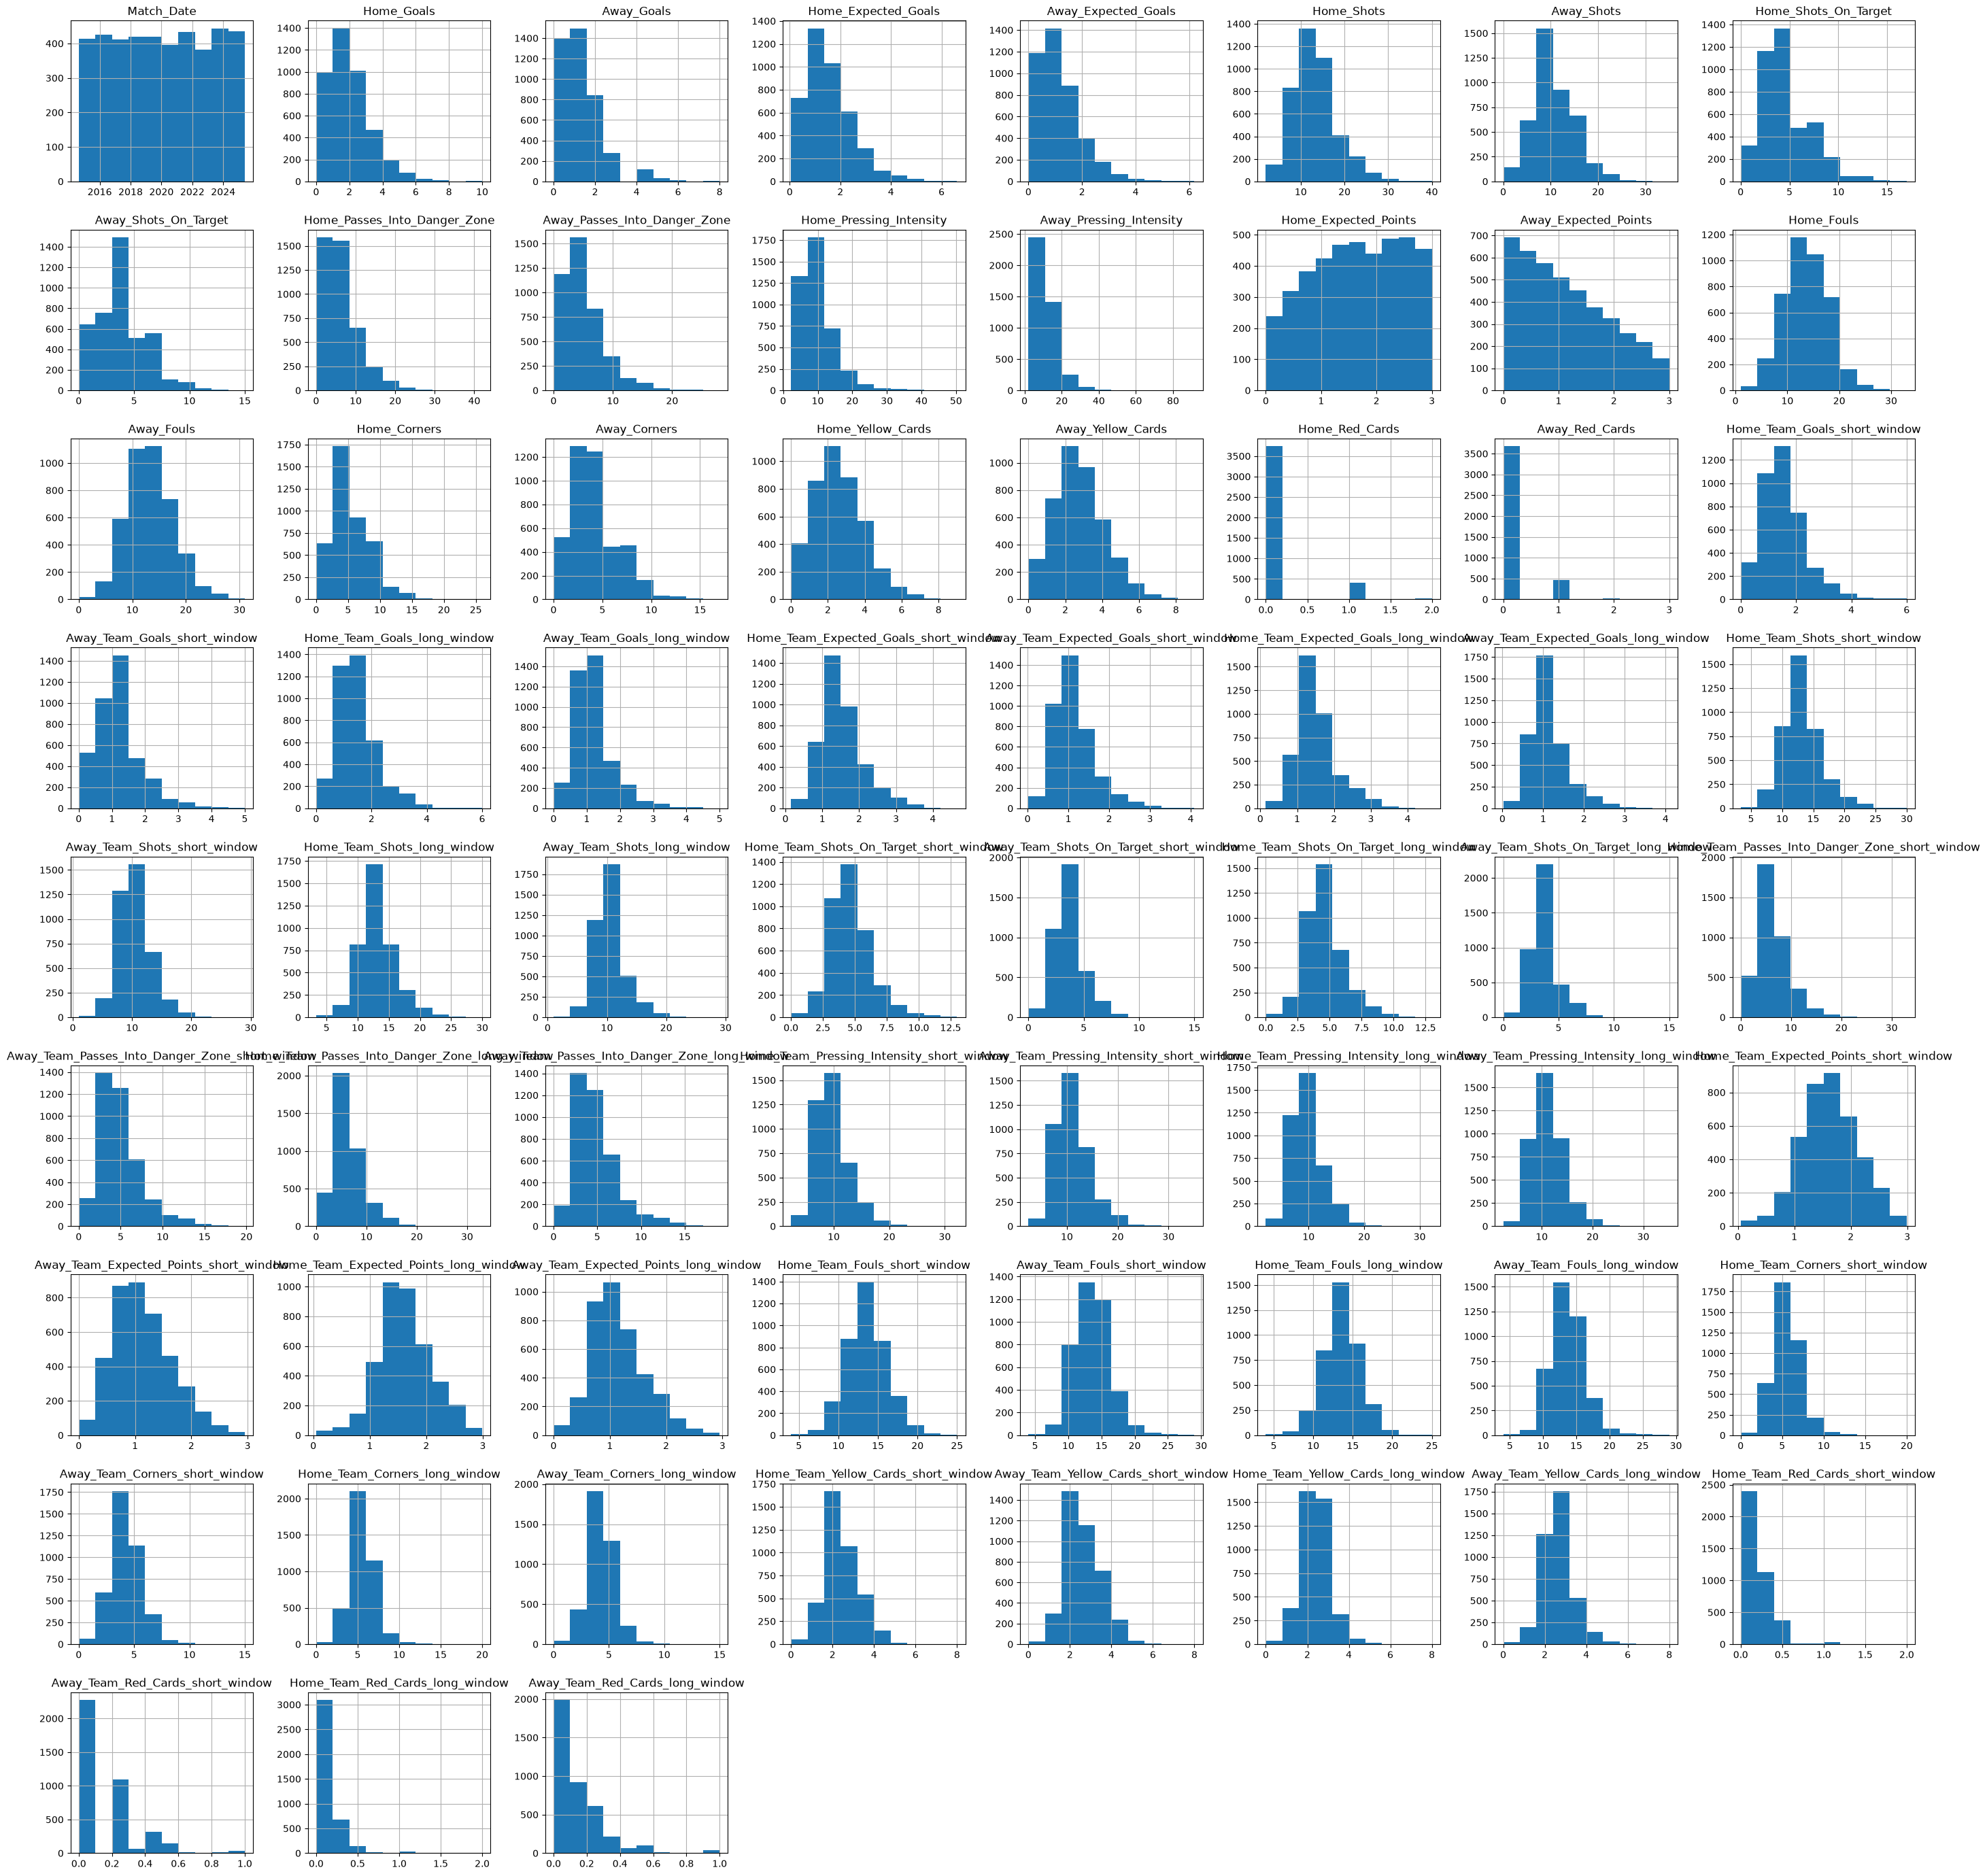

In [45]:
fig, ax = plt.subplots(1, 1, figsize=(35,35))
football_data.hist(ax=ax)


# Her starter EDA-fasen

Plotter alle features som histogrammer i én stor figur, for å få et raskt overblikk over fordelingen på tvers av alle kolonnene samtidig.

array([[<Axes: title={'center': 'Home_Goals'}>,
        <Axes: title={'center': 'Away_Goals'}>]], dtype=object)

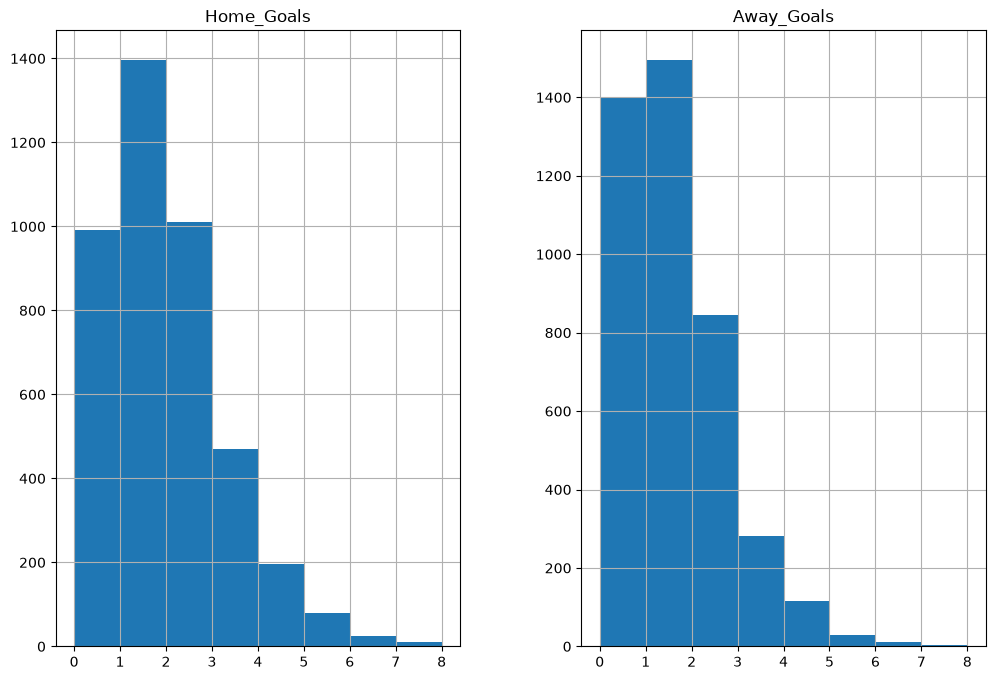

In [46]:
football_data[["Home_Goals", "Away_Goals"]].hist(bins=range(0,9), figsize=(12, 8))

## Histogram: mål scoret, hjemme vs. borte

Plotter fordelingen av `Home_Goals` og `Away_Goals` med én søyle per heltall (`bins=range(0,9)`), siden mål er en diskret variabel og vanlig automatisk binning ville gitt upresise intervaller.

**Funn:**
- I rundt 1400 av 4180 kamper scorer hjemmelaget mellom 1 og 2 mål
- Bortelaget scorer derimot mellom 0 og 1 mål i tilsvarende ~1400 kamper
- Hjemmelaget scorer 2-3 mål i litt over 1000 kamper, mens bortelaget kun gjør det samme i rundt 800 kamper

**Konklusjon:** Nok en tydelig visuell bekreftelse av home advantage – hele fordelingen for hjemmelaget er forskjøvet mot høyere målverdier sammenlignet med bortelaget, ikke bare snittet slik vi så i `describe()`.

<Axes: ylabel='Density'>

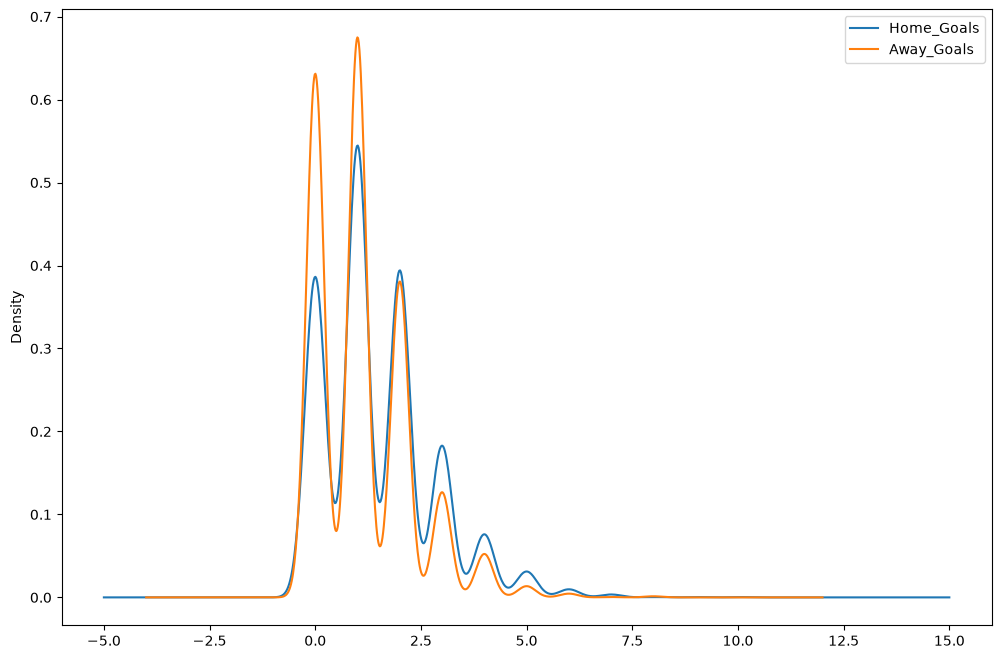

In [47]:
football_data[["Home_Goals", "Away_Goals"]].plot.kde(figsize=(12, 8)) #ind=np.arange(0, 9))

## KDE-plott: mål scoret, hjemme vs. borte

Prøver samme sammenligning med KDE (Kernel Density Estimation) i stedet for histogram.

**Konklusjon:** KDE-plott er egentlig ikke særlig praktisk for fotballmål, nettopp fordi fotballkamper består av diskrete data (heltall). Et lag kan score 0, 1 eller 2 mål, men aldri 1,4 eller -0,5 mål – KDE er laget for kontinuerlige variabler og glatter ut dataen på en måte som skaper kunstige "bølger" mellom heltallene. Histogram med `bins=range()` (som i forrige celle) er derfor et mer ærlig og presist verktøy for denne typen data.

array([[<Axes: title={'center': 'Home_Passes_Into_Danger_Zone'}>,
        <Axes: title={'center': 'Away_Passes_Into_Danger_Zone'}>]],
      dtype=object)

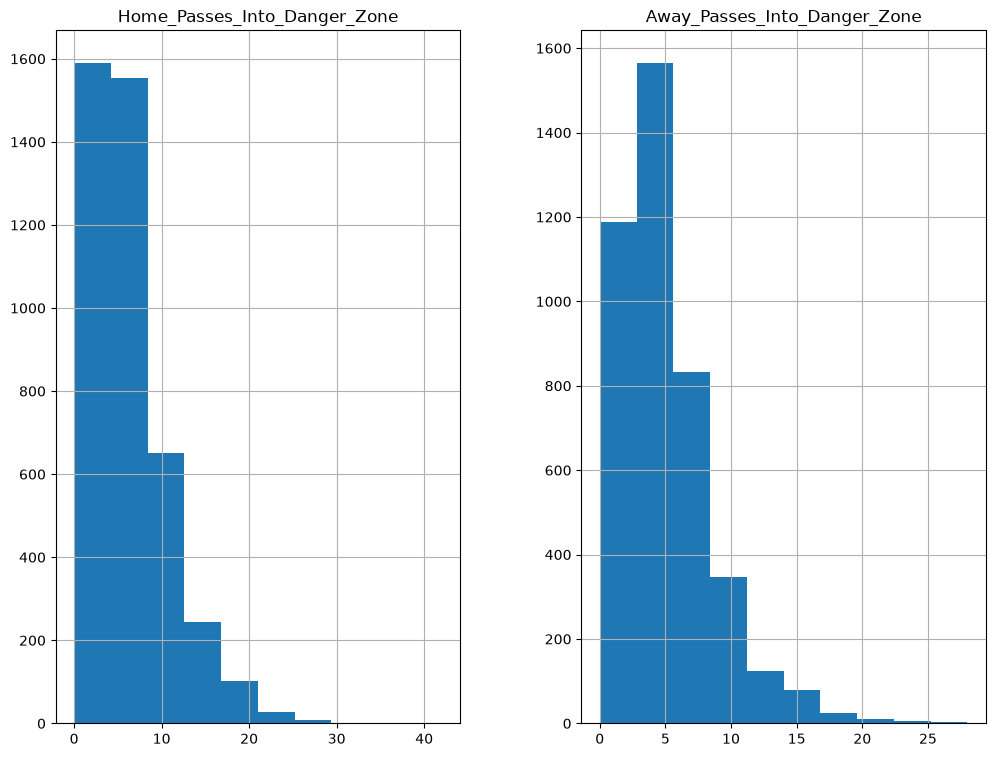

In [48]:
football_data[["Home_Passes_Into_Danger_Zone", "Away_Passes_Into_Danger_Zone"]].hist(figsize=(12, 9))

# Analyse av pasninger i faresonen

Sammenligning av `Home_Passes_Into_Danger_Zone` og `Away_Passes_Into_Danger_Zone`.

---

### Hovedfunn

* **Høyre-skjev fordeling:** For begge lagtyper ender de fleste kamper med under 10 pasninger i faresonen.
* **Høyere topp-potensial for hjemmelag:** Hjemmelag har kamper med opptil **~42** pasninger i feltet. Bortelag stopper rundt **~28**.
* **Mest vanlige intervall:**
  * **Hjemmelag:** Flest kamper ligger mellom 0 og 8 pasninger.
  * **Bortelag:** Tydelig topp mellom 3 og 6 pasninger.

---

### Sammenligning

| Lag | Vanligste antall | Maks observert |
| :--- | :--- | :--- |
| **Hjemmelag** | 0 – 8 | ~42 |
| **Bortelag** | 3 – 6 | ~28 |

---

### Konklusjon

Tallene reflekterer en tydelig hjemmefordel. Hjemmelag skaper i langt større grad kamper med høy intensitet og dominans i motstanderens felt.

<Axes: >

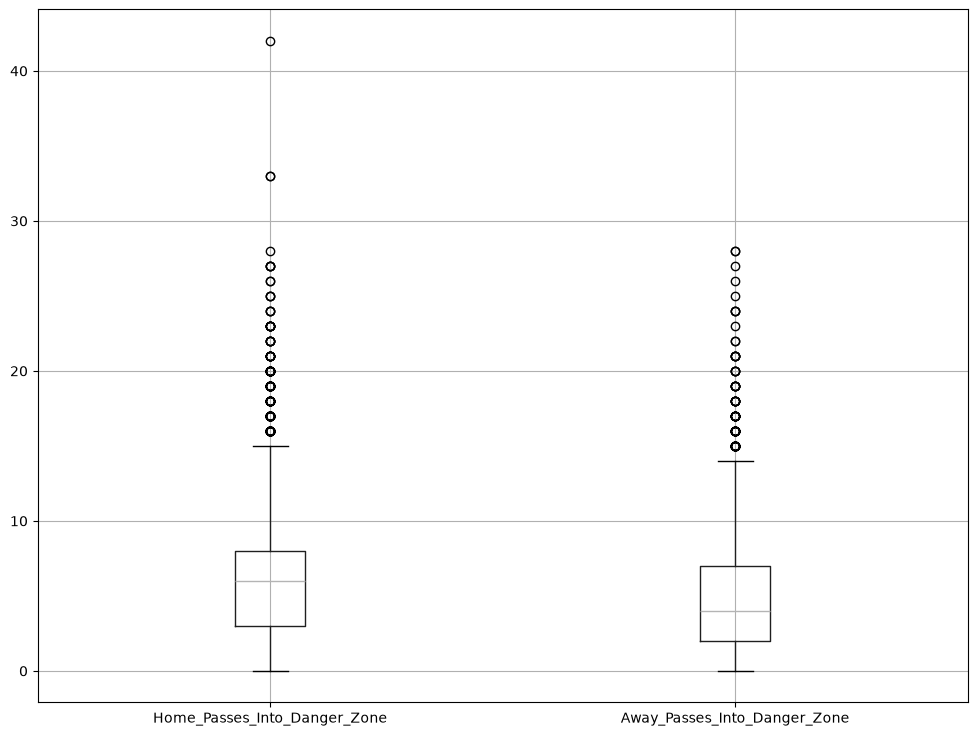

In [49]:
football_data[["Home_Passes_Into_Danger_Zone", "Away_Passes_Into_Danger_Zone"]].boxplot(figsize=(12, 9))

# Boxplot-analyse av pasninger i faresonen

Sammenligning av spredning, median og uteliggere (outliers) for `Home_Passes_Into_Danger_Zone` og `Away_Passes_Into_Danger_Zone`.

---

### Hvorfor boxplot egner seg godt her

* **Håndterer skjevfordeling:** Siden dataene er sterkt høyre-skjeve, gir boxplot et mye mer presist bilde av sentraltendensen (median) enn f.eks. et gjennomsnitt som blir påvirket av ekstremverdiene.
* **Tydeliggjør uteliggere:** Plotter gjør det enkelt å identifisere ekstremkamper (outliers) uten at de skjuler den generelle fordelingen.
* **Rask sammenligning:** Det gir en direkte visuell sammenligning av spredning (IQR), median og maksverdier mellom hjemme- og bortelag.

---

### Hovedfunn

* **Høyere median for hjemmelag:** Medianen (den grå linjen i boksen) ligger på rundt **6** pasninger for hjemmelag, mot ca. **4** for bortelag.
* **Større kvartilbredde (IQR):** Boksen til hjemmelag strekker seg fra ca. 3 til 8 pasninger, mens bortelaget ligger lavere, fra ca. 2 til 7.
* **Mange uteliggere (Outliers):** Begge variablene har en lang rekke ekstremverdier over den øvre "bartene" (ca. 14–15 pasninger).
* **Ekstremkamper:** Hjemmelag har en ekstrem uteligger helt oppe ved **42**, mens bortelag stopper ved **28**.

---

### Oppsummering av tallverdiene (Anslag)

| Metrikk | Hjemmelag | Bortelag |
| :--- | :--- | :--- |
| **Median** | ~6 | ~4 |
| **Boks (Q1 – Q3)** | ~3 – 8 | ~2 – 7 |
| **Maks utenom uteliggere** | ~15 | ~14 |
| **Høyeste uteligger** | ~42 | ~28 |

---

### Konklusjon

Boxplottet bekrefter at hjemmelag jevnt over har flere pasninger i faresonen enn bortelag. I tillegg viser de mange uteliggerne at enkelte kamper avviker kraftig fra normen med ekstremt høy sjansegenerering, spesielt for hjemmelaget.

In [50]:
correlation = football_data.drop(['Match_Date','Home_Team','Away_Team','Result', 'Season'], axis = 1).corr()
correlation

,Home_Goals,Away_Goals,Home_Expected_Goals,Away_Expected_Goals,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Passes_Into_Danger_Zone,Away_Passes_Into_Danger_Zone,Home_Pressing_Intensity,Away_Pressing_Intensity,Home_Expected_Points,Away_Expected_Points,Home_Fouls,Away_Fouls,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards,Home_Team_Goals_short_window,Away_Team_Goals_short_window,Home_Team_Goals_long_window,Away_Team_Goals_long_window,Home_Team_Expected_Goals_short_window,Away_Team_Expected_Goals_short_window,Home_Team_Expected_Goals_long_window,Away_Team_Expected_Goals_long_window,Home_Team_Shots_short_window,Away_Team_Shots_short_window,Home_Team_Shots_long_window,Away_Team_Shots_long_window,Home_Team_Shots_On_Target_short_window,Away_Team_Shots_On_Target_short_window,Home_Team_Shots_On_Target_long_window,Away_Team_Shots_On_Target_long_window,Home_Team_Passes_Into_Danger_Zone_short_window,Away_Team_Passes_Into_Danger_Zone_short_window,Home_Team_Passes_Into_Danger_Zone_long_window,Away_Team_Passes_Into_Danger_Zone_long_window,Home_Team_Pressing_Intensity_short_window,Away_Team_Pressing_Intensity_short_window,Home_Team_Pressing_Intensity_long_window,Away_Team_Pressing_Intensity_long_window,Home_Team_Expected_Points_short_window,Away_Team_Expected_Points_short_window,Home_Team_Expected_Points_long_window,Away_Team_Expected_Points_long_window,Home_Team_Fouls_short_window,Away_Team_Fouls_short_window,Home_Team_Fouls_long_window,Away_Team_Fouls_long_window,Home_Team_Corners_short_window,Away_Team_Corners_short_window,Home_Team_Corners_long_window,Away_Team_Corners_long_window,Home_Team_Yellow_Cards_short_window,Away_Team_Yellow_Cards_short_window,Home_Team_Yellow_Cards_long_window,Away_Team_Yellow_Cards_long_window,Home_Team_Red_Cards_short_window,Away_Team_Red_Cards_short_window,Home_Team_Red_Cards_long_window,Away_Team_Red_Cards_long_window
Home_Goals,1.000000,-0.039624,0.631685,-0.113427,0.256871,-0.040577,0.582576,-0.058251,0.324912,-0.115169,-0.009766,0.162850,0.479239,-0.442199,-0.106873,-0.059502,-0.009513,-0.018261,-0.138968,-0.019661,-0.086334,0.068195,0.226318,-0.117955,0.248357,-0.117555,0.266220,-0.139409,0.288326,-0.145712,0.229225,-0.096138,0.257308,-0.103827,0.242094,-0.106652,0.271125,-0.109097,0.301810,-0.138278,0.307012,-0.153384,-0.052618,0.038707,-0.063698,0.037805,0.211702,-0.164082,0.235479,-0.168806,-0.151101,0.046361,-0.165799,0.065175,0.150566,-0.052254,0.185058,-0.083844,-0.130355,0.018378,-0.127576,0.043212,-0.037064,0.027543,-0.032668,0.028817
Away_Goals,-0.039624,1.000000,-0.082886,0.638839,0.004151,0.285232,-0.030194,0.590622,-0.052806,0.305459,0.107713,-0.030498,-0.439607,0.476022,-0.019967,-0.048551,0.008562,-0.007918,0.062072,-0.034574,0.125584,-0.053030,-0.099270,0.177306,-0.099211,0.194453,-0.099991,0.226982,-0.105657,0.251076,-0.063407,0.201452,-0.075287,0.224042,-0.090879,0.195449,-0.088184,0.219720,-0.101863,0.260027,-0.102676,0.274526,0.016941,-0.061417,0.008326,-0.073270,-0.138646,0.213964,-0.139033,0.234973,0.014013,-0.147226,0.018421,-0.159843,-0.068216,0.113051,-0.070849,0.148417,0.032030,-0.069897,0.035894,-0.080845,0.017684,-0.013576,0.025047,-0.026029
Home_Expected_Goals,0.631685,-0.082886,1.000000,-0.149242,0.608028,-0.138283,0.673087,-0.124915,0.544524,-0.180785,-0.102933,0.280351,0.749245,-0.686463,-0.163152,-0.061025,0.231014,-0.140608,-0.157125,0.005402,-0.089299,0.101880,0.256984,-0.136551,0.280645,-0.145516,0.311519,-0.151232,0.342896,-0.161476,0.257031,-0.113201,0.296084,-0.126113,0.282531,-0.133950,0.317460,-0.135478,0.354224,-0.152361,0.366260,-0.170602,-0.031625,0.076777,-0.041759,0.087853,0.248941,-0.189293,0.284119,-0.196957,-0.177439,0.035019,-0.192280,0.050694,0.184297,-0.069539,0.221766,-0.099070,-0.128061,0.026836,-0.134964,0.040894,-0.034446,0.005750,-0.027997,0.002190
Away_Expected_Goals,-0.113427,0.638839,-0.149242,1.000000,-0.125772,0.614251,-0.107087,0.661625,-0.133753,0.524510,0.228013,-0.098416,-0.7

<Axes: >

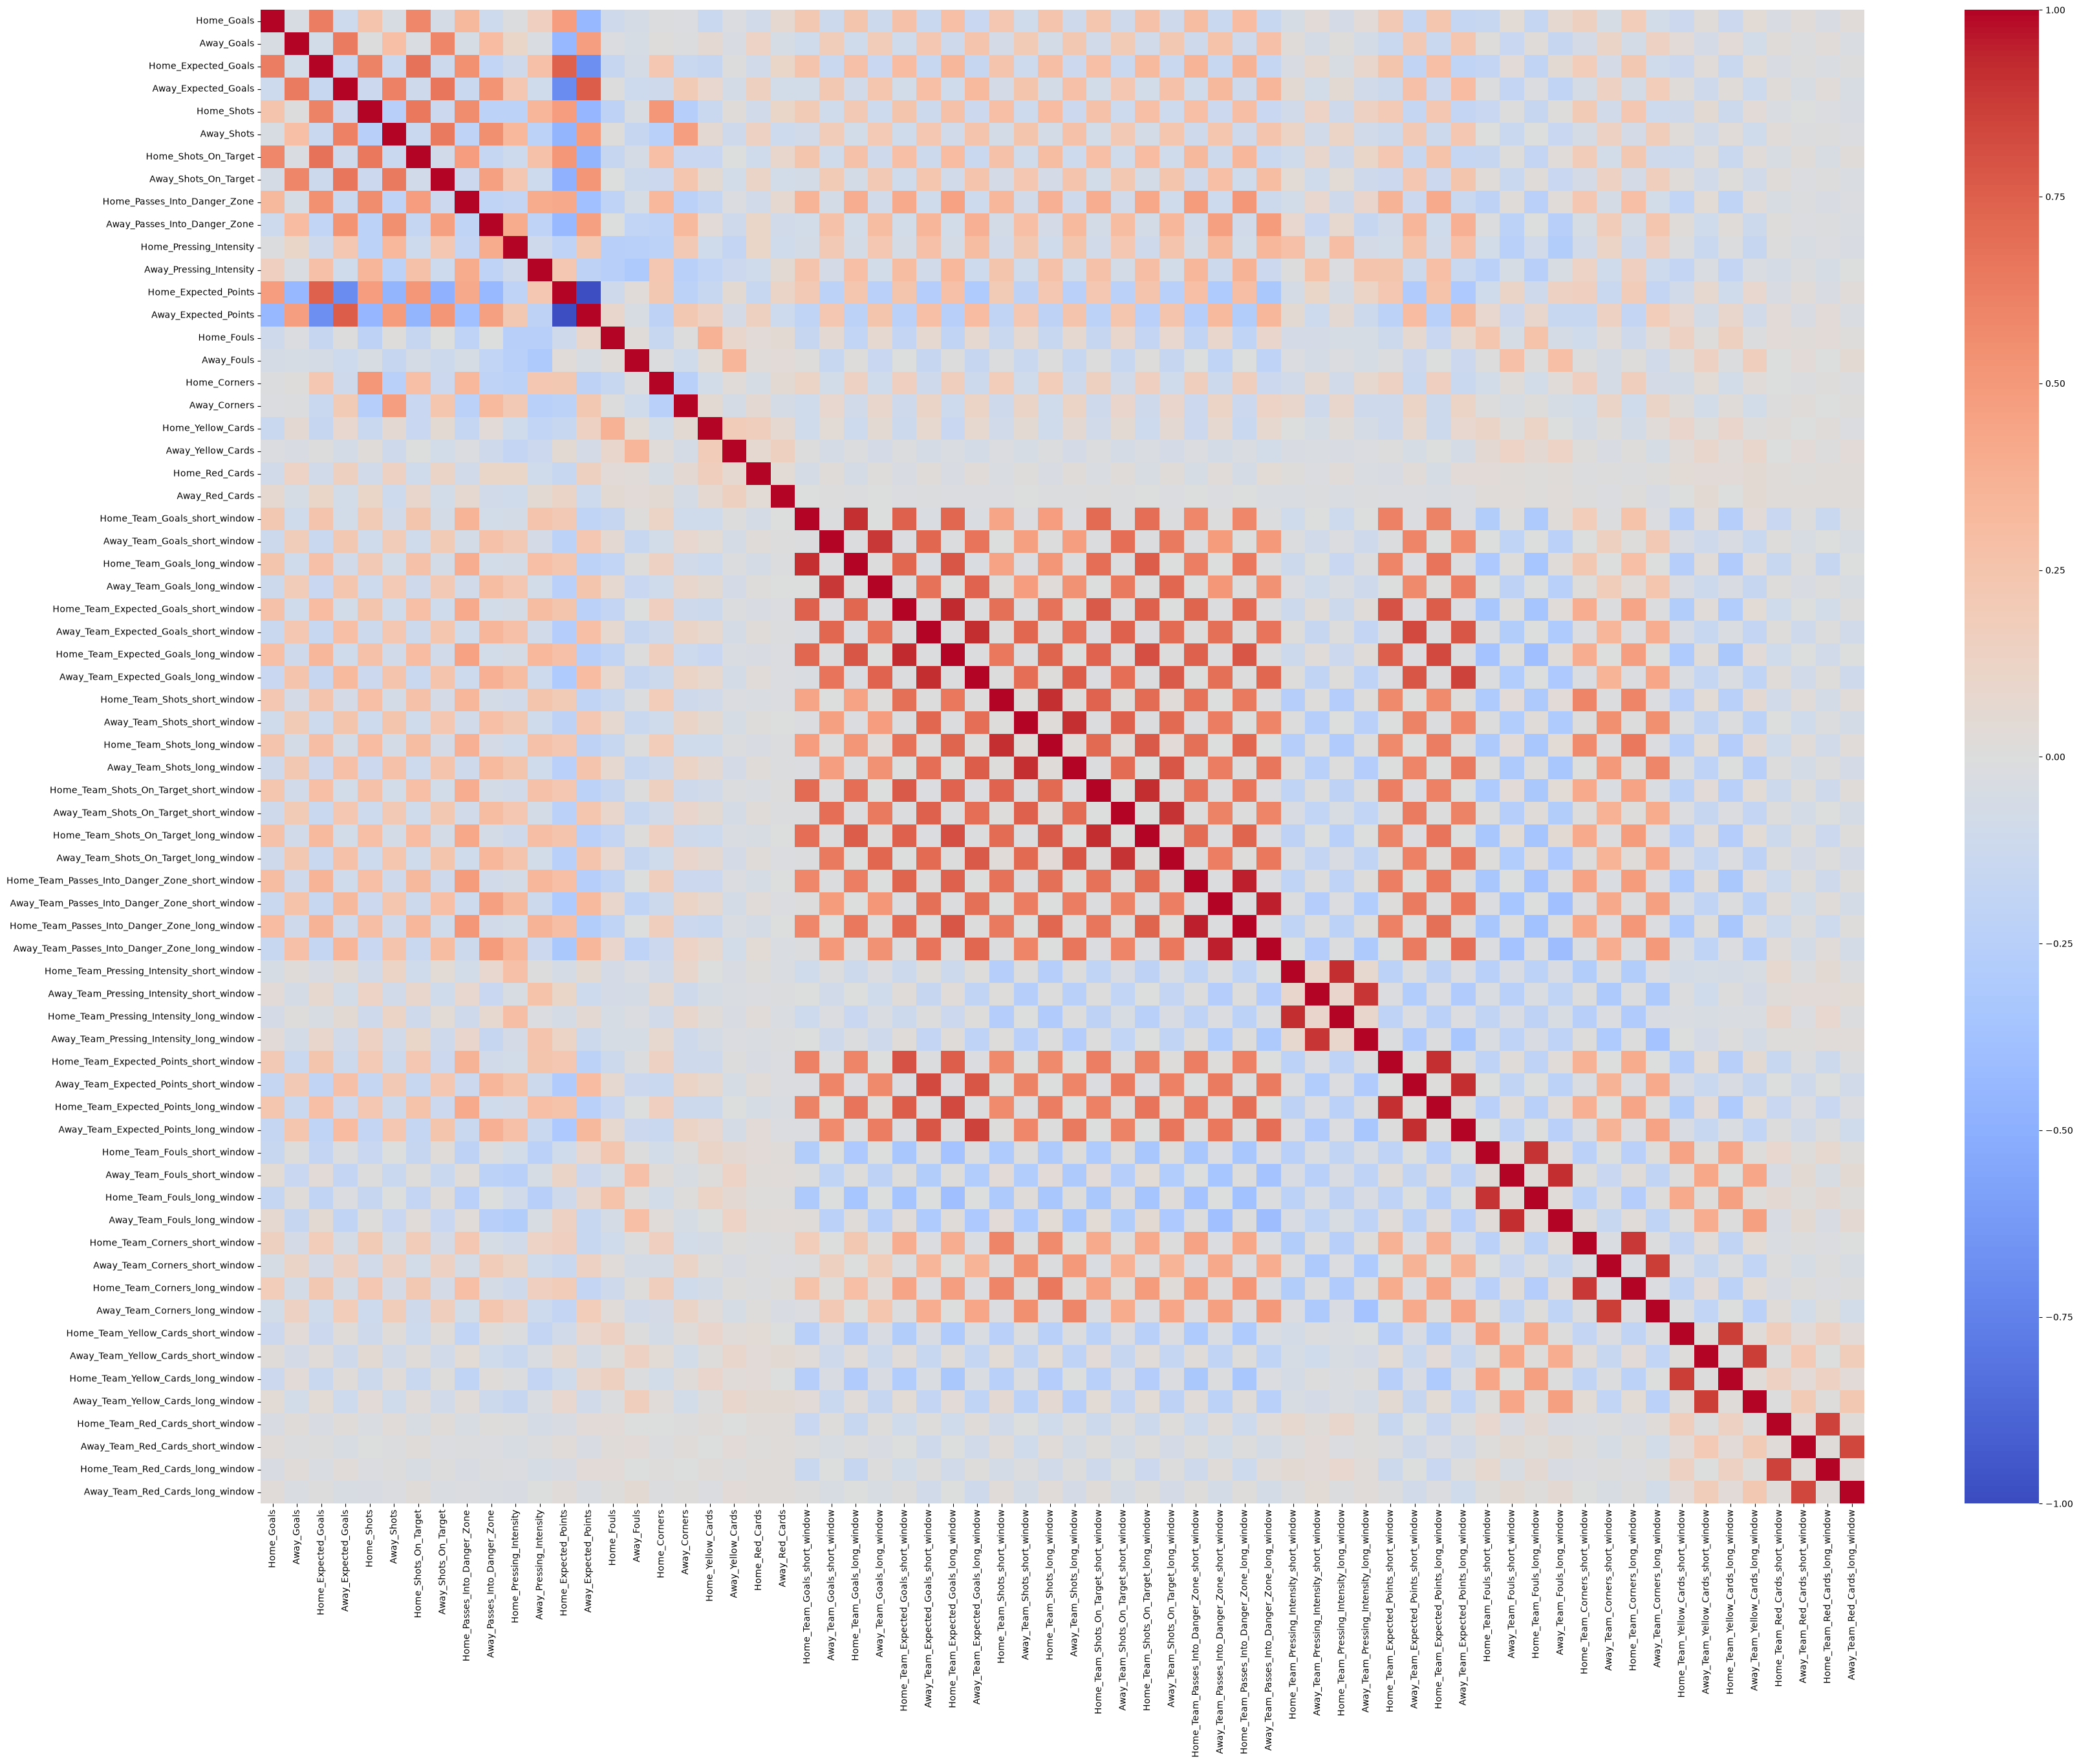

In [51]:
plt.figure(figsize=(40,30))
sb.heatmap(correlation, cmap="coolwarm", annot=False, vmin=-1, vmax=1)


In [52]:
corr_pairs = correlation.abs().unstack()
corr_pairs = corr_pairs[corr_pairs < 1.0] 
corr_pairs = corr_pairs.sort_values(ascending=False)
print(corr_pairs.head()) 

Away_Expected_Points                            Home_Expected_Points                              0.990609
Home_Expected_Points                            Away_Expected_Points                              0.990609
Home_Team_Passes_Into_Danger_Zone_long_window   Home_Team_Passes_Into_Danger_Zone_short_window    0.952161
Home_Team_Passes_Into_Danger_Zone_short_window  Home_Team_Passes_Into_Danger_Zone_long_window     0.952161
Away_Team_Passes_Into_Danger_Zone_short_window  Away_Team_Passes_Into_Danger_Zone_long_window     0.946822
dtype: float64


22


(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5]),
 [Text(0, 0.5, 'Home_Team_Goals_short_window'),
  Text(0, 1.5, 'Away_Team_Goals_short_window'),
  Text(0, 2.5, 'Home_Team_Expected_Goals_short_window'),
  Text(0, 3.5, 'Away_Team_Expected_Goals_short_window'),
  Text(0, 4.5, 'Home_Team_Shots_short_window'),
  Text(0, 5.5, 'Away_Team_Shots_short_window'),
  Text(0, 6.5, 'Home_Team_Shots_On_Target_short_window'),
  Text(0, 7.5, 'Away_Team_Shots_On_Target_short_window'),
  Text(0, 8.5, 'Home_Team_Passes_Into_Danger_Zone_short_window'),
  Text(0, 9.5, 'Away_Team_Passes_Into_Danger_Zone_short_window'),
  Text(0, 10.5, 'Home_Team_Pressing_Intensity_short_window'),
  Text(0, 11.5, 'Away_Team_Pressing_Intensity_short_window'),
  Text(0, 12.5, 'Home_Team_Expected_Points_short_window'),
  Text(0, 13.5, 'Away_Team_Expected_Points_short_window'),
  Text(0, 14.5, 'Home_Team_Fouls_short_window'),
  Tex

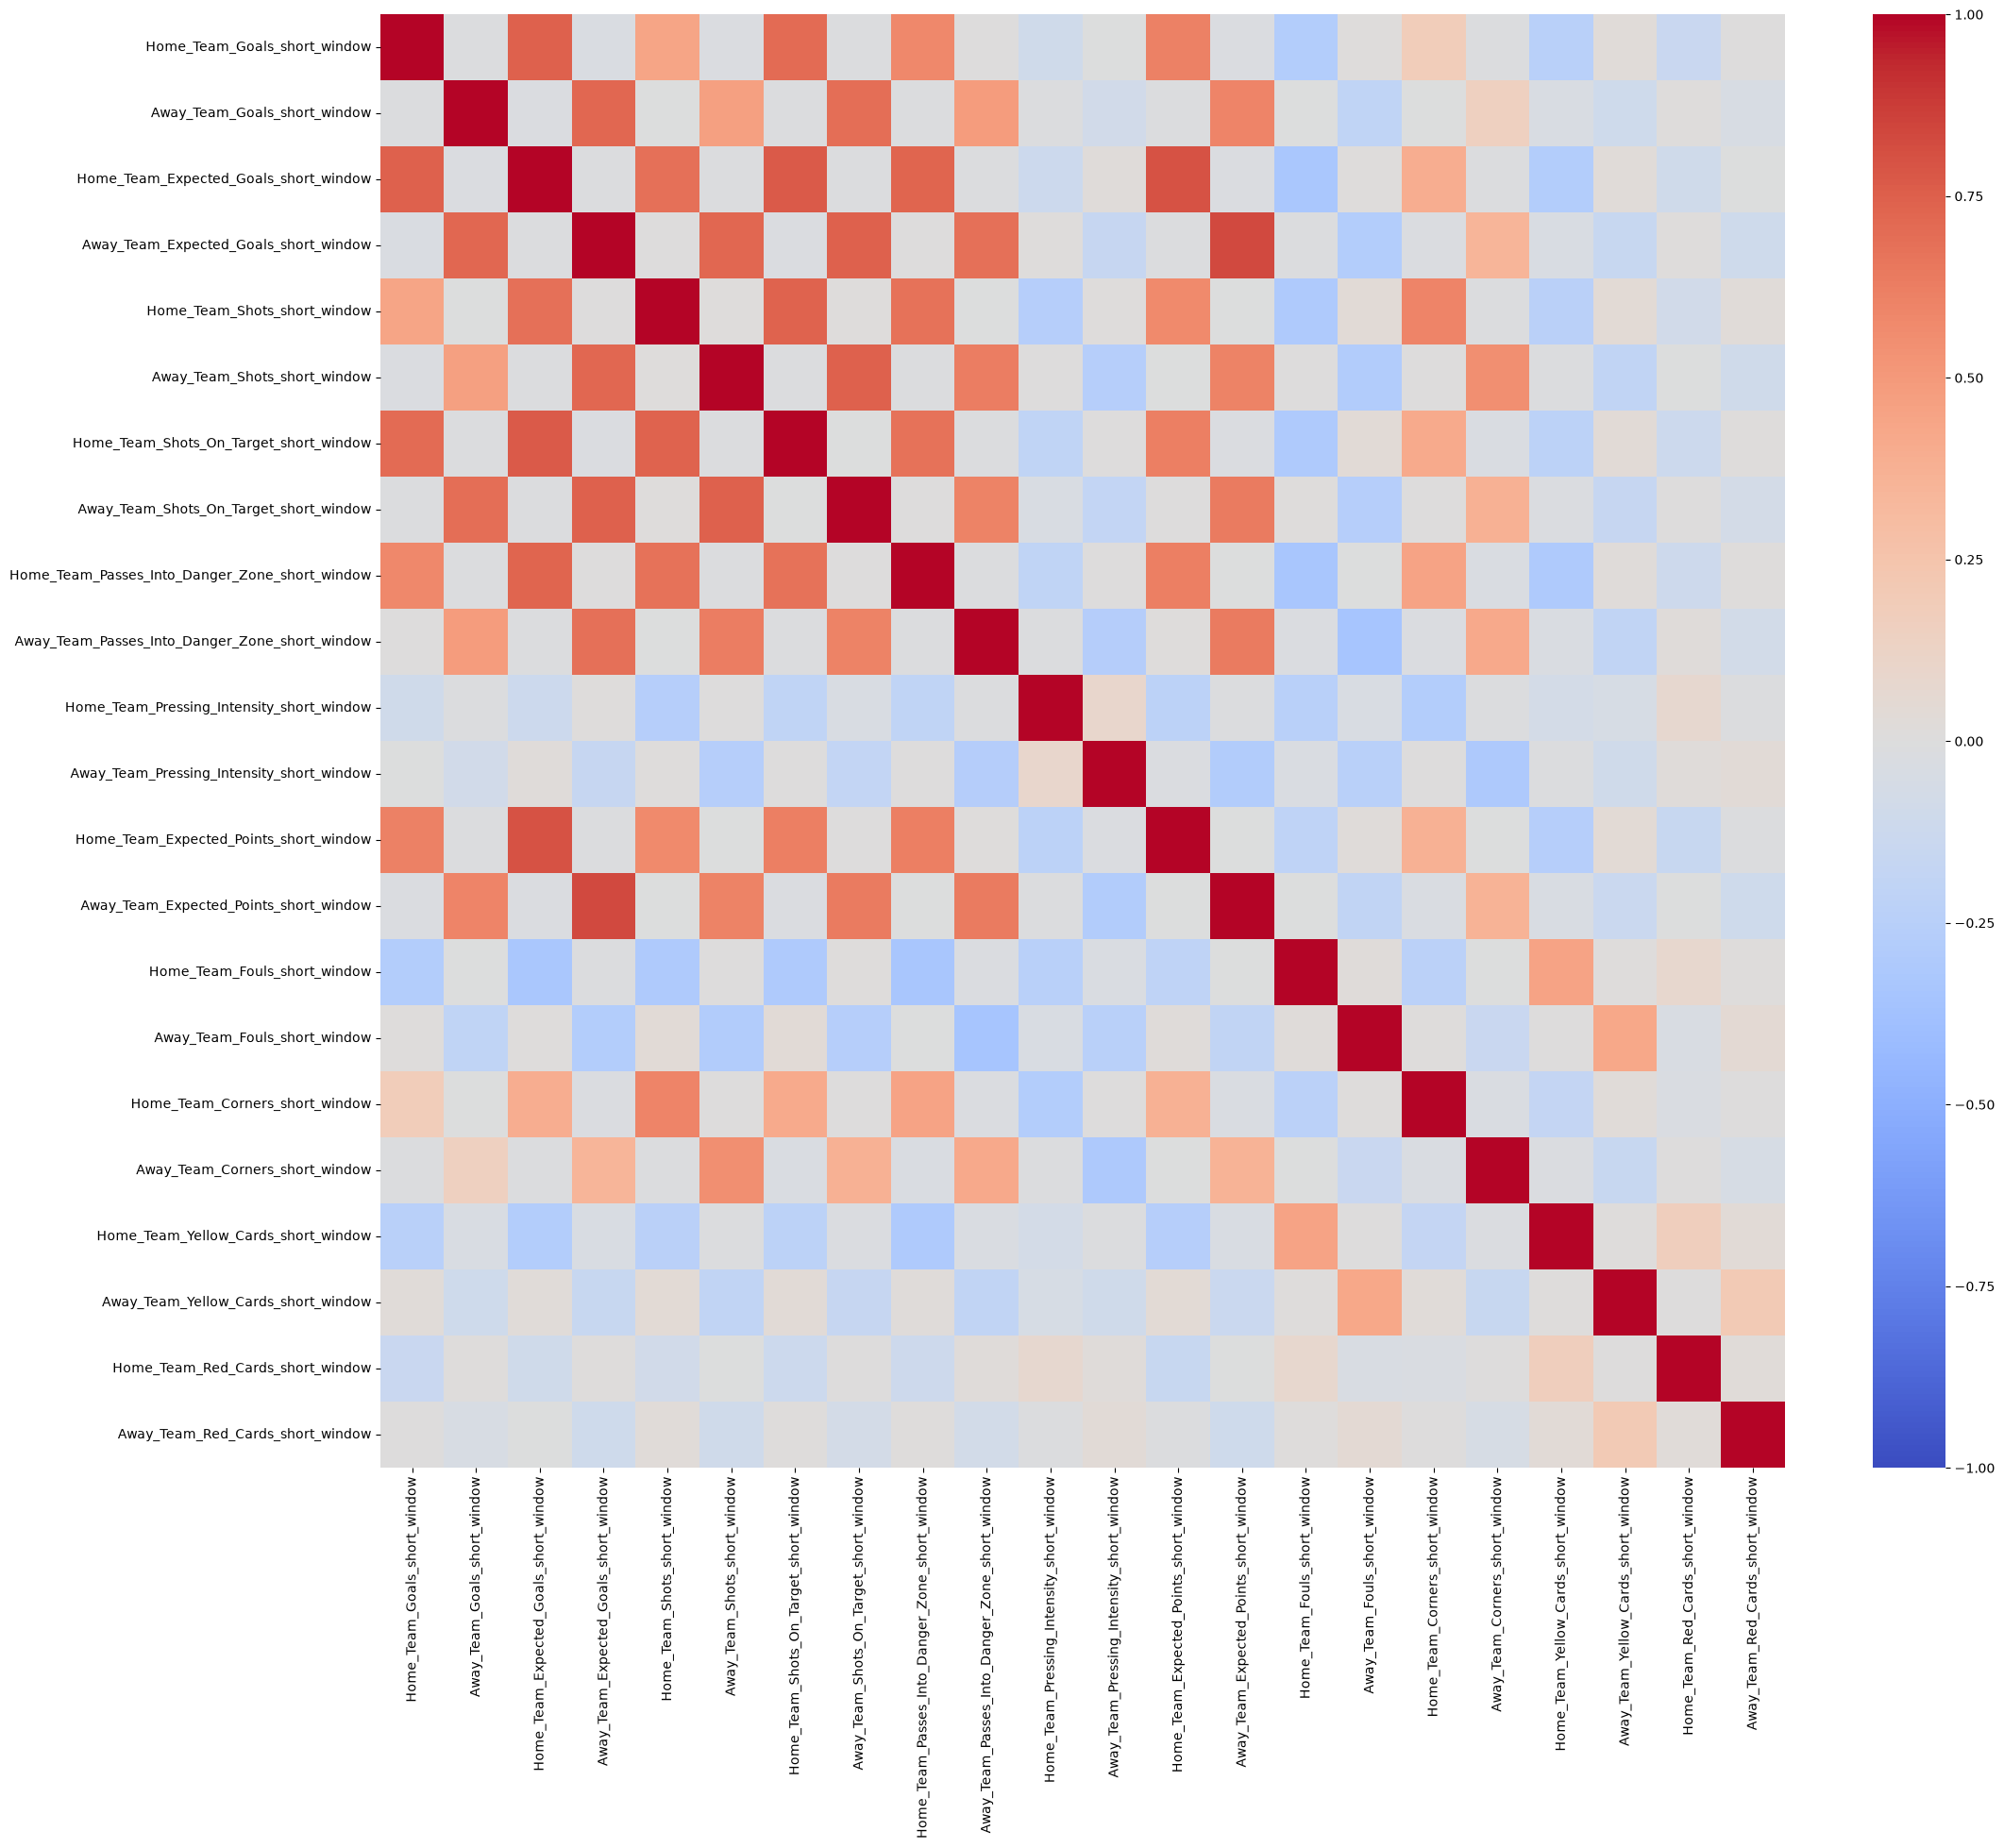

In [53]:
feature_columns = [col for col in football_data.columns if 'short' in col]
print(len(feature_columns))  

correlation_features = football_data[feature_columns].corr()

plt.figure(figsize=(24,20))
sb.heatmap(correlation_features, cmap="coolwarm", annot=False, vmin=-1, vmax=1)
plt.xticks(rotation=90)
plt.yticks(rotation=0)

22


(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5]),
 [Text(0, 0.5, 'Home_Team_Goals_long_window'),
  Text(0, 1.5, 'Away_Team_Goals_long_window'),
  Text(0, 2.5, 'Home_Team_Expected_Goals_long_window'),
  Text(0, 3.5, 'Away_Team_Expected_Goals_long_window'),
  Text(0, 4.5, 'Home_Team_Shots_long_window'),
  Text(0, 5.5, 'Away_Team_Shots_long_window'),
  Text(0, 6.5, 'Home_Team_Shots_On_Target_long_window'),
  Text(0, 7.5, 'Away_Team_Shots_On_Target_long_window'),
  Text(0, 8.5, 'Home_Team_Passes_Into_Danger_Zone_long_window'),
  Text(0, 9.5, 'Away_Team_Passes_Into_Danger_Zone_long_window'),
  Text(0, 10.5, 'Home_Team_Pressing_Intensity_long_window'),
  Text(0, 11.5, 'Away_Team_Pressing_Intensity_long_window'),
  Text(0, 12.5, 'Home_Team_Expected_Points_long_window'),
  Text(0, 13.5, 'Away_Team_Expected_Points_long_window'),
  Text(0, 14.5, 'Home_Team_Fouls_long_window'),
  Text(0, 15.5, 'Awa

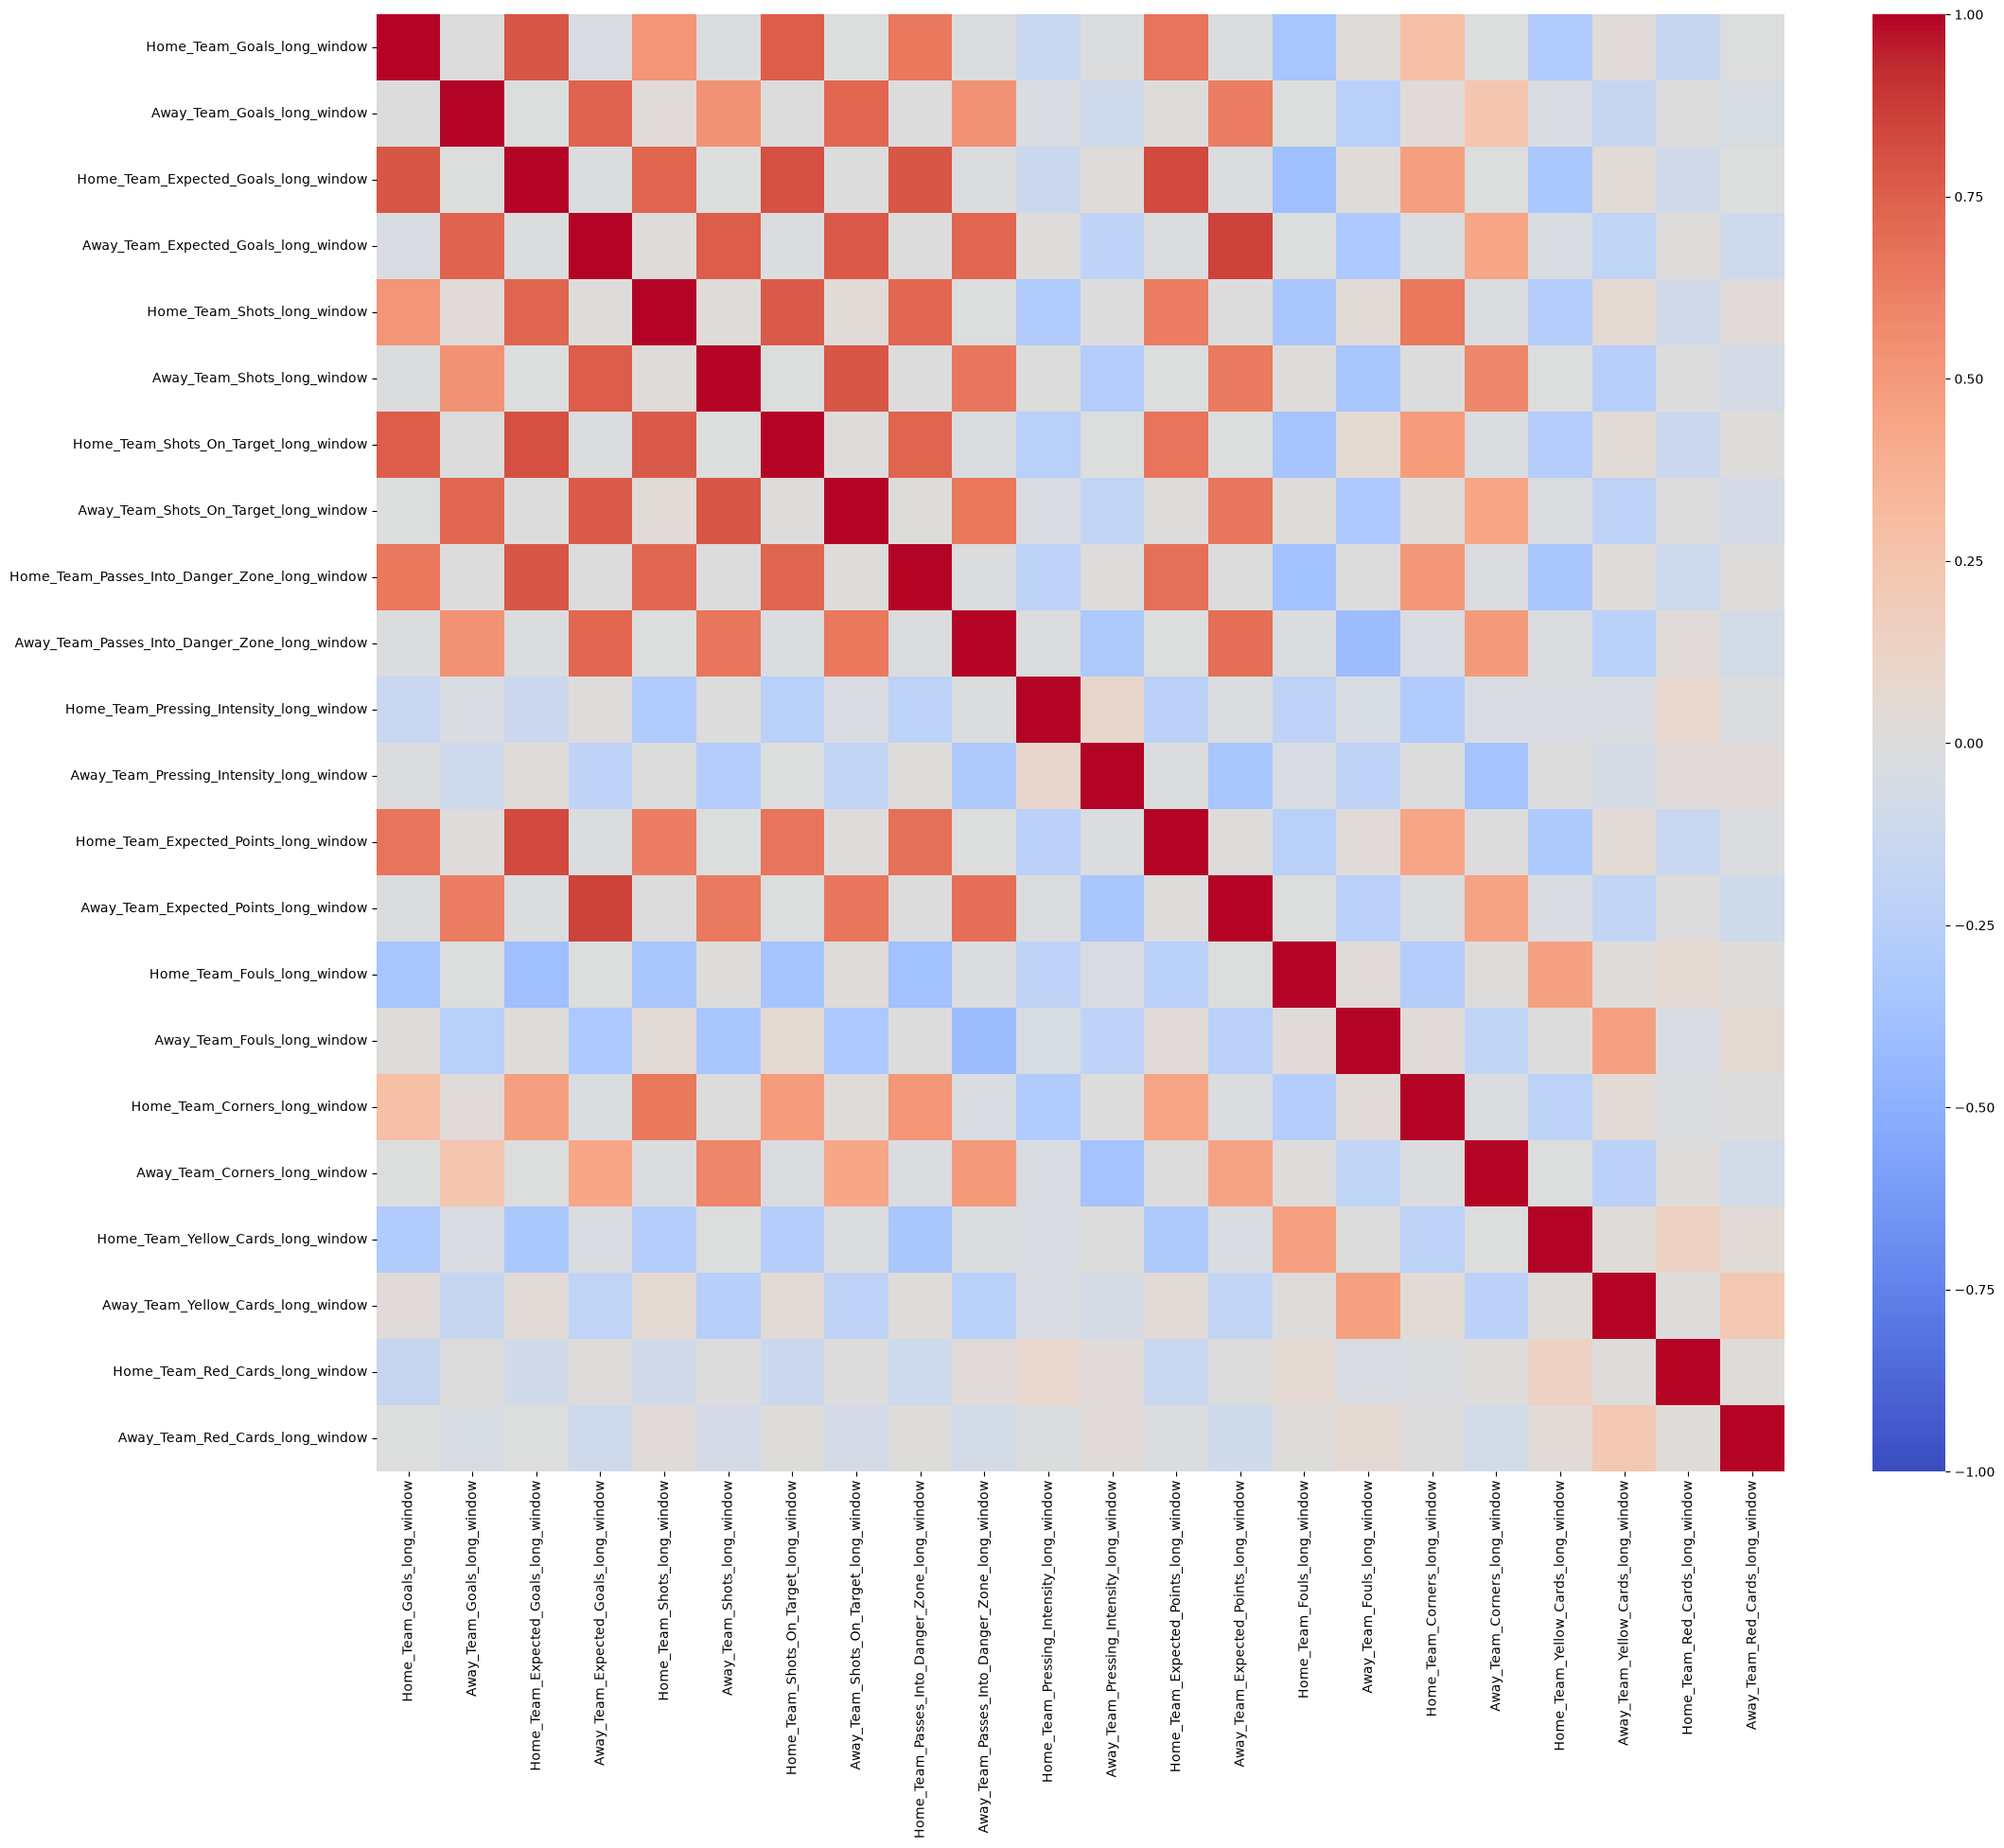

In [54]:
feature_columns = [col for col in football_data.columns if 'long' in col]
print(len(feature_columns))  

correlation_features = football_data[feature_columns].corr()

plt.figure(figsize=(24,20))
sb.heatmap(correlation_features, cmap="coolwarm", annot=False, vmin=-1, vmax=1)
plt.xticks(rotation=90)
plt.yticks(rotation=0)

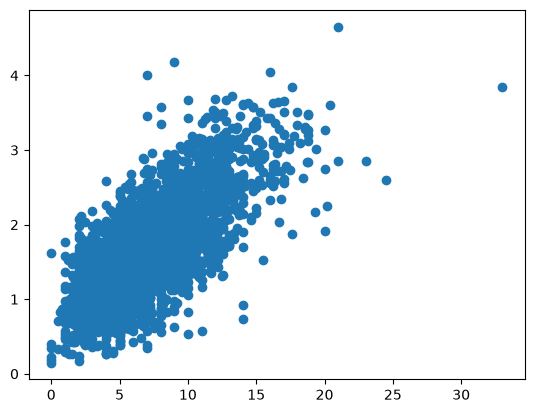

In [55]:
plt.scatter(football_data["Home_Team_Passes_Into_Danger_Zone_short_window"], football_data["Home_Team_Expected_Goals_short_window"])

### Sammenheng mellom Passes_Into_Danger_Zone og Expected_Goals

Sammenhengen er logisk: å komme seg inn i farlige områder er ofte selve forløperen til gode sjanser. Et lag som konsekvent klarer å spille seg inn nær motstanderens mål (høy `Passes_Into_Danger_Zone`) vil naturlig nok også skape sjanser av høyere kvalitet (høy `Expected_Goals`) — de to måler egentlig overlappende deler av samme angrepsprosess, bare på ulike stadier (posisjonering vs. selve sjansen).

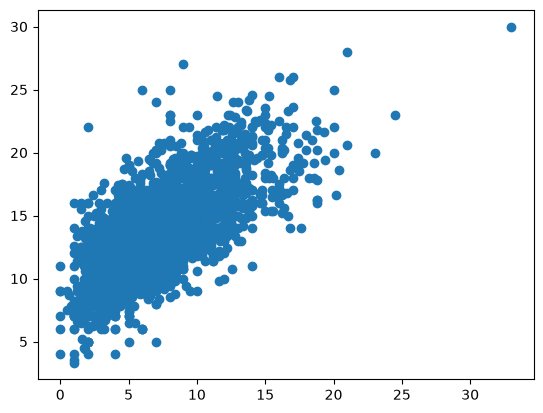

In [56]:
plt.scatter(football_data["Home_Team_Passes_Into_Danger_Zone_short_window"], football_data["Home_Team_Shots_short_window"])

In [57]:
football_data[["Home_Team_Passes_Into_Danger_Zone_short_window", "Home_Team_Expected_Goals_short_window"]].corr()

,Home_Team_Passes_Into_Danger_Zone_short_window,Home_Team_Expected_Goals_short_window
Home_Team_Passes_Into_Danger_Zone_short_window,1.000000,0.727636
Home_Team_Expected_Goals_short_window,0.727636,1.000000


In [58]:
football_data[["Home_Team_Passes_Into_Danger_Zone_long_window", "Home_Team_Expected_Goals_long_window"]].corr()

,Home_Team_Passes_Into_Danger_Zone_long_window,Home_Team_Expected_Goals_long_window
Home_Team_Passes_Into_Danger_Zone_long_window,1.000000,0.782591
Home_Team_Expected_Goals_long_window,0.782591,1.000000


In [59]:
football_data[["Home_Team_Corners_long_window", "Home_Team_Shots_long_window"]].corr()

,Home_Team_Corners_long_window,Home_Team_Shots_long_window
Home_Team_Corners_long_window,1.00000,0.65062
Home_Team_Shots_long_window,0.65062,1.00000


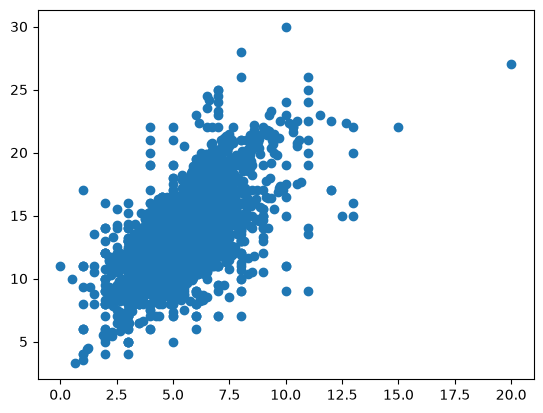

In [60]:
plt.scatter(football_data["Home_Team_Corners_long_window"], football_data["Home_Team_Shots_long_window"])

In [61]:
football_data[["Home_Team_Goals_short_window", "Home_Team_Shots_On_Target_short_window"]].corr()

,Home_Team_Goals_short_window,Home_Team_Shots_On_Target_short_window
Home_Team_Goals_short_window,1.000000,0.705143
Home_Team_Shots_On_Target_short_window,0.705143,1.000000


In [62]:
football_data[["Home_Team_Corners_short_window", "Home_Team_Goals_short_window"]].corr()

,Home_Team_Corners_short_window,Home_Team_Goals_short_window
Home_Team_Corners_short_window,1.000000,0.183616
Home_Team_Goals_short_window,0.183616,1.000000


## Korrelasjonsanalyse på de historiske featurene

Sammenlignet korrelasjonen for både korte (5 kamper) og lange (20 kamper) vinduer — mønsteret var konsistent mellom dem, ingen av funnene var overraskende i seg selv.

**Funn 1: Passes_Into_Danger_Zone og Expected_Goals er sterkt korrelert (0.73 kort vindu, 0.78 langt vindu)**

Gir god fotballfaglig mening — å spille seg inn i farlige områder er ofte selve forløperen til gode målsjanser, så de to måler delvis samme underliggende ting (angrepskvalitet), bare på ulike stadier av angrepet.

**Funn 2: Corners og Shots er også korrelert (0.65 langt vindu)**

Samme mønster — flere hjørnespark henger naturlig sammen med mer press/flere angrep, som igjen gir flere skudd.

**Konklusjon — mulig redundans:** Begge funn peker på noe jeg var bekymret for allerede tidlig i feature engineering-fasen: sterkt korrelerte features gir **delvis redundant** informasjon til modellen. Dette er kandidater for å vurdere å fjerne en av hvert par senere, eller bruke PCA for dimensjonsreduksjon.

**Viktig presisering: korrelasjon MELLOM features ≠ korrelasjon MELLOM en feature og target**

- Høy korrelasjon **mellom to features** (som funnene over) er et tegn på **redundans** — de to featurene bidrar delvis med samme informasjon, uten at det nødvendigvis gjør noen av dem dårlige.
- Høy korrelasjon **mellom en feature og target** er derimot **ønskelig** — det betyr featureren faktisk samvarierer med utfallet vi prøver å predikere. Dette betyr **ikke** at featureren "forårsaker" utfallet (korrelasjon er ikke kausalitet) — mer sannsynlig er både featureren og target påvirket av en felles bakenforliggende faktor (f.eks. "lagstyrke" påvirker både xG og sannsynligheten for seier). Poenget er at modellen kan **utnytte** denne sammenhengen til å skille klassene fra hverandre, uavhengig av den underliggende årsaken.

Siden `Result` er kategorisk (ikke et tall), kan ikke feature-til-target-korrelasjon sjekkes med vanlig `.corr()` direkte — dette bør heller undersøkes med boxplot gruppert på `Result`, eller ved å korrelere mot en encodet versjon av targeten.

<Axes: xlabel='Result', ylabel='Away_Team_Expected_Goals_long_window'>

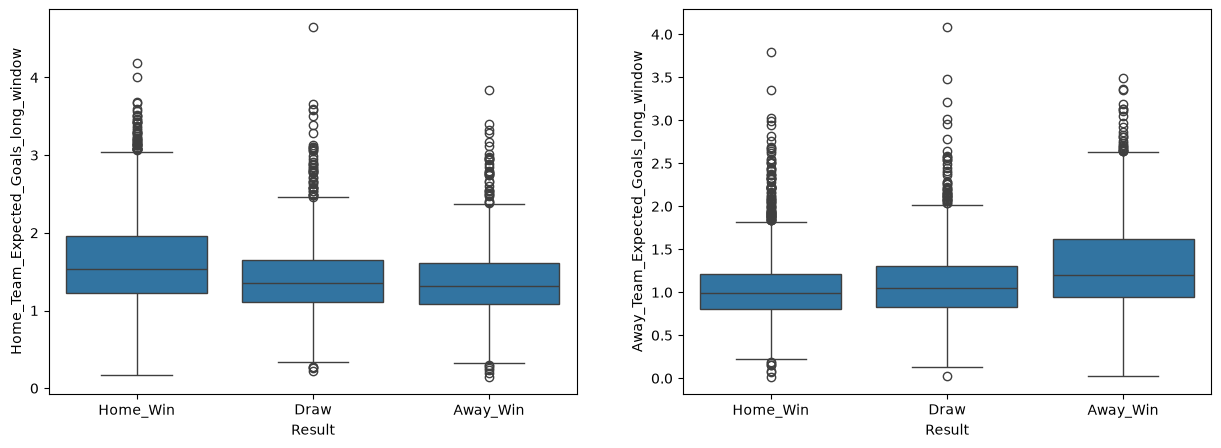

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(15,5))
sb.boxplot(x=football_data["Result"], y=football_data["Home_Team_Expected_Goals_long_window"], ax=ax[0])
sb.boxplot(x=football_data["Result"], y=football_data["Away_Team_Expected_Goals_long_window"], ax=ax[1])

### Boxplot: xG-form vs. kampresultat — sammenheng mellom feature og target

**Hvorfor vi ser på dette:**
`Result` er kategorisk, så vanlig `.corr()` fungerer ikke direkte for å sjekke feature-til-target-sammenheng.
Boxplot gruppert på `Result` er alternativet — det viser om fordelingen av en numerisk feature faktisk
skifter avhengig av hvilket utfall kampen fikk. Skifter den, har featuren predikativt signal.

**Hva vi ser:**
Medianene for xG-form endrer seg tydelig mellom kategoriene:

| Result   | Home_Team xG (median) | Away_Team xG (median) |
|----------|------------------------|------------------------|
| Home_Win | 1.53                   | 0.99                   |
| Draw     | 1.35                   | 1.05                   |
| Away_Win | 1.32                   | 1.20                   |

Begge featurene er høyest nettopp når det aktuelle laget selv vinner — akkurat mønsteret vi vil se,
siden det betyr featuren faktisk skiller mellom utfallene i stedet for å overlappe likt.

**Tolkning — marginen er ikke symmetrisk:**
- Ved **Home_Win** ligger hjemmelagets xG-form 0.54 over bortelagets (1.53 vs. 0.99) — et tydelig gap.
- Ved **Away_Win** ligger hjemmelagets xG-form fortsatt 0.12 *over* bortelagets (1.32 vs. 1.20),
  selv om bortelaget vant kampen.

Dette stemmer med "home advantage": å spille hjemme løfter et lags underliggende formnivå
uavhengig av motstander. En bortelagsseier skjer dermed litt "mot strømmen" av form, mens en
hjemmeseier reflekterer et klarere kvalitetsovertak i utgangspunktet.


In [ ]:
#https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html
le = LabelEncoder()
football_data["Encoded_Result"]=le.fit_transform(football_data["Result"])

# Label encoding av target

Modellene i scikit-learn jobber med tall, ikke tekststrenger — så `Result`
(`Home_Win`/`Draw`/`Away_Win`) må gjøres om til numerisk før trening.
Bruker `LabelEncoder` til dette.


In [65]:
football_data.head(10)

,Match_Date,Home_Team,Away_Team,Home_Goals,Away_Goals,Home_Expected_Goals,Away_Expected_Goals,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Passes_Into_Danger_Zone,Away_Passes_Into_Danger_Zone,Home_Pressing_Intensity,Away_Pressing_Intensity,Home_Expected_Points,Away_Expected_Points,Season,Home_Fouls,Away_Fouls,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards,Result,Home_Team_Goals_short_window,Away_Team_Goals_short_window,Home_Team_Goals_long_window,Away_Team_Goals_long_window,Home_Team_Expected_Goals_short_window,Away_Team_Expected_Goals_short_window,Home_Team_Expected_Goals_long_window,Away_Team_Expected_Goals_long_window,Home_Team_Shots_short_window,Away_Team_Shots_short_window,Home_Team_Shots_long_window,Away_Team_Shots_long_window,Home_Team_Shots_On_Target_short_window,Away_Team_Shots_On_Target_short_window,Home_Team_Shots_On_Target_long_window,Away_Team_Shots_On_Target_long_window,Home_Team_Passes_Into_Danger_Zone_short_window,Away_Team_Passes_Into_Danger_Zone_short_window,Home_Team_Passes_Into_Danger_Zone_long_window,Away_Team_Passes_Into_Danger_Zone_long_window,Home_Team_Pressing_Intensity_short_window,Away_Team_Pressing_Intensity_short_window,Home_Team_Pressing_Intensity_long_window,Away_Team_Pressing_Intensity_long_window,Home_Team_Expected_Points_short_window,Away_Team_Expected_Points_short_window,Home_Team_Expected_Points_long_window,Away_Team_Expected_Points_long_window,Home_Team_Fouls_short_window,Away_Team_Fouls_short_window,Home_Team_Fouls_long_window,Away_Team_Fouls_long_window,Home_Team_Corners_short_window,Away_Team_Corners_short_window,Home_Team_Corners_long_window,Away_Team_Corners_long_window,Home_Team_Yellow_Cards_short_window,Away_Team_Yellow_Cards_short_window,Home_Team_Yellow_Cards_long_window,Away_Team_Yellow_Cards_long_window,Home_Team_Red_Cards_short_window,Away_Team_Red_Cards_short_window,Home_Team_Red_Cards_long_window,Away_Team_Red_Cards_long_window,Encoded_Result
0,2014-08-23,Malaga,Athletic Club,1,0,1.32,1.14,12,12,3,5,4,5,12.07,6.30,1.53,1.14,2014-15,13.0,9.0,5.0,4.0,3.0,3.0,2.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
1,2014-08-23,Sevilla,Valencia,1,1,1.17,1.75,12,11,3,1,8,4,9.42,10.65,0.89,1.82,2014-15,23.0,8.0,3.0,3.0,4.0,2.0,0.0,1.0,Draw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,2014-08-23,Granada,Deportivo La Coruna,2,1,0.55,0.38,10,8,3,1,2,4,4.78,5.80,1.45,1.08,2014-15,13.0,26.0,5.0,3.0,1.0,2.0,0.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
3,2014-08-23,Almeria,Espanyol,1,1,0.98,0.40,19,12,6,2,5,4,6.67,15.80,1.88,0.77,2014-15,8.0,9.0,11.0,7.0,3.0,2.0,0.0,1.0,Draw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,2014-08-24,Eibar,Real Sociedad,1,0,0.47,0.98,12,19,5,4,4,1,8.79,6.67,0.83,1.81,2014-15,13.0,14.0,5.0,6.0,4.0,1.0,0.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
5,2014-08-24,Barcelona,Elche,3,0,1.54,0.11,12,3,6,0,12,0,6.55,18.39,2.60,0.22,2014-15,11.0,13.0,3.0,1.0,0.0,1.0,1.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
6,2014-08-24,Celta Vigo,Getafe,3,1,1.92,0.67,20,12,9,3,9,4,5.38,12.40,2.32,0.49,2014-15,19.0,15.0,4.0,4.0,4.0,1.0,0.0,0.0,Home_Win,NaN,NaN,NaN,NaN,NaN,NaN

## **Resultat av kodingen:**
Away_Win = 0
Draw = 1
Home_Win = 2

`LabelEncoder` sorterer de unike verdiene alfabetisk og tildeler 0, 1, 2, ... i den
rekkefølgen — det er derfor `Away_Win` (A) blir 0 og `Home_Win` (H) blir 2, ikke fordi
det ligger noe rangering i selve resultatene.

**Hvorfor dette er trygt å gjøre FØR splitting** (i motsetning til target encoding av
lagnavnene, som må vente til etter splitting): denne kodingen bruker ikke noe statistikk
fra dataen — ingen gjennomsnitt, ingen telling, ingen fordeling. Den bare tildeler et fast
tall til hver av de 3 mulige kategoriene. Samme 3 kategorier finnes i alle splittene, så
mappingen blir identisk uansett om man fitter på hele datasettet eller kun treningssettet.
Ingen data leakage-risiko her.

Neste steg: splitte dataene i train/val/test, og deretter target-encode `Home_Team`/`Away_Team`
mot denne nye `Encoded_Result`-kolonnen — kun basert på treningssettet.

In [66]:
features_columns = [col for col in football_data.columns if 'window' in col]
print(len(features_columns))
print(features_columns)
features = football_data[features_columns]
target = football_data["Encoded_Result"]

44
['Home_Team_Goals_short_window', 'Away_Team_Goals_short_window', 'Home_Team_Goals_long_window', 'Away_Team_Goals_long_window', 'Home_Team_Expected_Goals_short_window', 'Away_Team_Expected_Goals_short_window', 'Home_Team_Expected_Goals_long_window', 'Away_Team_Expected_Goals_long_window', 'Home_Team_Shots_short_window', 'Away_Team_Shots_short_window', 'Home_Team_Shots_long_window', 'Away_Team_Shots_long_window', 'Home_Team_Shots_On_Target_short_window', 'Away_Team_Shots_On_Target_short_window', 'Home_Team_Shots_On_Target_long_window', 'Away_Team_Shots_On_Target_long_window', 'Home_Team_Passes_Into_Danger_Zone_short_window', 'Away_Team_Passes_Into_Danger_Zone_short_window', 'Home_Team_Passes_Into_Danger_Zone_long_window', 'Away_Team_Passes_Into_Danger_Zone_long_window', 'Home_Team_Pressing_Intensity_short_window', 'Away_Team_Pressing_Intensity_short_window', 'Home_Team_Pressing_Intensity_long_window', 'Away_Team_Pressing_Intensity_long_window', 'Home_Team_Expected_Points_short_window'

### Velger ut featurene og separerer fra target

**Hva jeg gjør:**
Plukker ut alle kolonnene som inneholder `"window"` i navnet — det er nettopp de 44
rolling-window-featurene jeg bygde i feature engineering-steget helt i starten(alle på formatet
`Home_/Away_Team_<stat>_<short/long>_window`). Filteret fungerer fordi det er den eneste
kolonnegruppen med dette navnemønsteret i datasettet.

**Hvorfor akkurat disse kolonnene:** de er de eneste featurene som faktisk er trygge å
bruke — bygget med `closed='left'` slik at ingen av dem inneholder informasjon fra selve
kampen de skal predikere (se data leakage-diskusjonen tidligere). Rå kolonner som
`Home_Goals`/`Away_Goals` skal IKKE være med her, siden de er fasiten for kampen selv.

**Splitter i X og y:**
- `features` (X) = de 44 rolling-window-kolonnene
- `target` (y) = `Encoded_Result`, den numeriske versjonen av `Result`

Dette er standard oppsett før train/val/test-splitting og modelltrening.

In [67]:
football_data["Result"].value_counts()

Result
Home_Win    1897
Away_Win    1197
Draw        1086
Name: count, dtype: int64

In [68]:
print(football_data["Season"].unique())
football_data["Result"].value_counts()


<StringArray>
['2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21',
 '2021-22', '2022-23', '2023-24', '2024-25']
Length: 11, dtype: str


Result
Home_Win    1897
Away_Win    1197
Draw        1086
Name: count, dtype: int64

# Valg av splitting-strategi: sesong-basert vs. stratifisert

**Problem:**
Forelser (Lars Vidar) anbefaler stratifisert splitting for å balansere den skjeve
klassefordelingen i `Result` (Home_Win: 1897, Away_Win: 1197, Draw: 1086). Spørsmålet
er om det samme rådet kan følges direkte for mitt datasett.

**Hvorfor det ikke overføres direkte hit:**
Stratifisert splitting forutsetter at radene er **uavhengige** av hverandre (i.i.d.).
Det stemmer for lærerens eksempel-datasett — der er hver rad en pasient, og én pasients
diagnose påvirker ikke en annen pasients diagnose.

I mitt datasett stemmer ikke den forutsetningen. Kampene mine er **ikke** uavhengige av
hverandre gjennom hele datasettet — rolling-window-featurene (f.eks.
`Home_Team_Expected_Goals_long_window`) er bygget direkte fra samme lags tidligere kamper
i samme sesong. Kamp nr. 15 sin feature er regnet ut fra kamp 1–14, kamp 16 sin feature
overlapper med 13 av de samme kampene. Én tilfeldig, radvis stratifisert splitt ville
dermed spredt sterkt overlappende kamper mellom trening og test — modellen ville "kjent
igjen" mønstre fra treningsdata som nesten er identiske med testdata, og gitt en kunstig
god score i stedet for reell generalisering.

**Løsning: sesong-basert splitting (7/2/2)**
- Splitter på `Season`, ikke radvis.
- 7 sesonger til trening, 2 til validering, 2 til test.
- Ingen sesong deles mellom to splitter → fjerner risikoen for data leakage via
  overlappende rolling-window-features.
- Fjerner også et annet problem: en vanlig 60/20/20-splitt (radvis, tilfeldig) ville med
  stor sannsynlighet delt en sesong midt i to — det gir ikke et realistisk splitt for
  fotball-formålet mitt, siden en sesongs kamper hører sammen som én helhet.

**Konklusjon:**
Sesong-basert splitting (7/2/2) er riktig valg for mitt datasett — ikke fordi stratifisert
splitting er feil generelt, men fordi forutsetningen bak den (uavhengige rader) ikke
stemmer for et tidsserie-lignende datasett bygget på rolling-window-features slik som mitt.

In [69]:
print(football_data["Season"].unique())

<StringArray>
['2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21',
 '2021-22', '2022-23', '2023-24', '2024-25']
Length: 11, dtype: str


In [70]:
#https://www.geeksforgeeks.org/python/python-pandas-dataframe-isin/
train_seasons= ['2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21']
validation_seasons= ['2021-22', '2022-23']
test_seasons =['2023-24', '2024-25']


train_indices= football_data[football_data['Season'].isin(train_seasons)].index
validation_indices = football_data[football_data["Season"].isin(validation_seasons)].index
test_indices= football_data[football_data['Season'].isin(test_seasons)].index
# isin() lager True/False basert på om Season er en treningssesong
# football_data[...] henter kun radene som ble True
# .index tar vare på radnumrene til de radene

#Trening features og trenings targetene de må samsvare og derfor brukte jeg indeksene 
train_features = features.loc[train_indices] # henter samme rader fra features
train_targets = target.loc[train_indices] # Henter samme rader fra targets

#Valdition features og validation targetene 
validation_featuers = features.loc[validation_indices]
validation_targets = target.loc[validation_indices]

#Test featuers og test targets 
test_featuers = features.loc[test_indices]
test_targets = target.loc[test_indices]

In [71]:
train_raws = football_data[football_data["Season"].isin(train_seasons)]

In [72]:
train_raws.tail(7)

,Match_Date,Home_Team,Away_Team,Home_Goals,Away_Goals,Home_Expected_Goals,Away_Expected_Goals,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Passes_Into_Danger_Zone,Away_Passes_Into_Danger_Zone,Home_Pressing_Intensity,Away_Pressing_Intensity,Home_Expected_Points,Away_Expected_Points,Season,Home_Fouls,Away_Fouls,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards,Result,Home_Team_Goals_short_window,Away_Team_Goals_short_window,Home_Team_Goals_long_window,Away_Team_Goals_long_window,Home_Team_Expected_Goals_short_window,Away_Team_Expected_Goals_short_window,Home_Team_Expected_Goals_long_window,Away_Team_Expected_Goals_long_window,Home_Team_Shots_short_window,Away_Team_Shots_short_window,Home_Team_Shots_long_window,Away_Team_Shots_long_window,Home_Team_Shots_On_Target_short_window,Away_Team_Shots_On_Target_short_window,Home_Team_Shots_On_Target_long_window,Away_Team_Shots_On_Target_long_window,Home_Team_Passes_Into_Danger_Zone_short_window,Away_Team_Passes_Into_Danger_Zone_short_window,Home_Team_Passes_Into_Danger_Zone_long_window,Away_Team_Passes_Into_Danger_Zone_long_window,Home_Team_Pressing_Intensity_short_window,Away_Team_Pressing_Intensity_short_window,Home_Team_Pressing_Intensity_long_window,Away_Team_Pressing_Intensity_long_window,Home_Team_Expected_Points_short_window,Away_Team_Expected_Points_short_window,Home_Team_Expected_Points_long_window,Away_Team_Expected_Points_long_window,Home_Team_Fouls_short_window,Away_Team_Fouls_short_window,Home_Team_Fouls_long_window,Away_Team_Fouls_long_window,Home_Team_Corners_short_window,Away_Team_Corners_short_window,Home_Team_Corners_long_window,Away_Team_Corners_long_window,Home_Team_Yellow_Cards_short_window,Away_Team_Yellow_Cards_short_window,Home_Team_Yellow_Cards_long_window,Away_Team_Yellow_Cards_long_window,Home_Team_Red_Cards_short_window,Away_Team_Red_Cards_short_window,Home_Team_Red_Cards_long_window,Away_Team_Red_Cards_long_window,Encoded_Result
2653,2021-05-22,SD Huesca,Valencia,0,0,0.97,0.42,22,11,8,4,5,1,6.00,12.75,1.84,0.81,2020-21,17.0,15.0,9.0,3.0,2.0,1.0,0.0,0.0,Draw,1.0,0.8,0.944444,0.888889,0.892,0.902,1.046111,0.879444,12.0,9.4,10.666667,10.333333,3.8,3.6,3.555556,3.611111,2.8,5.2,2.055556,4.888889,9.380,11.012,11.067778,10.635556,1.534,1.056,1.270000,0.988333,13.0,9.4,13.333333,11.444444,3.8,6.0,3.833333,5.055556,1.4,2.2,1.777778,2.111111,0.0,0.0,0.000000,0.166667,1
2654,2021-05-22,Osasuna,Real Sociedad,0,1,0.41,2.08,7,11,1,0,3,9,14.59,10.75,0.26,2.60,2020-21,15.0,7.0,3.0,3.0,1.0,0.0,0.0,0.0,Away_Win,1.6,0.8,1.166667,1.333333,1.398,0.796,1.114444,1.392778,11.8,9.8,10.000000,11.055556,3.8,3.6,3.166667,4.000000,8.0,5.6,5.000000,6.833333,6.304,6.680,10.680556,7.812222,1.530,1.052,1.248333,1.615556,16.2,15.8,14.222222,15.388889,4.2,5.6,3.277778,5.111111,1.8,2.0,1.944444,2.055556,0.0,0.0,0.166667,0.000000,0
2655,2021-05-22,Real Madrid,Villarreal,2,1,0.80,0.61,14,6,4,2,9,4,12.04,15.42,1.48,1.14,2020-21,8.0,13.0,6.0,1.0,0.0,0.0,0.0,0.0,Home_Win,1.6,2.8,1.722222,1.666667,1.446,2.056,1.617778,1.440556,18.0,12.2,16.000000,9.388889,5.6,5.8,4.777778,3.888889,10.8,9.6,9.222222,6.888889,13.390,8.438,11.100000,10.859444,1.902,1.868,1.906667,1.540556,11.2,11.0,10.333333,11.444444,6.6,5.2,6.277778,3.944444,1.0,1.4,1.222222,2.000000,0.2,0.2,0.111111,0.055556,2
2656,2021-05-22,Real Valladolid,Atletico Madrid,1,2,1.00,1.29,10,14,4,3,6,10,9.65,9.41,1.14,1.57,2020-21,11.0,11.0,4.0,6.0,4.0,6.0,0.0,0.0,Away_Win,0.8,0.6,1.000000,1.333333,1.478,0.870,1.258333,1.292222,8.8,11.0,9.277778,10.500000,3.0,4.2,3.500000,4.277778,4.2,8.4,3.888889,7.444444,11.308,12.822,10.491111,9.431111,1.484,1.052,1.358889,1.611667,12.8,14.6,14.500000,14.055556,3.0,5.4,3.111111,5.111111,2.6,2.4,2.388889,2.944444,0.0,0.0,0.111111,0.000000,0
2657,2021-05-22,Elche,Athletic Club,2,0,1.33,0.30,8,8,3,2,2,2,12.21,10.91,2.37,0.40,2020-21,10.0,6.0,3.0,1.0,3.0,0.0,0.0,0.0,Home_Win,0.6,0.4,0.888889,0.944444,0.968,0.732,0.843333,0.905000,8.2,9.0,6.444444,9.61111

In [73]:
print(f"Train: {len(train_indices)} rader")
print(f"Val:   {len(validation_indices)} rader")
print(f"Test:  {len(test_indices)} rader")
print(f"Sum: {len(train_indices) + len(validation_indices) + len(test_indices)} -- bør være {len(football_data)} rader")

Train: 2660 rader
Val:   760 rader
Test:  760 rader
Sum: 4180 -- bør være 4180 rader


## Splitting av data: train / validation / test

### Bakgrunn

Læreren anbefalte stratifisert sampling (som i hans eksempel med diagnose-datasettet),
der radene trekkes tilfeldig men balansert per klasse, og deretter brukes indekser
(`.index` + `.iloc[]`) til å hente ut samme rader fra features og target.

### Hvorfor stratifisert splitting IKKE passer for mitt datasett

Stratifisert splitting forutsetter at radene er uavhengige av hverandre (i.i.d.).
Det stemmer for lærerens datasett — hver rad er en pasient, og pasientenes diagnoser
påvirker ikke hverandre.

Mine rader er kamper, og de er **ikke** uavhengige av hverandre. Rolling-window-featurene
mine (`Home_Team_Expected_Goals_long_window` osv.) er bygget fra samme lags tidligere
kamper i samme sesong — nærliggende kamper deler store deler av det samme vinduet med
historiske data. Hvis en tilfeldig, stratifisert splitt sprer disse overlappende kampene
mellom train og test, ville modellen sett trenings- og testrader med nesten identiske
feature-verdier — det gir en kunstig god score, ikke reell generalisering.

### Løsning: sesong-basert splitting (7 / 2 / 2)

Splitter i stedet på `Season`-kolonnen, slik at hele sesonger holdes samlet i én splitt:

```python
train_seasons      = ['2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21']
validation_seasons = ['2021-22', '2022-23']
test_seasons       = ['2023-24', '2024-25']
```

- **7 sesonger til trening, 2 til validering, 2 til test**
- Ingen sesong deles mellom to splitter → fjerner risikoen for data leakage via
  overlappende rolling-window-features
- Unngår også at en vanlig 60/20/20-splitt (radvis) tilfeldigvis deler en sesong midt i
  to, noe som ikke ville gitt et realistisk splitt for fotball-formålet mitt

### Hvorfor indekser — samme prinsipp som i forelesningen, tilpasset min splitt

Siden `features` og `target` allerede er separate variabler (samme struktur som lærerens
`features_normalized`/`targets`), trengs en måte å hente SAMME rader fra begge. Løsningen:

```python
train_indices      = football_data[football_data['Season'].isin(train_seasons)].index
validation_indices = football_data[football_data["Season"].isin(validation_seasons)].index
test_indices        = football_data[football_data['Season'].isin(test_seasons)].index

train_features = features.loc[train_indices]
train_targets  = target.loc[train_indices]

validation_features = features.loc[validation_indices]
validation_targets  = target.loc[validation_indices]

test_features = features.loc[test_indices]
test_targets  = target.loc[test_indices]
```

Én forskjell fra lærerens kode: bruker `.loc[]`, ikke `.iloc[]`. `.index` gir **labels**,
ikke posisjoner — `.loc[]` er derfor det teknisk riktige valget (lærerens `.iloc[]` "virker"
kun fordi indeksen hans tilfeldigvis er en ren `0,1,2,...`-rekkefølge uten hull).

### Verifisering

- Fant og rettet en skrivefeil (`'2024-2025'` → `'2024-25'`) som stille og rolig hadde
  fjernet hele 2024-25-sesongen fra testsettet uten feilmelding
- Kontrollsum: `len(train_indices) + len(validation_indices) + len(test_indices) = 4180`,
  som matcher totalt antall rader i datasettet — bekrefter at hver rad havner i nøyaktig
  én splitt, ingen overlapp eller tap av data

# Normalisering — bevisst utsatt til etter splitting

Jeg har bevisst valgt å IKKE normalisere `features` ennå. Normaliseringen skal fittes
kun på treningsdataen, etter splitting er gjort — av samme grunn som med sesong-splitten:
kampene mine er ikke uavhengige av hverandre.

**Hvorfor det ville vært spesielt uheldig for meg å normalisere hele datasettet samtidig
(før splitting):**

- **Data leakage:** gjennomsnitt og standardavvik ville da vært regnet ut med informasjon
  fra val/test-sesongene, og lekket inn i tallene modellen faktisk trener på.
- **Fotball endrer seg over tid** — datasettet spenner 11 sesonger (2014-2025), og
  spillestil, pressing-intensitet og målsnitt har trolig utviklet seg gjennom perioden.
  Normaliserer jeg på HELE datasettet, reflekterer skaleringen implisitt mønstre fra
  SENERE sesonger allerede når jeg trener på de tidlige — modellen får indirekte
  informasjon om noe som ligger fram i tid.
- **Urealistisk evaluering:** i en reell driftssituasjon ville jeg aldri hatt tilgang til
  fremtidige sesongers statistikk for å normalisere dagens data — kun historikk fram til
  nå. Å normalisere på hele datasettet reflekterer derfor ikke hvordan modellen faktisk
  kommer til å bli brukt.

In [74]:
#https://www.youtube.com/watch?v=589nCGeWG1w&t=36s
#Denne videoen hjalp meg med å forstå hva Target encoding er 
football_data["Home_Team"].unique()

<StringArray>
[             'Malaga',             'Sevilla',             'Granada',
             'Almeria',               'Eibar',           'Barcelona',
          'Celta Vigo',             'Levante',         'Real Madrid',
      'Rayo Vallecano',              'Getafe',            'Valencia',
             'Cordoba',       'Athletic Club',     'Atletico Madrid',
            'Espanyol',          'Villarreal', 'Deportivo La Coruna',
       'Real Sociedad',               'Elche',      'Sporting Gijon',
          'Real Betis',          'Las Palmas',             'Osasuna',
             'Leganes',              'Alaves',              'Girona',
     'Real Valladolid',           'SD Huesca',            'Mallorca',
               'Cadiz']
Length: 31, dtype: str

In [75]:

train_raws_home_team_column= train_raws["Home_Team"]
train_raws_away_team_column = train_raws["Away_Team"]
train_raws_encoded_results = train_raws["Encoded_Result"]

"""
for season in train_raws["Season"].unique():
    #print(season) Debug kode 
    #(LOSO)-prosess.
    the_chosen_season = train_raws[train_raws["Season"] == season]
    the_other_seasons = train_raws[train_raws["Season"] != season]

    #Teller hvor mange hjemmekamper hvert enkelt lag har spilt totalt i alle de andre sesongene. 
    #Dette forteller oss hvor mye data (historikk) du har på hvert lag
    n_home = the_other_seasons.groupby("Home_Team").size()
    n_away= the_other_seasons.groupby("Away_Team").size()

    option_mean_away= the_other_seasons.groupby("Away_Team")["Encoded_Result"].value_counts(normalize= True).unstack(fill_value=0)
    option_mean_home =  the_other_seasons.groupby("Home_Team")["Encoded_Result"].value_counts(normalize = True).unstack(fill_value=0)
    
    Overall_mean= the_other_seasons["Encoded_Result"].value_counts(normalize = True)
    m= 19 #19 fordi det er antall kamper ett lag spiller i hjemme banen sin i en sesong 
    #"stol like mye på lagets egen rate som på én hel sesongs hjemmekamper." 
    #witghted_formula = (option_mean_home.multiply(n, axis=0)) + (m * Overall_mean) / Overall_mean + option_mean_home

    teller_home = option_mean_home.multiply(n_home, axis=0) + (m * Overall_mean)
    teller_away = option_mean_away.multiply(n_away, axis=0) + (m * Overall_mean)

    nevner_home= n_home + m
    nevner_away= n_away + m

    smothed_rate_home = teller_home.div(nevner_home, axis=0)
    smothed_rate_away = teller_away.div(nevner_away, axis=0)

    train_raws.loc[the_chosen_season.index ,"Encoded_HomeTeam_Win"] = the_chosen_season["Home_Team"].map(smothed_rate_home[2]).fillna(Overall_mean[2])
    train_raws.loc[the_chosen_season.index, "Encoded_AwayTeam_Win"] = the_chosen_season["Away_Team"].map(smothed_rate_away[0]).fillna(Overall_mean[0])
    train_raws.loc[the_chosen_season.index, "Encoded_HomeTeam_Lose"] = the_chosen_season["Home_Team"].map(smothed_rate_home[0]).fillna(Overall_mean[0])
    train_raws.loc[the_chosen_season.index, "Encoded_AwayTeam_Lose"] = the_chosen_season["Away_Team"].map(smothed_rate_away[2]).fillna(Overall_mean[2])
    
#hvis vi hadde brukt den flate raten (alle 7 sesonger) DIREKTE på treningsradene,
#ville hver kamp indirekte "sett sitt eget resultat" gjennom raten, siden kampen selv var en av de 7 sesongene som gikk inn i utregningen
#Dette er super viktig og grunnen til at jeg startet hele den krigen der

#the_chosen_season.head() #De bug kode 
#print(n) #Debug kode 
#print(option_mean) #Debug kode 
#print(Overall_mean) #Debug kode 
#print(smothed_rate_home)

print(smothed_rate_away)
#Setter verdiene til NaN til vårt beste gjetning som er 
#train_raws[train_raws["Encoded_HomeTeam_Win"].isna()]
"""


'\nfor season in train_raws["Season"].unique():\n    #print(season) Debug kode \n    #(LOSO)-prosess.\n    the_chosen_season = train_raws[train_raws["Season"] == season]\n    the_other_seasons = train_raws[train_raws["Season"] != season]\n\n    #Teller hvor mange hjemmekamper hvert enkelt lag har spilt totalt i alle de andre sesongene. \n    #Dette forteller oss hvor mye data (historikk) du har på hvert lag\n    n_home = the_other_seasons.groupby("Home_Team").size()\n    n_away= the_other_seasons.groupby("Away_Team").size()\n\n    option_mean_away= the_other_seasons.groupby("Away_Team")["Encoded_Result"].value_counts(normalize= True).unstack(fill_value=0)\n    option_mean_home =  the_other_seasons.groupby("Home_Team")["Encoded_Result"].value_counts(normalize = True).unstack(fill_value=0)\n\n    Overall_mean= the_other_seasons["Encoded_Result"].value_counts(normalize = True)\n    m= 19 #19 fordi det er antall kamper ett lag spiller i hjemme banen sin i en sesong \n    #"stol like mye på

# Target Encoding av lagnavn (sesong-basert 7-fold + weighted mean)

**Problem:**
`Home_Team` og `Away_Team` er tekstkolonner (strenger). Modellene våre kan ikke bruke tekst direkte som input — vi trenger tall som faktisk sier noe om laget.

**Hvorfor ikke Label Encoding eller One-Hot Encoding:**
- **Label Encoding** ville gitt hvert lag et tilfeldig tall (f.eks. Barcelona=20, Getafe=11). Problemet er at modellen da vil tolke tallene som en rangering — den vil tro at lag nummer 20 er "mer" enn lag nummer 11, noe som er helt meningsløst siden lagnavn ikke har noen naturlig størrelsesorden.
- **One-Hot Encoding** ville gitt oss rundt 20 nye kolonner (én per lag), siden treningssettet vårt har over 20 forskjellige lag. Det øker dimensjonaliteten til datasettet kraftig, og gjør modellene mer utsatt for overfitting (å tilpasse seg støy i treningsdataen i stedet for det generelle mønsteret).

**Løsningen: Target Encoding**
I stedet for et vilkårlig tall, erstatter vi lagnavnet med noe som faktisk betyr noe: hvor ofte laget historisk har vunnet/tapt. Siden hjemmefordel gjør at hjemme- og bortekamper er forskjellige situasjoner, encoder vi `Home_Team` og `Away_Team` hver for seg, og siden dette er et 3-klasseproblem (seier/uavgjort/tap), trenger vi 2 rater per side (vinn- og tap-rate — uavgjort er implisitt gitt av de to andre).

**Utfordringen: Data Leakage**
Target encoding bruker target-variabelen (kampresultatet) direkte for å regne ut tallet. Hvis raten for et lag regnes ut fra HELE treningssettet — inkludert kampen vi faktisk skal predikere for — har den kampen indirekte "sett sitt eget svar" på forhånd. Det ville gitt kunstig gode resultater på trening, som ikke ville holdt seg på validering/test.

**Løsningen på lekkasjen: Sesong-basert 7-fold (Leave-One-Season-Out)**
I stedet for én flat rate for hele treningssettet, deler vi treningssettet i 7 folder — én per sesong — og bruker leave-one-out-prinsippet: for hver sesong regnes lagets rate KUN ut fra de 6 andre sesongene, aldri fra sesongen kampen faktisk tilhører. Dermed bidrar ingen kamp til sin egen encodede verdi.

**Ekstra finjustering: Weighted Mean (vektet gjennomsnitt)**
Lag som rykker opp og ned mellom divisjoner (f.eks. mindre historikk-rike lag) kan få ekstreme rater (nær 0 eller nær 1) basert på svært få kamper. For å unngå dette blandes lagets egen rate med det globale gjennomsnittet, vektet etter hvor mye historikk laget faktisk har:

$$\text{smoothed\_rate} = \frac{(n \times \text{lagets\_rate}) + (m \times \text{globalt\_gjennomsnitt})}{n + m}$$

der `n` = antall kamper laget har spilt (i de 6 andre sesongene), og `m` = 19 (valgt fordi det tilsvarer én hel sesongs hjemme-/bortekamper — altså at lagets egen rate veier like mye som én sesongs historikk).

**Håndtering av lag uten historikk i en gitt runde**
For lag som ikke har spilt NOEN kamper i de 6 andre sesongene (f.eks. et lag som kun var i ligaen den ene holdte-utenfor sesongen), finnes det ingen lagspesifikk rate å bruke. Disse fylles med det globale gjennomsnittet som beste gjetning.

**Resultat:** fire nye kolonner — `Encoded_HomeTeam_Win`, `Encoded_HomeTeam_Lose`, `Encoded_AwayTeam_Win`, `Encoded_AwayTeam_Lose` — som erstatter de opprinnelige tekstkolonnene med informative, leakage-frie tall.

In [76]:
encoded_home_team= football_data.loc[train_indices].groupby("Home_Team")["Encoded_Result"].value_counts(normalize=True).unstack(fill_value=0)
encoded_away_team= train_raws.groupby("Away_Team")["Encoded_Result"].value_counts(normalize=True).unstack(fill_value=0)
overall_mean = train_raws["Encoded_Result"].value_counts(normalize=True)


In [77]:
encoded_away_team

Encoded_Result,0,1,2
Away_Team,,,
Alaves,0.263158,0.178947,0.557895
Almeria,0.263158,0.052632,0.684211
Athletic Club,0.263158,0.270677,0.466165
Atletico Madrid,0.496241,0.300752,0.203008
Barcelona,0.639098,0.210526,0.150376
Cadiz,0.315789,0.315789,0.368421
Celta Vigo,0.233083,0.285714,0.481203
Cordoba,0.105263,0.263158,0.631579
Deportivo La Coruna,0.118421,0.394737,0.486842


In [78]:
encoded_home_team

Encoded_Result,0,1,2
Home_Team,,,
Alaves,0.315789,0.305263,0.378947
Almeria,0.473684,0.368421,0.157895
Athletic Club,0.218045,0.300752,0.481203
Atletico Madrid,0.075188,0.195489,0.729323
Barcelona,0.075188,0.135338,0.789474
Cadiz,0.473684,0.263158,0.263158
Celta Vigo,0.300752,0.278195,0.421053
Cordoba,0.631579,0.315789,0.052632
Deportivo La Coruna,0.407895,0.328947,0.263158


In [79]:
overall_mean

Encoded_Result
2    0.456391
0    0.287218
1    0.256391
Name: proportion, dtype: float64

In [80]:
# TRENING
train_features["Encoded_HomeTeam_Win_Rate"]  = train_raws["Home_Team"].map(encoded_home_team[2]).fillna(overall_mean[2])
train_features["Encoded_AwayTeam_Win_Rate"]  = train_raws["Away_Team"].map(encoded_away_team[0]).fillna(overall_mean[0])
train_features["Encoded_HomeTeam_Loss_Rate"] = train_raws["Home_Team"].map(encoded_home_team[0]).fillna(overall_mean[0])
train_features["Encoded_AwayTeam_Loss_Rate"] = train_raws["Away_Team"].map(encoded_away_team[2]).fillna(overall_mean[2])



# VALIDERING
# .loc henter ut "Home_Team"-navnene kun for de validerings-indeksene vi skal bruke
# .map() tar disse navnene og slår dem opp i trenings-ordboken for å hente riktig rate (2).
# Til slutt fyller .fillna() inn det globale snittet dersom et lag ikke fantes i treningen.
validation_featuers["Encoded_HomeTeam_Win_Rate"]  = football_data.loc[validation_indices, "Home_Team"].map(encoded_home_team[2]).fillna(overall_mean[2])
validation_featuers["Encoded_AwayTeam_Win_Rate"]  = football_data.loc[validation_indices, "Away_Team"].map(encoded_away_team[0]).fillna(overall_mean[0])
validation_featuers["Encoded_HomeTeam_Loss_Rate"] = football_data.loc[validation_indices, "Home_Team"].map(encoded_home_team[0]).fillna(overall_mean[0])
validation_featuers["Encoded_AwayTeam_Loss_Rate"] = football_data.loc[validation_indices, "Away_Team"].map(encoded_away_team[2]).fillna(overall_mean[2])

# TEST
test_featuers["Encoded_HomeTeam_Win_Rate"]  = football_data.loc[test_indices, "Home_Team"].map(encoded_home_team[2]).fillna(overall_mean[2])
test_featuers["Encoded_AwayTeam_Win_Rate"]  = football_data.loc[test_indices, "Away_Team"].map(encoded_away_team[0]).fillna(overall_mean[0])
test_featuers["Encoded_HomeTeam_Loss_Rate"] = football_data.loc[test_indices, "Home_Team"].map(encoded_home_team[0]).fillna(overall_mean[0])
test_featuers["Encoded_AwayTeam_Loss_Rate"] = football_data.loc[test_indices, "Away_Team"].map(encoded_away_team[2]).fillna(overall_mean[2])

# Beslutning: Forenkling av target encoding (etter diskusjon med foreleser)

Etter diskusjon med foreleser bestemte jeg meg for å gå bort fra sesong-basert 7-fold (Leave-One-Season-Out) og weighted mean, og bruke en enklere, flat target encoding i stedet — fordi jeg og foreleser diskuterte følgende:

**Spørsmålet som var avgjørende:** Foreleser spurte meg "hvorfor gjør du alt dette?". Jeg svarte at det var for å unngå data leakage. Han spurte videre "hvorfor vil du unngå det?", og jeg svarte at det var for å ikke ende opp med en overfittet modell som "jukser" ved indirekte å se sitt eget svar på forhånd.

**Foreleserens hovedpoeng:** Det egentlige hovedformålet med å unngå data leakage er å sikre at TRENINGSDATA aldri lekker inn i validerings- eller testdata. Dette er allerede fullstendig oppfylt så lenge datasettet splittes på sesong FØR noe annet gjøres — validering og test er aldri en del av noen utregning, uansett om target encoding gjøres flatt eller med K-fold.

**Hvorfor 7-fold (LOSO) ikke er strengt nødvendig her:**
- LOSO beskytter mot en ANNEN, mindre alvorlig type lekkasje — at en enkelt trenings-rad indirekte bidrar til sin egen encodede verdi, siden raden selv er en del av datagrunnlaget raten regnes fra.
- For lag med mye historikk (f.eks. Barcelona med 133 kamper) er denne selv-påvirkningen minimal: å endre utfallet av kun én kamp flytter raten med under 1 prosentpoeng (1/133 ≈ 0.0075) — druknet av resten av dataen.
- Konklusjon: LOSO er en mer grundig metode som beskytter mot alle tilfeller, men gir liten praktisk forskjell når kategoriene (lagene) har solid mengde data, slik de fleste gjør i dette datasettet.

**Hvorfor weighted mean heller ikke er strengt nødvendig her:**
- Weighted mean vekter lag med FÅ kamper mer mot det globale gjennomsnittet, for å unngå ekstreme/upålitelige rater basert på lite data.
- Foreleser påpekte at et lag som har spilt en hel sesong (19 hjemmekamper) allerede har nok data til å gi et "proper" gjennomsnitt uten smoothing.
- Dette stemmer med egne funn fra tidligere i prosessen: Barcelona (133 kamper) endret seg knapt med smoothing (0.789 → 0.766), mens kun lag med svært lite data (som Cadiz, 19 kamper) ble merkbart påvirket (0.263 → 0.330).

**Beslutning:**
Jeg beholder den opprinnelige LOSO + weighted mean-koden i notatboken (kommentert ut, ikke slettet), som dokumentasjon på tankeprosessen og forståelsen av de ulike typene data leakage. Videre i prosjektet bruker jeg i stedet en enklere, flat target encoding: splitt datasettet på sesong (trening/validering/test), og regn ut én rate per lag direkte fra hele treningssettet — brukt konsekvent på trening, validering og test.

### Forklaring av de fire nye kolonnene

Disse fire kolonnene er ment å **erstatte/encode** de opprinnelige tekstkolonnene `Home_Team` og `Away_Team`, slik at lagnavnene kan brukes som numerisk input i modellene. Kolonnene er target-encodet **manuelt** — ikke ved hjelp av et ferdig bibliotek (som f.eks. `category_encoders` eller sklearn sin innebygde `TargetEncoder`) — ved bruk av rene pandas-verktøy (`.groupby()`, `.value_counts(normalize=True)`, `.map()`, `.fillna()`).

| Kolonne | Betydning |
|---|---|
| `Encoded_HomeTeam_Win_Rate` | Hvor ofte hjemmelaget historisk har vunnet **på hjemmebane** |
| `Encoded_HomeTeam_Loss_Rate` | Hvor ofte hjemmelaget historisk har tapt **på hjemmebane** |
| `Encoded_AwayTeam_Win_Rate` | Hvor ofte bortelaget historisk har vunnet **på bortebane** |
| `Encoded_AwayTeam_Loss_Rate` | Hvor ofte bortelaget historisk har tapt **på bortebane** |

Uavgjort-raten er bevisst utelatt som egen kolonne, siden den alltid kan utledes som `1 - Win - Loss` for hver side — å ta den med hadde vært ren redundans (samme informasjon, ingen ny).

In [81]:
print(train_features[["Encoded_HomeTeam_Win_Rate","Encoded_HomeTeam_Loss_Rate","Encoded_AwayTeam_Win_Rate","Encoded_AwayTeam_Loss_Rate"]].isna().sum())
print(validation_featuers[["Encoded_HomeTeam_Win_Rate","Encoded_HomeTeam_Loss_Rate","Encoded_AwayTeam_Win_Rate","Encoded_AwayTeam_Loss_Rate"]].isna().sum())
print(test_featuers[["Encoded_HomeTeam_Win_Rate","Encoded_HomeTeam_Loss_Rate","Encoded_AwayTeam_Win_Rate","Encoded_AwayTeam_Loss_Rate"]].isna().sum())
#Null manglende det verdier og det er selfølgelig fordi jeg brukte fillna(overall[?]) for å fylle inn gjennomsnittlig verdier på de verdien som mangler

Encoded_HomeTeam_Win_Rate     0
Encoded_HomeTeam_Loss_Rate    0
Encoded_AwayTeam_Win_Rate     0
Encoded_AwayTeam_Loss_Rate    0
dtype: int64
Encoded_HomeTeam_Win_Rate     0
Encoded_HomeTeam_Loss_Rate    0
Encoded_AwayTeam_Win_Rate     0
Encoded_AwayTeam_Loss_Rate    0
dtype: int64
Encoded_HomeTeam_Win_Rate     0
Encoded_HomeTeam_Loss_Rate    0
Encoded_AwayTeam_Win_Rate     0
Encoded_AwayTeam_Loss_Rate    0
dtype: int64


In [82]:
#Her starter Normalisering 
#https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.normalize.html
#https://www.geeksforgeeks.org/machine-learning/how-to-normalize-data-using-scikit-learn-in-python/

# fyller NaN FØRST (kun train sin egen gjennomsnitt, brukt på alle tre forelseren viste det her i siste timen som en måte å håndtere NaN på)
train_features = train_features.fillna(train_features.mean())
validation_features = validation_featuers.fillna(train_features.mean())
test_features = test_featuers.fillna(train_features.mean())

# 2. SÅ standardiser/Normalisere 
scaler = StandardScaler()
normalized_featuers = scaler.fit_transform(train_features)

train_features_normalized = pd.DataFrame(normalized_featuers, columns=train_features.columns, index=train_features.index)
validation_features_normalized = pd.DataFrame(scaler.transform(validation_features), columns=validation_features.columns, index=validation_features.index)
test_features_normalized = pd.DataFrame(scaler.transform(test_features), columns=test_features.columns, index=test_features.index)

In [83]:
print(train_features_normalized.isna().sum().sum())
print(validation_features_normalized.isna().sum().sum())
print(test_features_normalized.isna().sum().sum())

0
0
0


# Normalisering / Standardisering av features

**Problem:**
Featurene våre ligger på helt ulik skala — `Expected_Goals` ligger typisk mellom 0-3, mens noe som `Passes_Into_Danger_Zone` kan være i hundretalls. Mange modeller fungerer dårlig når featurene ikke er sammenlignbare i størrelse.

**Løsning: Standardisering (Z-score normalisering)**
Bruker `StandardScaler` fra sklearn: `(x - gjennomsnitt) / standardavvik`. Gir hver feature gjennomsnitt 0 og standardavvik 1, slik at alle featurene "snakker samme språk" størrelsesmessig.

**Håndtering av manglende verdier (NaN) FØR standardisering**
De 44 originale rolling-window-featurene har fortsatt noen `NaN`-verdier igjen (fra "første hjemmekamp i sesongen"-tilfellet). `StandardScaler` krasjer ikke på `NaN` — den ignorerer dem ved utregning av gjennomsnitt/standardavvik, men lar dem stå urørt i resultatet. Må derfor fylles FØR standardisering, siden modeller ikke tåler `NaN` i det hele tatt.
Løst med `.fillna(train_features.mean())` — kun treningsdataens gjennomsnitt, brukt konsekvent på alle tre settene.

**Samme lekkasje-prinsipp som resten av prosessen: fit KUN på trening**
- `scaler.fit_transform(train_features)` — lærer (regner ut gjennomsnitt/standardavvik) OG bruker det, men UTELUKKENDE på treningsdataen.
- `scaler.transform(validation_features)` / `scaler.transform(test_features)` — bruker BARE de allerede lærte tallene fra trening. Lærer ingenting nytt fra val/test selv.

**Hvorfor er ikke dette data leakage?**
Val/test sine EGNE, ekte rådata går inn i formelen — men "målestokken" (gjennomsnitt/standardavvik) er utelukkende bestemt av treningsdataen. Val/test bidrar ALDRI til å avgjøre selve regelen — informasjonen flyter kun én vei (trening → val/test), aldri motsatt. Samme prinsipp som ble brukt for target encoding tidligere (flat rate regnet fra trening, brukt på val/test).

In [84]:
train_targets.value_counts(normalize=True)

Encoded_Result
2    0.456391
0    0.287218
1    0.256391
Name: proportion, dtype: float64

# Valg av evalueringsmetrikk: Macro F1-score

### Hvorfor ikke accuracy?
Datasettet er ubalansert mellom de tre utfallene:

| Klasse | Antall kamper (train) | Andel |
|---|---|---|
| Home_Win (2) | 1214 | 45.6% |
| Away_Win (0) | 764 | 28.7% |
| Draw (1) | 682 | 25.6% |

Dette bekrefter hjemmebane-fordelen vi så i EDA-delen: hjemmelag vinner nesten halvparten av alle kamper, mens uavgjort er det klart sjeldneste utfallet. En modell som rett og slett gjetter Home_Win på alle kamper vil dermed score rundt 45.6% i accuracy uten å ha lært noe som helst om hva som faktisk avgjør en fotballkamp. Accuracy skiller ikke mellom "modellen er god" og "modellen gjetter den vanligste klassen" — den ser grei ut selv om den aldri klarer å identifisere et eneste uavgjort resultat riktig.

### Precision
Precision måler kvaliteten på de positive prediksjonene: *av alle kampene modellen predikerte som Home_Win, hvor mange var faktisk Home_Win?* Viktig når kostnaden av falske positiver er høy — for eksempel for noen som skal bruke prediksjonene til betting, der en feilaktig "Home_Win"-prediksjon koster penger.

En modell med 100% precision på en klasse kan likevel være et dårlig tegn: den enkleste måten å oppnå det på er å bli "feig" — bare predikere Home_Win når den er nesten helt sikker, og la alle usikre tilfeller gå til de andre klassene. Høy precision alene sier ingenting om hvor mange faktiske Home_Win-kamper modellen bommet på.

### Recall
Recall måler evnen til å finne alle de faktiske positive tilfellene: *av alle kampene som faktisk var Home_Win, hvor mange klarte modellen å fange opp?* Viktig når kostnaden av falske negativer er høy — å si "nei, ikke Home_Win" når det faktisk ble Home_Win.

Motsatt av precision: en modell med 100% recall kan ha blitt for "ivrig" — predikere Home_Win på nesten alt for å være sikker på å ikke gå glipp av noen. Det skaper mange falske alarmer (kamper som egentlig var Draw eller Away_Win, men ble predikert som Home_Win), og gir lav precision. Dette er kjernen i precision-recall-tradeoffen: å skru opp den ene trekker som regel den andre ned.

### F1-score
F1 er det harmoniske gjennomsnittet av precision og recall, og gir ett balansert tall for én klasse om gangen. Høy F1 betyr god balanse mellom de to; lav F1 betyr at modellen ikke klarer å balansere dem. Siden precision og recall fanger opp ulike typer feil, gir F1 et mer helhetlig bilde av ytelsen enn å se på bare én av dem.

Svakheten: F1 i sin vanlige form måler kun én klasse mot resten (f.eks. "Home_Win" mot "ikke Home_Win"). Med tre klasser (0, 1, 2) holder ikke dette alene.

### Macro F1 for multi-class
Løsningen er Macro F1: regn ut F1 separat for hver av de tre klassene, og ta gjennomsnittet av de tre tallene.

1. F1 for klasse 0 (Away_Win)
2. F1 for klasse 1 (Draw)
3. F1 for klasse 2 (Home_Win)
4. Gjennomsnitt av de tre → Macro F1

Fordi de tre klassene vektes likt uansett hvor mange kamper de har, tvinges modellen til å prestere greit på alle tre — også Draw, som er den minste og mest krevende klassen å predikere. Det er akkurat denne egenskapen som gjør Macro F1 til et bedre valg enn accuracy for dette datasettet.

### Konklusjon
Macro F1 brukes som hovedmetrikk for å avgjøre hvilke hyperparametre som er best under manuell tuning. Accuracy, precision, recall og F1 (per klasse) rapporteres uansett for alle modeller, som beskrevet i oppgaveteksten.

**Kilder:**
- [Wikipedia – Precision and recall, F-measure](https://en.wikipedia.org/wiki/Precision_and_recall#F-measure)
- [Wikipedia – F-score, Macro F1](https://en.wikipedia.org/wiki/F-score#Macro_F1)

In [85]:
#Lager to forskjellige funksjoner for å kunne se outputen på en enkel måte for å videre kunne hperparameter tune 
def validation(model):
    train_predictions = model.predict(train_features)
    validation_predictions = model.predict(validation_features)
    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.2f} Validation: {accuracy_score(validation_targets, validation_predictions):.2f}')    
    print(f'Training Precision: {precision_score(train_targets, train_predictions, average="macro" ):.2f} Validation Precision: {precision_score(validation_targets, validation_predictions, average="macro"):.2f}')
    print(f'Training Recall: {recall_score(train_targets, train_predictions, average="macro"):.2f} Validation Recall: {recall_score(validation_targets, validation_predictions, average= "macro"):.2f}')
    print(f'Training F1-Score: {f1_score(train_targets, train_predictions, average="macro"):.2f} Validation F1-Score: {f1_score(validation_targets, validation_predictions, average="macro"):.2f}')
#Disse tok jeg fra forelsningen
def test(model):
    train_predictions = model.predict(train_features)
    validation_predictions = model.predict(validation_features)
    test_predictions = model.predict(test_features)
    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.2f} Validation Accuracy: {accuracy_score(validation_targets, validation_predictions):.2f} Testing Accuracy: {accuracy_score(test_targets, test_predictions):.2f}')  
    print(f'Training Precision: {precision_score(train_targets, train_predictions, average="macro"):.2f} Validation Precision: {precision_score(validation_targets, validation_predictions, average="macro"):.2f} Testing Precision: {precision_score(test_targets, test_predictions, average="macro"):.2f}') 
    print(f'Training Recall: {recall_score(train_targets, train_predictions, average="macro"):.2f} Validation Recall: {recall_score(validation_targets, validation_predictions, average="macro"):.2f} Testing Recall: {recall_score(test_targets, test_predictions, average="macro"):.2f}')
    print(f'Training F1-Score: {f1_score(train_targets, train_predictions, average="macro"):.2f} Validation F1-Score: {f1_score(validation_targets, validation_predictions, average="macro"):.2f} Testing F1-Score: {f1_score(test_targets, test_predictions, average="macro"):.2f}')


## Evalueringsfunksjoner: `validation()` og `test()`

Hentet fra forelesningen, tilpasset til vårt datasett (macro F1 som metrikk, egne variabelnavn).

**To separate funksjoner, med ulik bruksfrekvens med hensikt:**
- **`validation(model)`** — brukes gjentatte ganger, for hver hyperparameter-verdi vi tester underveis. Viser kun trening vs. validering.
- **`test(model)`** — brukes KUN én gang, helt til slutt, etter at alle modeller er ferdig tunet. Viser trening, validering og test samlet.

**Hvorfor to funksjoner og ikke bare én?**
Testsettet skal aldri brukes til å ta beslutninger underveis — bare til den aller siste, endelige rapporteringen. Hadde vi sjekket testsettets score gjentatte ganger mens vi tunet hyperparametre (slik vi gjør med `validation()`), ville vi indirekte begynt å tilpasse valgene våre til testsettet også, og det hadde sluttet å fungere som et reelt ukjent sett. Ved å holde `test()` adskilt og kun kalle den til slutt, sikrer vi at testresultatet forblir en ærlig, upåvirket måling av hvor godt modellen faktisk generaliserer.

**Metrikkvalg**: begge bruker `average="macro"` på precision, recall og F1 — samme begrunnelse som i metrikk-diskusjonen tidligere (unngå at Home_Win dominerer på bekostning av Draw), og fordi vi har en multiclass klassifikasjons problem og ikke ett binært problem, det ville ikke ha fungert å kjøre disse kallene for vi må da spesifisere en avarage=[macro, micro, osv]

In [86]:
#Decision Tree 
decision_tree_deafult= DecisionTreeClassifier()
decision_tree_deafult.fit(train_features, train_targets)
validation(decision_tree_deafult)


Training Accuracy: 1.00 Validation: 0.41
Training Precision: 1.00 Validation Precision: 0.40
Training Recall: 1.00 Validation Recall: 0.40
Training F1-Score: 1.00 Validation F1-Score: 0.40


# Baseline: Decision Tree uten hyperparametre

Jeg startet med en helt utunet `DecisionTreeClassifier()` — ingen `max_depth` eller andre begrensninger satt, kun standardverdier.

**Resultat:**
| | Trening | Validering |
|---|---|---|
| Accuracy | 1.00 | 0.41 |
| Precision | 1.00 | 0.39 |
| Recall | 1.00 | 0.40 |
| F1-Score | 1.00 | 0.39 |

Dette er et tydelig eksempel på overfitting. Uten en `max_depth`-grense får treet lov til å splitte helt til hver løvnode er ren (kun én klasse igjen), og klarer da å klassifisere hver eneste treningsrad perfekt — derav 1.00 på alt. Men dette skjer ikke fordi treet har lært det generelle mønsteret i fotballdataen; det har i stedet memorert tilfeldige, spesifikke detaljer i akkurat disse treningskampene, ned til enkeltrad-nivå. Reglene det har laget er for spesifikke til å overføres til nye, ukjente kamper — derfor faller ytelsen kraftig på validering.

Jeg kjørte denne baselinen tre ganger uten å sette `random_state`, og fikk hver gang et litt forskjellig valideringsresultat (0.39, 0.40, 0.41 i accuracy) — samme kode, samme modell-type, men litt ulik tilfeldighet i hvordan treet bryter uavgjorte splitt-valg internt. Det underbygger hvorfor vi må kjøre flere `random_state`-verdier og rapportere gjennomsnitt fremfor å stole på én enkelt kjøring.

**Konklusjon:** dette viser tydelig behovet for manuell hyperparameter-tuning — spesielt av `max_depth`, som er den mest direkte måten å begrense hvor mye treet får lov å memorere.

In [88]:
resultater = []

for depth in range(1, 21):
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        tree = DecisionTreeClassifier(max_depth=depth, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "max_depth": depth,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste max_depth: {int(beste_rad['max_depth'])} med validerings-F1 = {beste_rad['val_f1']:.3f} "
      f"(trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

,max_depth,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,1,0.353,0.347,0.505,0.408,0.355,0.006
1,2,0.353,0.347,0.505,0.408,0.355,0.006
2,3,0.361,0.351,0.505,0.408,0.491,0.010
3,4,0.399,0.380,0.505,0.438,0.416,0.019
4,5,0.473,0.414,0.492,0.435,0.435,0.060
5,6,0.508,0.396,0.479,0.429,0.413,0.112
6,7,0.570,0.432,0.479,0.445,0.436,0.137
7,8,0.598,0.425,0.482,0.434,0.438,0.173
8,9,0.637,0.409,0.467,0.417,0.420,0.228
9,10,0.693,0.408,0.443,0.410,0.411,0.285



Beste max_depth: 7 med validerings-F1 = 0.432 (trenings-F1 = 0.570, gap = 0.137)


### Tuning av `max_depth`

For å avdekke overfitting sammenlignet jeg trenings- og validerings-F1 for hver `max_depth` fra 1 til 20, i tillegg til accuracy, recall og precision på valideringssettet.

Mønsteret er tydelig: trenings-F1 stiger nesten lineært mot 0.99 ved `max_depth=20`, mens validerings-F1 topper seg ved `max_depth=7` (0.432) og deretter faller og flater ut rundt 0.38–0.40. Gapet mellom trening og validering vokser fra under 0.02 ved lave dybder til over 0.6 ved de høyeste dybdene — et klassisk tegn på at modellen begynner å lære detaljer spesifikke for treningsdataen fremfor generaliserbare mønstre.

Jeg velger derfor `max_depth=7`, siden det gir høyest validerings-F1. Gapet her (trening 0.570 vs. validering 0.432) er moderat og akseptabelt sammenlignet med de dypere trærne.

In [89]:
resultater = []

for depth in [7]:
    for weight in [None, 'balanced']:
        f1_scores_train, f1_scores = [], []
        accuracy_scores, recall_scores, precision_scores = [], [], []

        for rs in range(5):
            tree = DecisionTreeClassifier(max_depth=depth, class_weight=weight, random_state=rs)
            tree.fit(train_features, train_targets)
            train_predictions = tree.predict(train_features)
            val_predictions = tree.predict(validation_features)

            f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
            f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
            accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
            recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
            precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

        resultater.append({
            "max_depth": depth,
            "class_weight": weight,
            "train_f1": np.mean(f1_scores_train),
            "val_f1": np.mean(f1_scores),
            "val_accuracy": np.mean(accuracy_scores),
            "val_recall": np.mean(recall_scores),
            "val_precision": np.mean(precision_scores),
            "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
        })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste kombinasjon: max_depth={int(beste_rad['max_depth'])}, class_weight={beste_rad['class_weight']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,max_depth,class_weight,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,7,NaN,0.570,0.432,0.479,0.445,0.436,0.137
1,7,balanced,0.564,0.373,0.375,0.386,0.399,0.191



Beste kombinasjon: max_depth=7, class_weight=nan med validerings-F1 = 0.432 (trenings-F1 = 0.570, gap = 0.137)


In [90]:
resultater = []

for leaf in [1, 2, 5, 10, 20, 30, 50, 75, 100]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        tree = DecisionTreeClassifier(max_depth=7, min_samples_leaf=leaf, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "min_samples_leaf": leaf,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste min_samples_leaf: {int(beste_rad['min_samples_leaf'])} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,min_samples_leaf,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,1,0.570,0.432,0.479,0.445,0.436,0.137
1,2,0.564,0.432,0.477,0.444,0.437,0.132
2,5,0.560,0.433,0.478,0.444,0.436,0.127
3,10,0.553,0.427,0.479,0.441,0.431,0.125
4,20,0.543,0.421,0.476,0.432,0.425,0.122
5,30,0.531,0.424,0.482,0.439,0.423,0.108
6,50,0.517,0.406,0.450,0.421,0.405,0.111
7,75,0.481,0.394,0.459,0.419,0.401,0.087
8,100,0.482,0.434,0.493,0.443,0.438,0.048



Beste min_samples_leaf: 100 med validerings-F1 = 0.434 (trenings-F1 = 0.482, gap = 0.048)


In [91]:
resultater = []

for features in [None, 5, 10, 20, 30, 40, 45]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                        max_features=features, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "max_features": features,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste max_features: {beste_rad['max_features']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,max_features,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,NaN,0.570,0.432,0.479,0.445,0.436,0.137
1,5.0,0.502,0.394,0.486,0.420,0.428,0.108
2,10.0,0.545,0.406,0.468,0.419,0.414,0.139
3,20.0,0.539,0.388,0.478,0.412,0.421,0.152
4,30.0,0.546,0.406,0.483,0.423,0.429,0.140
5,40.0,0.562,0.418,0.468,0.428,0.428,0.145
6,45.0,0.573,0.427,0.472,0.437,0.430,0.146



Beste max_features: nan med validerings-F1 = 0.432 (trenings-F1 = 0.570, gap = 0.137)


In [92]:
resultater = []

for split in [2, 5, 10, 20, 30, 50, 75, 100]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                        max_features=None, min_samples_split=split, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "min_samples_split": split,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste min_samples_split: {int(beste_rad['min_samples_split'])} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,min_samples_split,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,2,0.570,0.432,0.479,0.445,0.436,0.137
1,5,0.567,0.433,0.478,0.445,0.437,0.135
2,10,0.563,0.432,0.477,0.444,0.434,0.132
3,20,0.557,0.431,0.471,0.440,0.432,0.126
4,30,0.552,0.434,0.473,0.443,0.434,0.118
5,50,0.545,0.437,0.476,0.447,0.437,0.108
6,75,0.536,0.431,0.474,0.443,0.431,0.105
7,100,0.532,0.443,0.477,0.452,0.442,0.089



Beste min_samples_split: 100 med validerings-F1 = 0.443 (trenings-F1 = 0.532, gap = 0.089)


In [93]:
resultater = []

for split in [50, 75, 90, 100, 110, 125]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(20):  # flere random_states denne gangen, for å verifisere
        tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                        max_features=None, min_samples_split=split, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "min_samples_split": split,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_f1_std": np.std(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste min_samples_split: {int(beste_rad['min_samples_split'])} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (± {beste_rad['val_f1_std']:.3f}), "
      f"trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f}")

,min_samples_split,train_f1,val_f1,val_f1_std,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,50,0.545,0.437,0.001,0.475,0.447,0.436,0.108
1,75,0.536,0.431,0.001,0.474,0.444,0.432,0.104
2,90,0.531,0.433,0.001,0.477,0.446,0.434,0.097
3,100,0.532,0.442,0.001,0.477,0.452,0.442,0.089
4,110,0.532,0.442,0.001,0.477,0.452,0.442,0.089
5,125,0.532,0.442,0.001,0.477,0.452,0.442,0.089



Beste min_samples_split: 100 med validerings-F1 = 0.442 (± 0.001), trenings-F1 = 0.532, gap = 0.089


In [94]:
resultater = []

for leaf_nodes in [5, 10, 20, 30, 50, 70, 100, None]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                        max_features=None, min_samples_split=100,
                                        max_leaf_nodes=leaf_nodes, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "max_leaf_nodes": leaf_nodes,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste max_leaf_nodes: {beste_rad['max_leaf_nodes']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

,max_leaf_nodes,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,5.0,0.353,0.347,0.505,0.408,0.355,0.006
1,10.0,0.397,0.402,0.513,0.455,0.565,-0.004
2,20.0,0.516,0.446,0.492,0.460,0.450,0.070
3,30.0,0.528,0.445,0.480,0.455,0.445,0.083
4,50.0,0.532,0.443,0.477,0.452,0.442,0.089
5,70.0,0.532,0.443,0.477,0.452,0.442,0.089
6,100.0,0.532,0.443,0.477,0.452,0.442,0.089
7,NaN,0.532,0.443,0.477,0.452,0.442,0.089



Beste max_leaf_nodes: 20.0 med validerings-F1 = 0.446 (trenings-F1 = 0.516, gap = 0.070)


In [95]:
resultater = []

for alpha in [0.0, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                        max_features=None, min_samples_split=100,
                                        max_leaf_nodes=20, ccp_alpha=alpha, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "ccp_alpha": alpha,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste ccp_alpha: {beste_rad['ccp_alpha']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

,ccp_alpha,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,0.000,0.516,0.446,0.492,0.460,0.450,0.070
1,0.001,0.516,0.446,0.492,0.460,0.450,0.070
2,0.002,0.412,0.405,0.513,0.463,0.567,0.007
3,0.005,0.353,0.347,0.505,0.408,0.355,0.006
4,0.010,0.353,0.347,0.505,0.408,0.355,0.006
5,0.020,0.353,0.347,0.505,0.408,0.355,0.006
6,0.050,0.209,0.209,0.457,0.333,0.152,-0.000
7,0.100,0.209,0.209,0.457,0.333,0.152,-0.000



Beste ccp_alpha: 0.0 med validerings-F1 = 0.446 (trenings-F1 = 0.516, gap = 0.070)


In [96]:
resultater = []

for fraction in [0.0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                        max_features=None, min_samples_split=100,
                                        max_leaf_nodes=20, ccp_alpha=0.0,
                                        min_weight_fraction_leaf=fraction, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "min_weight_fraction_leaf": fraction,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste min_weight_fraction_leaf: {beste_rad['min_weight_fraction_leaf']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,min_weight_fraction_leaf,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,0.000,0.516,0.446,0.492,0.460,0.450,0.070
1,0.000,0.516,0.446,0.492,0.460,0.450,0.070
2,0.001,0.516,0.446,0.492,0.460,0.450,0.070
3,0.002,0.516,0.446,0.492,0.460,0.450,0.070
4,0.005,0.515,0.443,0.492,0.461,0.447,0.072
5,0.010,0.515,0.430,0.482,0.447,0.430,0.085
6,0.020,0.498,0.411,0.463,0.432,0.412,0.087
7,0.050,0.472,0.442,0.509,0.464,0.458,0.030



Beste min_weight_fraction_leaf: 0.0 med validerings-F1 = 0.446 (trenings-F1 = 0.516, gap = 0.070)


In [97]:
resultater = []

for crit in ["gini", "entropy"]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                        max_features=None, min_samples_split=100,
                                        max_leaf_nodes=20, ccp_alpha=0.0,
                                        criterion=crit, random_state=rs)
        tree.fit(train_features, train_targets)
        train_predictions = tree.predict(train_features)
        val_predictions = tree.predict(validation_features)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "criterion": crit,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste criterion: {beste_rad['criterion']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

,criterion,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,gini,0.516,0.446,0.492,0.460,0.450,0.070
1,entropy,0.389,0.368,0.503,0.429,0.329,0.021



Beste criterion: gini med validerings-F1 = 0.446 (trenings-F1 = 0.516, gap = 0.070)


In [98]:
#Enkel test 
final_tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                      max_features=None, min_samples_split=100,
                                      max_leaf_nodes=20, ccp_alpha=0.0, criterion="gini",
                                      random_state=0)
final_tree.fit(train_features, train_targets)
test(final_tree)

Training Accuracy: 0.57 Validation Accuracy: 0.49 Testing Accuracy: 0.49
Training Precision: 0.53 Validation Precision: 0.45 Testing Precision: 0.43
Training Recall: 0.52 Validation Recall: 0.46 Testing Recall: 0.44
Training F1-Score: 0.52 Validation F1-Score: 0.45 Testing F1-Score: 0.42


In [99]:


train_acc, val_acc, test_acc = [], [], []
train_prec, val_prec, test_prec = [], [], []
train_rec, val_rec, test_rec = [], [], []
train_f1, val_f1, test_f1 = [], [], []

for rs in range(20):
    final_tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                          max_features=None, min_samples_split=100,
                                          max_leaf_nodes=20, ccp_alpha=0.0, criterion="gini",
                                          random_state=rs)
    final_tree.fit(train_features, train_targets)

    train_pred = final_tree.predict(train_features)
    val_pred = final_tree.predict(validation_features)
    test_pred = final_tree.predict(test_features)

    train_acc.append(accuracy_score(train_targets, train_pred))
    val_acc.append(accuracy_score(validation_targets, val_pred))
    test_acc.append(accuracy_score(test_targets, test_pred))

    train_prec.append(precision_score(train_targets, train_pred, average="macro"))
    val_prec.append(precision_score(validation_targets, val_pred, average="macro"))
    test_prec.append(precision_score(test_targets, test_pred, average="macro"))

    train_rec.append(recall_score(train_targets, train_pred, average="macro"))
    val_rec.append(recall_score(validation_targets, val_pred, average="macro"))
    test_rec.append(recall_score(test_targets, test_pred, average="macro"))

    train_f1.append(f1_score(train_targets, train_pred, average="macro"))
    val_f1.append(f1_score(validation_targets, val_pred, average="macro"))
    test_f1.append(f1_score(test_targets, test_pred, average="macro"))

print(f"Accuracy  - Train: {np.mean(train_acc):.3f}±{np.std(train_acc):.3f}  Val: {np.mean(val_acc):.3f}±{np.std(val_acc):.3f}  Test: {np.mean(test_acc):.3f}±{np.std(test_acc):.3f}")
print(f"Precision - Train: {np.mean(train_prec):.3f}±{np.std(train_prec):.3f}  Val: {np.mean(val_prec):.3f}±{np.std(val_prec):.3f}  Test: {np.mean(test_prec):.3f}±{np.std(test_prec):.3f}")
print(f"Recall    - Train: {np.mean(train_rec):.3f}±{np.std(train_rec):.3f}  Val: {np.mean(val_rec):.3f}±{np.std(val_rec):.3f}  Test: {np.mean(test_rec):.3f}±{np.std(test_rec):.3f}")
print(f"F1-Score  - Train: {np.mean(train_f1):.3f}±{np.std(train_f1):.3f}  Val: {np.mean(val_f1):.3f}±{np.std(val_f1):.3f}  Test: {np.mean(test_f1):.3f}±{np.std(test_f1):.3f}")

Accuracy  - Train: 0.568±0.000  Val: 0.492±0.000  Test: 0.486±0.000
Precision - Train: 0.528±0.000  Val: 0.450±0.000  Test: 0.431±0.000
Recall    - Train: 0.523±0.000  Val: 0.460±0.000  Test: 0.438±0.000
F1-Score  - Train: 0.516±0.000  Val: 0.446±0.000  Test: 0.422±0.000


### Oppsummering: beste tunet Decision Tree

Gjennom tuningen forbedret validerings-F1 seg gradvis fra 0.432 (kun `max_depth=7`) til 0.446, samtidig som gapet mellom trening og validering ble redusert fra 0.137 til 0.070 — modellen ble altså både bedre *og* mindre overfittet underveis. Det meste av forbedringen kom fra `min_samples_split=100` og `max_leaf_nodes=20`; verken `ccp_alpha`, `min_weight_fraction_leaf` eller `criterion` ga ytterligere gevinst (standardverdiene/`gini` var allerede best).

**Beste hyperparametere:** `max_depth=7`, `min_samples_split=100`, `max_leaf_nodes=20`, `ccp_alpha=0.0`, `criterion="gini"`, `class_weight=None`, `min_samples_leaf=1`, `max_features=None`.

For å bekrefte at resultatet ikke skyldes tilfeldig `random_state`, kjørte jeg modellen 20 ganger med ulike `random_state`-verdier og tok gjennomsnitt ± standardavvik:

| Metrikk | Train | Val | Test |
|---|---|---|---|
| Accuracy | 0.568 ± 0.000 | 0.492 ± 0.000 | 0.486 ± 0.000 |
| Precision | 0.528 ± 0.000 | 0.450 ± 0.000 | 0.431 ± 0.000 |
| Recall | 0.523 ± 0.000 | 0.460 ± 0.000 | 0.438 ± 0.000 |
| F1-Score | 0.516 ± 0.000 | 0.446 ± 0.000 | 0.422 ± 0.000 |

Standardavviket på 0.000 viser at denne treestrukturen er identisk uavhengig av `random_state` — splittene er entydige nok til at det ikke finnes tilfeldighet igjen å utjevne. Validering og test ligger tett (F1 0.446 vs. 0.422), som bekrefter at modellen generaliserer, mens det moderate gapet til trening (0.516) er forventet og ikke tegn på overfitting.

In [100]:

final_tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                      max_features=None, min_samples_split=100,
                                      max_leaf_nodes=20, ccp_alpha=0.0, criterion="gini",
                                      random_state=0)
final_tree.fit(train_features, train_targets)
test_pred = final_tree.predict(test_features)

def show_confusion(model):
    class_names = ["Away_Win", "Draw", "Home_Win"]
    predictions = model.predict(test_features)
    confusion = confusion_matrix(test_targets, predictions)
    display = ConfusionMatrixDisplay(confusion, display_labels=class_names)
    display.plot(cmap="Blues")

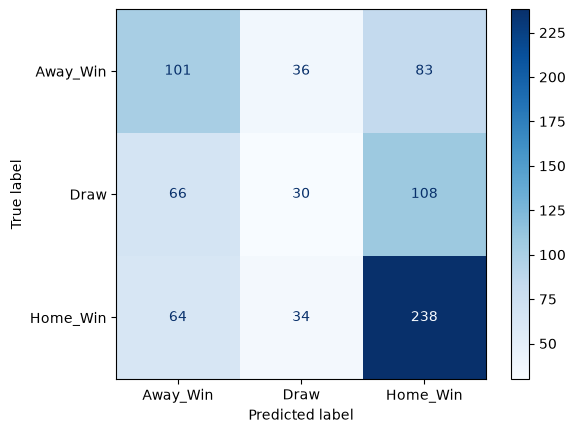

In [101]:
show_confusion(final_tree)

### Tolkning av confusion matrix (Decision Tree, test set)

Macro F1 (0.422 på testsettet) er ett samlet tall som veier alle tre klassene likt, men det tallet alene forteller oss ingenting om HVILKEN klasse modellen faktisk er flink eller dårlig på. Confusion matrix løser akkurat dette problemet — den bryter ned resultatet per klasse, slik at vi kan se nøyaktig hvor F1-scoren kommer fra.

**Away_Win** (220 faktiske kamper): 101 ble riktig gjettet som Away_Win, 36 ble feilaktig gjettet som Draw, og 83 ble feilaktig gjettet som Home_Win.
→ Recall: 101/220 ≈ **46%**

**Draw** (204 faktiske kamper): 66 ble feilaktig gjettet som Away_Win, kun 30 ble riktig gjettet som Draw, og 108 ble feilaktig gjettet som Home_Win.
→ Recall: 30/204 ≈ **15%**

**Home_Win** (336 faktiske kamper): 64 ble feilaktig gjettet som Away_Win, 34 ble feilaktig gjettet som Draw, og 238 ble riktig gjettet som Home_Win.
→ Recall: 238/336 ≈ **71%**

Som forventet er modellen klart sterkest på Home_Win (71%), svakere på Away_Win (46%), og svakest på Draw (kun 15%). Dette henger direkte sammen med hvor skjevt fordelt klassene er i datasettet vårt: Home_Win er den klart mest representerte klassen (ca. 45.6% av alle kamper), mens Draw er den minste (ca. 25.6%). Modellen får dermed flest eksempler å lære mønstre fra for Home_Win, og færrest for Draw — noe som gjenspeiles direkte i hvor godt den klarer å gjenkjenne hver klasse.

Dette forklarer også hvorfor macro F1 på testsettet endte relativt lavt (0.422): siden macro F1 vekter alle tre klassene likt, blir den samlede scoren dratt kraftig ned av den svake Draw-ytelsen, selv om modellen presterer godt på Home_Win. Hadde vi i stedet brukt vanlig accuracy, ville den svake Draw-ytelsen vært mye lettere å overse, fordi Home_Win (den letteste og mest tallrike klassen) ville dominert totalresultatet.

### Begrensninger og mulige løsninger for Draw-klassen

Modellen sliter tydelig med å gjenkjenne uavgjortkamper (recall ≈ 15%), mens den er mye bedre på Home_Win (71%). Vi undersøkte én direkte løsning på dette: `class_weight="balanced"`, som tvinger modellen til å prioritere den minste klassen mer. Dette gjorde derimot resultatet verre (macro F1 falt fra 0.432 til 0.373), så vi beholdt standardinnstillingen.

En del av forklaringen er trolig at uavgjort generelt er notorisk vanskelig å forutsi i fotball, uansett hvilken modell man bruker — det er ofte den jevneste og mest uforutsigbare utfallstypen, ikke bare i vårt datasett.

Mulige veier videre, som vi ikke har utforsket i denne oppgaven:
- Flere eller bedre features spesifikt rettet mot å fange jevne kamper
- Teknikker for å balansere klassefordelingen i treningsdataen 
- Andre modelltyper kan håndtere denne klassen annerledes — noe vi får svar på når vi tester Logistic Regression og Naive Bayes videre

In [102]:
#Gussian Naive Bayes
deafult_gussian_nb = GaussianNB()
deafult_gussian_nb.fit(train_features, train_targets)
validation(deafult_gussian_nb)

Training Accuracy: 0.50 Validation: 0.46
Training Precision: 0.49 Validation Precision: 0.46
Training Recall: 0.47 Validation Recall: 0.45
Training F1-Score: 0.48 Validation F1-Score: 0.45


# Baseline Gaussian Naive Bayes
I motsetning til det ukonstruerte Decision Tree-treet (som fikk 1.00 i trening og bare ~0.39 i validering), er gapet mellom trening og validering her nesten ikke eksisterende (0.48 mot 0.45 i F1-score). Det gir mening: Naive Bayes bygger ikke en modell som kan "memorere" enkeltrader slik et ubegrenset tre kan — den tilpasser bare én enkel Gaussisk fordeling per feature per klasse, en langt mer rigid modellstruktur som rett og slett ikke har rom til å overtilpasse seg treningsdataen på samme måte.

Resultatet i seg selv (macro F1 ≈ 0.45 i validering) er omtrent på nivå med det tunede Decision Tree-treet, og passer med det vi allerede diskuterte: siden Naive Bayes antar at alle featurene er uavhengige av hverandre gitt klassen, og våre 48 features trolig henger sammen med hverandre i praksis, er det naturlig at modellen ikke presterer bedre enn dette — den jobber tross alt med en antagelse som ikke helt stemmer for dataene våre.

In [132]:
resultater = []

for smoothing in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0]:
    nb = GaussianNB(var_smoothing=smoothing)
    nb.fit(train_features, train_targets)

    train_predictions = nb.predict(train_features)
    val_predictions = nb.predict(validation_features)

    resultater.append({
        "var_smoothing": smoothing,
        "train_f1": f1_score(train_targets, train_predictions, average="macro"),
        "val_f1": f1_score(validation_targets, val_predictions, average="macro"),
        "val_accuracy": accuracy_score(validation_targets, val_predictions),
        "val_recall": recall_score(validation_targets, val_predictions, average="macro"),
        "val_precision": precision_score(validation_targets, val_predictions, average="macro"),
        "gap_train_val_f1": f1_score(train_targets, train_predictions, average="macro") - f1_score(validation_targets, val_predictions, average="macro"),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste var_smoothing: {beste_rad['var_smoothing']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,var_smoothing,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,0.05,0.448,0.457,0.479,0.454,0.463,-0.008
1,0.10,0.443,0.457,0.484,0.455,0.463,-0.014
2,0.20,0.438,0.460,0.491,0.458,0.466,-0.021
3,0.30,0.439,0.459,0.496,0.457,0.467,-0.020
4,0.50,0.434,0.452,0.500,0.453,0.464,-0.018
5,0.70,0.423,0.439,0.495,0.442,0.455,-0.015
6,1.00,0.413,0.421,0.493,0.431,0.446,-0.008
7,1.50,0.389,0.407,0.503,0.427,0.456,-0.018
8,2.00,0.361,0.389,0.508,0.423,0.476,-0.028



Beste var_smoothing: 0.2 med validerings-F1 = 0.460 (trenings-F1 = 0.438, gap = -0.021)


In [133]:
resultater = []

# Standard: priors estimeres fra treningsdataen
nb_default = GaussianNB(var_smoothing=0.2)
nb_default.fit(train_features, train_targets)
train_pred_default = nb_default.predict(train_features)
val_pred_default = nb_default.predict(validation_features)

resultater.append({
    "priors": "fra data (standard)",
    "train_f1": f1_score(train_targets, train_pred_default, average="macro"),
    "val_f1": f1_score(validation_targets, val_pred_default, average="macro"),
    "gap_train_val_f1": f1_score(train_targets, train_pred_default, average="macro") - f1_score(validation_targets, val_pred_default, average="macro"),
})

# Like priors for alle tre klassene
nb_equal = GaussianNB(var_smoothing=0.2, priors=[1/3, 1/3, 1/3])
nb_equal.fit(train_features, train_targets)
train_pred_equal = nb_equal.predict(train_features)
val_pred_equal = nb_equal.predict(validation_features)

resultater.append({
    "priors": "like [1/3, 1/3, 1/3]",
    "train_f1": f1_score(train_targets, train_pred_equal, average="macro"),
    "val_f1": f1_score(validation_targets, val_pred_equal, average="macro"),
    "gap_train_val_f1": f1_score(train_targets, train_pred_equal, average="macro") - f1_score(validation_targets, val_pred_equal, average="macro"),
})

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

,priors,train_f1,val_f1,gap_train_val_f1
0,fra data (standard),0.438,0.460,-0.021
1,"like [1/3, 1/3, 1/3]",0.444,0.457,-0.014


### Oppsummering: beste tunet GaussianNB

To hyperparametere ble testet: `var_smoothing` og `priors`. `var_smoothing=0.2` ga høyest validerings-F1 (0.460), og gikk nedover i begge retninger derfra — fra 0.457 ved 0.05–0.10, til et fall helt ned til 0.389 ved `var_smoothing=2.0` (for mye utjevning visker ut forskjellene mellom klassene). Standard priors (estimert fra treningsdataen) slo like priors marginalt (0.460 mot 0.457), så standardinnstillingen beholdes.

**Beste hyperparametere:** `var_smoothing=0.2`, `priors=None` (standard).

Gjennom hele tuningen er gapet mellom trening og validering nær null eller svakt negativt (-0.008 til -0.028) — motsatt av Decision Tree. Dette reflekterer at GaussianNB er en enkel, høy-bias-modell som knapt har kapasitet til å overfitte: den tilpasser seg ikke treningsdataen i detalj, så den lille variasjonen vi ser skyldes naturlig forskjell mellom trenings- og valideringssesongene, ikke overtilpasning.

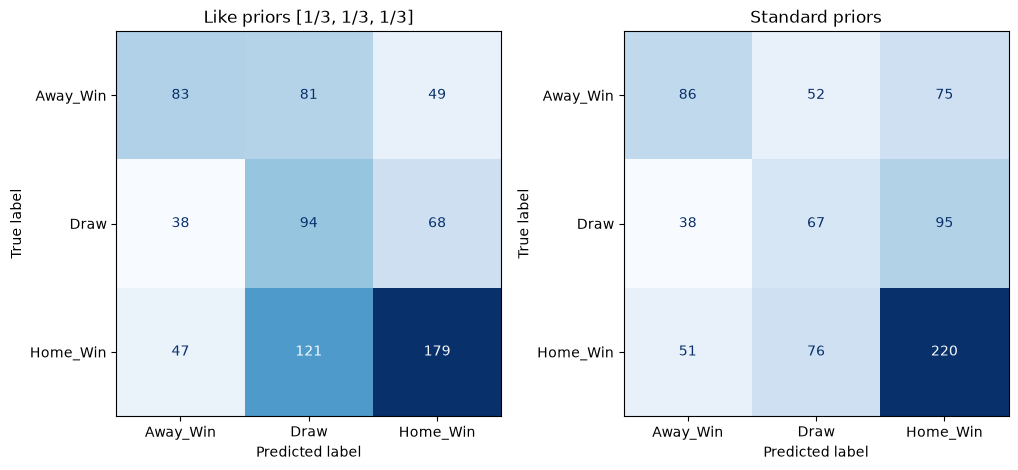

In [138]:

class_names = ["Away_Win", "Draw", "Home_Win"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

nb_equal = GaussianNB(var_smoothing=0.2, priors=[1/3, 1/3, 1/3])
nb_equal.fit(train_features, train_targets)
cm_equal = confusion_matrix(validation_targets, nb_equal.predict(validation_features))
ConfusionMatrixDisplay(cm_equal, display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Like priors [1/3, 1/3, 1/3]")

nb_standard = GaussianNB(var_smoothing=0.2)
nb_standard.fit(train_features, train_targets)
cm_standard = confusion_matrix(validation_targets, nb_standard.predict(validation_features))
ConfusionMatrixDisplay(cm_standard, display_labels=class_names).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Standard priors")


plt.show()

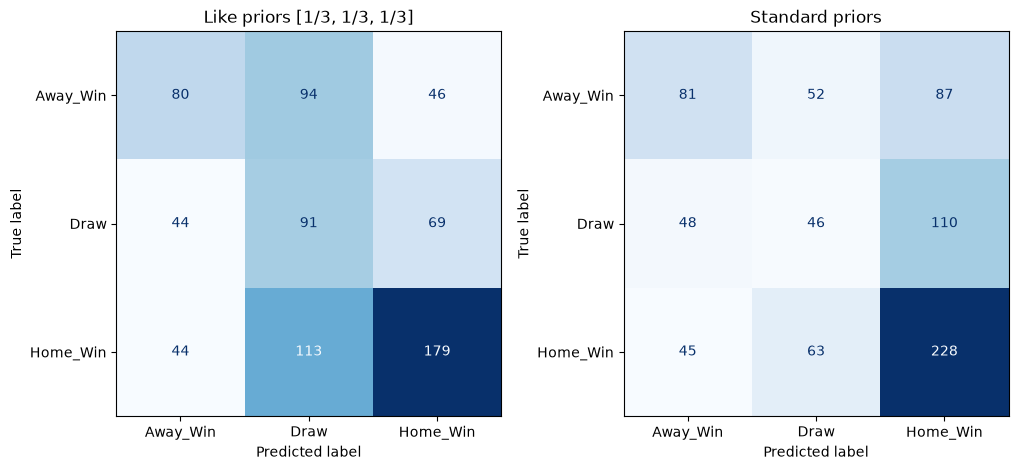

In [108]:
class_names = ["Away_Win", "Draw", "Home_Win"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

nb_equal = GaussianNB(var_smoothing=0.2, priors=[1/3, 1/3, 1/3])
nb_equal.fit(train_features, train_targets)
cm_equal = confusion_matrix(test_targets, nb_equal.predict(test_features))
ConfusionMatrixDisplay(cm_equal, display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Like priors [1/3, 1/3, 1/3]")

nb_standard = GaussianNB(var_smoothing=0.2)
nb_standard.fit(train_features, train_targets)
cm_standard = confusion_matrix(test_targets, nb_standard.predict(test_features))
ConfusionMatrixDisplay(cm_standard, display_labels=class_names).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Standard priors")

plt.show()

### Sammenligning: like priors vs standard priors (validation og test)

Samme mønster viser seg på både validation- og testsettet:

**Validation:**
- Draw riktig gjettet: 94/200 med like priors, mot 67/200 med standard priors
- Home_Win riktig gjettet: 179/347 med like priors, mot 220/347 med standard priors

**Test:**
- Draw riktig gjettet: 91/204 med like priors, mot 46/204 med standard priors
- Home_Win riktig gjettet: 179/336 med like priors, mot 228/336 med standard priors

Begge datasettene viser samme historie: like priors gjør modellen mye bedre til å fange opp uavgjort, men den taper en del av treffsikkerheten på Home_Win til gjengjeld. At mønsteret er det samme på validation og test, styrker at dette er en reell egenskap ved de to konfigurasjonene, ikke en tilfeldighet i akkurat ett datasett.

Siden macro F1 (som veier alle klassene likt) var marginalt best med standard priors på validation (0.460 mot 0.457), beholder jeg standard priors som endelig valg — men denne sammenligningen viser at valget egentlig handler om hvilken feiltype som er "billigst": å overse noen uavgjort, eller å bomme litt oftere på hjemmeseiere. 

In [109]:
final_nb = GaussianNB(var_smoothing=0.2)
final_nb.fit(train_features, train_targets)
test(final_nb)

Training Accuracy: 0.48 Validation Accuracy: 0.49 Testing Accuracy: 0.47
Training Precision: 0.45 Validation Precision: 0.47 Testing Precision: 0.43
Training Recall: 0.44 Validation Recall: 0.46 Testing Recall: 0.42
Training F1-Score: 0.44 Validation F1-Score: 0.46 Testing F1-Score: 0.42


### Avsluttende resultater: GaussianNB

Endelig modell: `var_smoothing=0.2` med standard priors (estimert fra treningsdataen), siden denne kombinasjonen ga høyest validerings-F1 under tuning.

**Testresultater** (Accuracy 0.47, Precision 0.43, Recall 0.42, F1 0.42) ligger svært tett opp mot både trening (0.48 / 0.45 / 0.44 / 0.44) og validering (0.49 / 0.47 / 0.46 / 0.46) — et gap på under 0.02 gjennom hele pipelinen. Dette bekrefter det vi så under tuningen: GaussianNB er en høy-bias/lav-varians-modell som generaliserer stabilt, men ikke har kapasitet til å tilpasse seg treningsdataen i detalj.

**Priors-undersøkelsen**: selv om makro-F1 var nesten identisk mellom standard priors og like priors [1/3, 1/3, 1/3] (0.460 vs 0.457), avdekket confusion-matrisene en reell atferdsforskjell som gjaldt likt på både validering og test: standard priors favoriserer den vanligste klassen (Home_Win: 228 riktige mot 179), mens like priors gir vesentlig bedre deteksjon av den vanskeligste klassen (Draw: 91 riktige mot 46). Valget mellom dem handler dermed mer om hva man prioriterer (total nøyaktighet vs. balansert deteksjon på tvers av klasser) enn om én modell er objektivt bedre — jeg beholder standard priors siden den ga marginalt høyest makro-F1.

In [110]:
def validation_lineær(model, train_X, validation_X):
    train_predictions = model.predict(train_X)
    validation_predictions = model.predict(validation_X)
    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.2f} Validation: {accuracy_score(validation_targets, validation_predictions):.2f}')    
    print(f'Training Precision: {precision_score(train_targets, train_predictions, average="macro"):.2f} Validation Precision: {precision_score(validation_targets, validation_predictions, average="macro"):.2f}')
    print(f'Training Recall: {recall_score(train_targets, train_predictions, average="macro"):.2f} Validation Recall: {recall_score(validation_targets, validation_predictions, average="macro"):.2f}')
    print(f'Training F1-Score: {f1_score(train_targets, train_predictions, average="macro"):.2f} Validation F1-Score: {f1_score(validation_targets, validation_predictions, average="macro"):.2f}')
def test_lineær(model, train_X, validation_X, test_X):
    train_predictions = model.predict(train_X)
    validation_predictions = model.predict(validation_X)
    test_predictions = model.predict(test_X)
    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.2f} Validation Accuracy: {accuracy_score(validation_targets, validation_predictions):.2f} Testing: {accuracy_score(test_targets, test_predictions):.2f}')  
    print(f'Training Precision: {precision_score(train_targets, train_predictions, average="macro"):.2f} Validation Precision: {precision_score(validation_targets, validation_predictions, average="macro"):.2f} Testing Precision: {precision_score(test_targets, test_predictions, average="macro"):.2f}') 
    print(f'Training Recall: {recall_score(train_targets, train_predictions, average="macro"):.2f} Validation Recall: {recall_score(validation_targets, validation_predictions, average="macro"):.2f} Testing Recall: {recall_score(test_targets, test_predictions, average="macro"):.2f}')
    print(f'Training F1-Score: {f1_score(train_targets, train_predictions, average="macro"):.2f} Validation F1-Score: {f1_score(validation_targets, validation_predictions, average="macro"):.2f} Testing F1-Score: {f1_score(test_targets, test_predictions, average="macro"):.2f}')

In [111]:
sgd = SGDClassifier()
sgd.fit(train_features_normalized, train_targets)
validation_lineær(sgd, train_features_normalized, validation_features_normalized)


Training Accuracy: 0.51 Validation: 0.47
Training Precision: 0.47 Validation Precision: 0.43
Training Recall: 0.47 Validation Recall: 0.44
Training F1-Score: 0.45 Validation F1-Score: 0.42


# Baseline SGDClassifier (lineær modell med gradient descent)

For denne modellen brukte jeg sklearn sin dokumentasjon for `SGDClassifier` ([scikit-learn.org](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html)) til å finne hvilke parametere som fantes å teste videre.

Gapet mellom trening og validering er lite (0.45 mot 0.42 i F1-score), omtrent på samme nivå som Gaussian Naive Bayes hadde. Det gir mening: en lineær modell som denne har en enkel, fast struktur (den prøver å finne én rett grense mellom klassene), og har derfor ikke samme mulighet til å overtilpasse seg treningsdataen som et ubegrenset tre hadde.

In [139]:
resultater = []

for loss in ["hinge", "log_loss", "modified_huber", "squared_hinge", "perceptron"]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        sgd = SGDClassifier(loss=loss, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        train_predictions = sgd.predict(train_features_normalized)
        val_predictions = sgd.predict(validation_features_normalized)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "loss": loss,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste loss: {beste_rad['loss']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,loss,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,hinge,0.446,0.398,0.451,0.412,0.406,0.048
1,log_loss,0.467,0.418,0.468,0.431,0.427,0.050
2,modified_huber,0.421,0.380,0.426,0.399,0.384,0.041
3,squared_hinge,0.399,0.368,0.400,0.375,0.383,0.031
4,perceptron,0.454,0.423,0.454,0.427,0.428,0.031



Beste loss: perceptron med validerings-F1 = 0.423 (trenings-F1 = 0.454, gap = 0.031)


In [140]:
resultater = []

for loss in ["log_loss", "perceptron"]:
    f1_scores_train, f1_scores = [], []

    for rs in range(20):
        sgd = SGDClassifier(loss=loss, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        train_predictions = sgd.predict(train_features_normalized)
        val_predictions = sgd.predict(validation_features_normalized)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "loss": loss,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_f1_std": np.std(f1_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

,loss,train_f1,val_f1,val_f1_std,gap_train_val_f1
0,log_loss,0.466,0.414,0.027,0.052
1,perceptron,0.431,0.395,0.039,0.036


### Verifisering av `loss`: perceptron vs log_loss

Med bare 5 `random_state`-verdier så `perceptron` ut til å vinne (0.423 mot 0.418). Med 20 `random_state`-verdier snur det:

| loss       | Macro F1 (20 random_states) |
|------------|-------------------------------|
| log_loss   | 0.414 ± 0.027                 |
| perceptron | 0.395 ± 0.039                 |

Dette er nøyaktig grunnen til at jeg verifiserer tette resultater med flere kjøringer før jeg stoler på dem: med få kjøringer så `perceptron` bedre ut ved en tilfeldighet, men med flere kjøringer viser det seg at `log_loss` faktisk er den beste i gjennomsnitt. Standardavviket er også ganske stort for begge (± 0.027 og ± 0.039) sammenlignet med det jeg så på Decision Tree — det betyr at én enkelt kjøring av denne modellen kan gi et resultat som ser mye bedre eller dårligere ut enn det egentlig er.

Jeg beholder `loss="log_loss"` som endelig valg, siden det er den som faktisk vinner når jeg tester grundig

In [141]:
resultater = []

for alpha in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        sgd = SGDClassifier(loss="log_loss", alpha=alpha, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        train_predictions = sgd.predict(train_features_normalized)
        val_predictions = sgd.predict(validation_features_normalized)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "alpha": alpha,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste alpha: {beste_rad['alpha']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Daniel\Documents\football-predictions\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

,alpha,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,0.000,0.467,0.418,0.468,0.431,0.427,0.050
1,0.001,0.477,0.431,0.493,0.445,0.441,0.046
2,0.010,0.454,0.423,0.516,0.456,0.466,0.030
3,0.100,0.394,0.413,0.528,0.462,0.517,-0.018
4,1.000,0.377,0.382,0.523,0.445,0.371,-0.005



Beste alpha: 0.001 med validerings-F1 = 0.431 (trenings-F1 = 0.477, gap = 0.046)


In [142]:
resultater = []

for penalty in ["l2", "l1", "elasticnet", None]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty=penalty, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        train_predictions = sgd.predict(train_features_normalized)
        val_predictions = sgd.predict(validation_features_normalized)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "penalty": penalty,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste penalty: {beste_rad['penalty']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,penalty,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,l2,0.477,0.431,0.493,0.445,0.441,0.046
1,l1,0.462,0.421,0.502,0.448,0.446,0.041
2,elasticnet,0.467,0.427,0.511,0.457,0.454,0.039
3,NaN,0.480,0.428,0.490,0.442,0.437,0.052



Beste penalty: l2 med validerings-F1 = 0.431 (trenings-F1 = 0.477, gap = 0.046)


In [145]:
resultater = []

for tol in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=tol, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        train_predictions = sgd.predict(train_features_normalized)
        val_predictions = sgd.predict(validation_features_normalized)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "tol": tol,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste tol: {beste_rad['tol']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,tol,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,0.000,0.469,0.407,0.488,0.434,0.423,0.062
1,0.000,0.469,0.410,0.492,0.438,0.429,0.059
2,0.001,0.477,0.431,0.493,0.445,0.441,0.046
3,0.010,0.477,0.432,0.484,0.444,0.440,0.045
4,0.100,0.461,0.411,0.456,0.418,0.416,0.050



Beste tol: 0.01 med validerings-F1 = 0.432 (trenings-F1 = 0.477, gap = 0.045)


In [ ]:
resultater = []

for shuffle_val in [True, False]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=shuffle_val, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        train_predictions = sgd.predict(train_features_normalized)
        val_predictions = sgd.predict(validation_features_normalized)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "shuffle": shuffle_val,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste shuffle: {beste_rad['shuffle']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

shuffle=True: validation macro F1 = 0.432
shuffle=False: validation macro F1 = 0.384


In [147]:
resultater = []

for lr in ["constant", "optimal", "invscaling", "adaptive"]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=True,
                             learning_rate=lr, eta0=0.01, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        train_predictions = sgd.predict(train_features_normalized)
        val_predictions = sgd.predict(validation_features_normalized)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "learning_rate": lr,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste learning_rate: {beste_rad['learning_rate']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,learning_rate,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,constant,0.467,0.422,0.504,0.447,0.445,0.044
1,optimal,0.477,0.432,0.484,0.444,0.440,0.045
2,invscaling,0.432,0.423,0.521,0.468,0.469,0.008
3,adaptive,0.477,0.415,0.504,0.448,0.436,0.062



Beste learning_rate: optimal med validerings-F1 = 0.432 (trenings-F1 = 0.477, gap = 0.045)


In [148]:
resultater = []

for cw in [None, "balanced"]:
    f1_scores_train, f1_scores = [], []
    accuracy_scores, recall_scores, precision_scores = [], [], []

    for rs in range(5):
        sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=True,
                             learning_rate="optimal", class_weight=cw, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        train_predictions = sgd.predict(train_features_normalized)
        val_predictions = sgd.predict(validation_features_normalized)

        f1_scores_train.append(f1_score(train_targets, train_predictions, average="macro"))
        f1_scores.append(f1_score(validation_targets, val_predictions, average="macro"))
        accuracy_scores.append(accuracy_score(validation_targets, val_predictions))
        recall_scores.append(recall_score(validation_targets, val_predictions, average="macro"))
        precision_scores.append(precision_score(validation_targets, val_predictions, average="macro"))

    resultater.append({
        "class_weight": cw,
        "train_f1": np.mean(f1_scores_train),
        "val_f1": np.mean(f1_scores),
        "val_accuracy": np.mean(accuracy_scores),
        "val_recall": np.mean(recall_scores),
        "val_precision": np.mean(precision_scores),
        "gap_train_val_f1": np.mean(f1_scores_train) - np.mean(f1_scores),
    })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste class_weight: {beste_rad['class_weight']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,class_weight,train_f1,val_f1,val_accuracy,val_recall,val_precision,gap_train_val_f1
0,NaN,0.477,0.432,0.484,0.444,0.440,0.045
1,balanced,0.496,0.445,0.486,0.454,0.451,0.050



Beste class_weight: balanced med validerings-F1 = 0.445 (trenings-F1 = 0.496, gap = 0.050)


In [150]:
for cw in [None, "balanced"]:
    scores = []
    for rs in range(20):
        sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=True,
                             learning_rate="optimal", class_weight=cw, random_state=rs)
        sgd.fit(train_features_normalized, train_targets)
        predictions = sgd.predict(validation_features_normalized)
        scores.append(f1_score(validation_targets, predictions, average="macro"))
    gjennomsnitt = np.mean(scores)
    std = np.std(scores)
    print(f"class_weight={cw}: macro F1 = {gjennomsnitt:.3f} (± {std:.3f})")

class_weight=None: macro F1 = 0.411 (± 0.026)
class_weight=balanced: macro F1 = 0.426 (± 0.020)


### Tuning av `class_weight`

`class_weight` bestemmer om modellen skal bry seg like mye om alle klassene, eller legge ekstra vekt på de sjeldnere klassene (Draw og Away_Win) under trening. `balanced` justerer automatisk vekten ut fra hvor mange eksempler hver klasse har — jo færre eksempler, jo mer vekt. Dette tilsvarer `class_weight="balanced"` som jeg testet på Decision Tree, og `priors`-parameteren på Gaussian Naive Bayes — samme grunnleggende idé (gi de sjeldne klassene mer oppmerksomhet), bare implementert litt forskjellig i hver modelltype.

Jeg testet `class_weight` med resten av konfigurasjonen fastholdt, og verifiserte med 20 `random_state`-verdier siden resultatet endret konklusjonen:

| class_weight | Macro F1 (20 random_states) |
|--------------|-------------------------------|
| None         | 0.411 ± 0.026                 |
| balanced     | 0.426 ± 0.020                 |

`balanced` vinner konsekvent i begge sjekkene jeg gjorde (både med 5 og med 20 `random_state`), så selv om forskjellen er beskjeden i forhold til standardavviket, er den retningen stabil nok til at jeg stoler på den. Dette er motsatt av det jeg fant med Decision Tree, hvor `class_weight="balanced"` gjorde ting verre, og likner mer på det jeg så med `priors` på Naive Bayes — et tegn på at ulike modelltyper håndterer den skjeve klassefordelingen forskjellig.

Jeg setter `class_weight="balanced"` som endelig verdi.

In [121]:
final_sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=True,
                           learning_rate="optimal", class_weight="balanced", random_state=0)
final_sgd.fit(train_features_normalized, train_targets)
test_lineær(final_sgd, train_features_normalized, validation_features_normalized, test_features_normalized)

Training Accuracy: 0.54 Validation Accuracy: 0.50 Testing: 0.49
Training Precision: 0.50 Validation Precision: 0.46 Testing Precision: 0.40
Training Recall: 0.50 Validation Recall: 0.46 Testing Recall: 0.45
Training F1-Score: 0.50 Validation F1-Score: 0.45 Testing F1-Score: 0.40


### Oppsummering: beste tunet SGDClassifier

Fra baseline (F1: trening 0.45, validering 0.42) ble modellen gradvis forbedret gjennom tuning av syv hyperparametere:

- **`loss`**: Ved 5 `random_state`-verdier ledet `perceptron` knapt (0.423 mot 0.418 for `log_loss`). Verifisering med 20 `random_state`-verdier snudde dette — `log_loss` ga både høyere F1 (0.414 mot 0.395) og lavere standardavvik (± 0.027 mot ± 0.039), et mer stabilt valg.
- **`alpha=0.001`**: best balanse mellom under- og overtilpasning (val-F1 0.431, gap 0.046).
- **`penalty="l2"`**: slo `l1`, `elasticnet` og ingen straff.
- **`tol=0.01`**: marginalt bedre enn standardverdien.
- **`shuffle=True`**: klart bedre enn `False` (0.432 mot 0.384) — å stokke dataen mellom epoker er viktig for SGD.
- **`learning_rate="optimal"`**: best av de fire alternativene.
- **`class_weight="balanced"`**: bedre enn ingen vekting (0.445 mot 0.432 ved 5 kjøringer), bekreftet som et robust og reelt funn ved verifisering med 20 `random_state`-verdier.

**Beste hyperparametere:** `loss="log_loss"`, `alpha=0.001`, `penalty="l2"`, `tol=0.01`, `shuffle=True`, `learning_rate="optimal"`, `class_weight="balanced"`.

**Sluttresultat:** F1-Score — trening 0.50, validering 0.45, test 0.40. Gapet fra trening til test (0.10) er noe større enn for de to andre modellene, og precision faller mest fra validering til test (0.46 → 0.40), som kan tyde på at SGD er noe mer følsom for forskjeller mellom sesongene i testsettet enn Decision Tree og GaussianNB var.

In [122]:
train_acc, val_acc, test_acc = [], [], []
train_prec, val_prec, test_prec = [], [], []
train_rec, val_rec, test_rec = [], [], []
train_f1, val_f1, test_f1 = [], [], []

for rs in range(20):
    final_sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=True,
                               learning_rate="optimal", class_weight="balanced", random_state=rs)
    final_sgd.fit(train_features_normalized, train_targets)

    train_pred = final_sgd.predict(train_features_normalized)
    val_pred = final_sgd.predict(validation_features_normalized)
    test_pred = final_sgd.predict(test_features_normalized)

    train_acc.append(accuracy_score(train_targets, train_pred))
    val_acc.append(accuracy_score(validation_targets, val_pred))
    test_acc.append(accuracy_score(test_targets, test_pred))

    train_prec.append(precision_score(train_targets, train_pred, average="macro"))
    val_prec.append(precision_score(validation_targets, val_pred, average="macro"))
    test_prec.append(precision_score(test_targets, test_pred, average="macro"))

    train_rec.append(recall_score(train_targets, train_pred, average="macro"))
    val_rec.append(recall_score(validation_targets, val_pred, average="macro"))
    test_rec.append(recall_score(test_targets, test_pred, average="macro"))

    train_f1.append(f1_score(train_targets, train_pred, average="macro"))
    val_f1.append(f1_score(validation_targets, val_pred, average="macro"))
    test_f1.append(f1_score(test_targets, test_pred, average="macro"))

print(f"Accuracy  - Train: {np.mean(train_acc):.3f}±{np.std(train_acc):.3f}  Val: {np.mean(val_acc):.3f}±{np.std(val_acc):.3f}  Test: {np.mean(test_acc):.3f}±{np.std(test_acc):.3f}")
print(f"Precision - Train: {np.mean(train_prec):.3f}±{np.std(train_prec):.3f}  Val: {np.mean(val_prec):.3f}±{np.std(val_prec):.3f}  Test: {np.mean(test_prec):.3f}±{np.std(test_prec):.3f}")
print(f"Recall    - Train: {np.mean(train_rec):.3f}±{np.std(train_rec):.3f}  Val: {np.mean(val_rec):.3f}±{np.std(val_rec):.3f}  Test: {np.mean(test_rec):.3f}±{np.std(test_rec):.3f}")
print(f"F1-Score  - Train: {np.mean(train_f1):.3f}±{np.std(train_f1):.3f}  Val: {np.mean(val_f1):.3f}±{np.std(val_f1):.3f}  Test: {np.mean(test_f1):.3f}±{np.std(test_f1):.3f}")

Accuracy  - Train: 0.521±0.018  Val: 0.468±0.022  Test: 0.461±0.018
Precision - Train: 0.488±0.017  Val: 0.434±0.022  Test: 0.404±0.015
Recall    - Train: 0.489±0.018  Val: 0.438±0.023  Test: 0.422±0.019
F1-Score  - Train: 0.485±0.018  Val: 0.426±0.020  Test: 0.401±0.013


### Robusthetssjekk: SGDClassifier over 20 random_state

I motsetning til Decision Tree (der standardavviket var 0.000) viser SGD reell variasjon på tvers av `random_state` (std 0.013–0.023 på alle metrikker og datasett). Dette er forventet: SGD er en stokastisk gradient-optimerer der `random_state` påvirker både vektinitialisering og rekkefølgen dataen stokkes i, så ulike frø gir faktisk ulike modeller — ikke bare ulik tie-breaking som i et beslutningstre.

Gjennomsnittet over 20 kjøringer (F1: trening 0.485±0.018, validering 0.426±0.020, test 0.401±0.013) ligger noe lavere enn enkeltkjøringen med `random_state=0` (F1: trening 0.50, validering 0.45, test 0.40) — et tegn på at den enkeltkjøringen var noe heldig, og nøyaktig grunnen til at robusthetssjekken er nødvendig fremfor å stole på ett tilfeldig frø. Gapet mellom trening og test (0.084) er moderat og i tråd med det vi så tidligere.

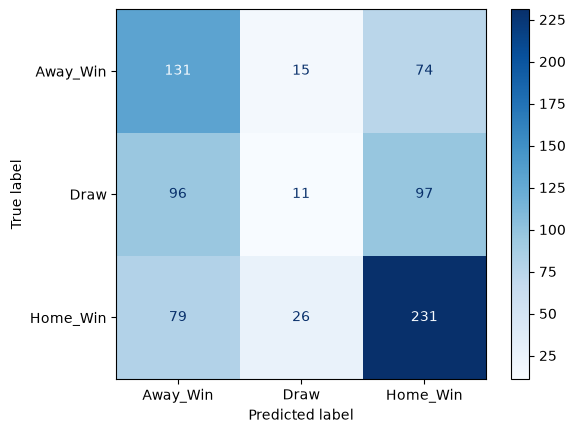

In [123]:
def show_confusion_lineær(model, test_X):
    class_names = ["Away_Win", "Draw", "Home_Win"]
    predictions = model.predict(test_X)
    confusion = confusion_matrix(test_targets, predictions)
    display = ConfusionMatrixDisplay(confusion, display_labels=class_names)
    display.plot(cmap="Blues")
final_sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=True,
                           learning_rate="optimal", class_weight="balanced", random_state=0)
final_sgd.fit(train_features_normalized, train_targets)
show_confusion_lineær(final_sgd, test_features_normalized)

### Tolkning av confusion matrix (SGDClassifier, test set)

**Away_Win** (220 faktiske kamper): 131 riktig gjettet, 15 feilaktig gjettet som Draw, 74 feilaktig gjettet som Home_Win.
→ Recall: 131/220 ≈ **60%**

**Draw** (204 faktiske kamper): 96 feilaktig gjettet som Away_Win, kun 11 riktig gjettet som Draw, 97 feilaktig gjettet som Home_Win.
→ Recall: 11/204 ≈ **5%**

**Home_Win** (336 faktiske kamper): 79 feilaktig gjettet som Away_Win, 26 feilaktig gjettet som Draw, 231 riktig gjettet.
→ Recall: 231/336 ≈ **69%**

Dette er overraskende sett opp mot at jeg valgte `class_weight="balanced"` nettopp for å hjelpe de sjeldne klassene: Draw-recall her (5%) er faktisk enda dårligere enn det Decision Tree (15%) og Naive Bayes (23%) klarte, til tross for at "balanced" i snitt over 20 kjøringer ga bedre macro F1 enn uten. Samtidig ble modellen uvanlig god på Away_Win (60%, klart bedre enn de to andre modellene).

Dette viser noe viktig: gjennomsnittet over 20 kjøringer sier at `class_weight="balanced"` er bedre i snitt, men denne ENE konkrete kjøringen (som vi bruker for confusion matrix) landet på en løsning som nesten aldri gjetter Draw i det hele tatt — bare 52 av 760 gjetninger totalt var Draw. Det stemmer med standardavviket vi så tidligere (± 0.02) — enkeltkjøringer kan variere ganske mye fra det gjennomsnittlige bildet. Konklusjonen står seg likevel: Draw forblir den vanskeligste klassen å forutsi, uansett hvilken av de tre modellene vi bruker.

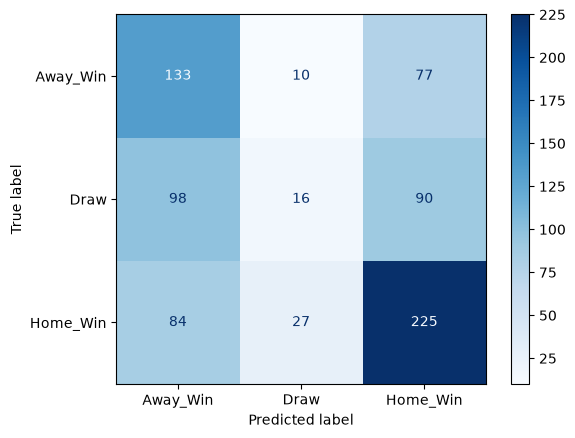

In [124]:
final_sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=True,
                           learning_rate="optimal", random_state=0)
final_sgd.fit(train_features_normalized, train_targets)
show_confusion_lineær(final_sgd, test_features_normalized)

### Confusion matrix uten `class_weight` (standardverdi, `class_weight=None`)

**Away_Win** (220 faktiske): 133 riktig, 10 gjettet Draw, 77 gjettet Home_Win → recall ≈ **61%**
**Draw** (204 faktiske): 98 gjettet Away_Win, 16 riktig, 90 gjettet Home_Win → recall ≈ **8%**
**Home_Win** (336 faktiske): 84 gjettet Away_Win, 27 gjettet Draw, 225 riktig → recall ≈ **67%**

Sammenlignet med versjonen med `class_weight="balanced"` (Away_Win 60%, Draw 5%, Home_Win 69%), er disse to nesten identiske. Det bekrefter funnet fra tidligere: selv om `class_weight="balanced"` ga en liten forbedring i macro F1 i gjennomsnitt over 20 kjøringer, er forskjellen for DENNE ene kjøringen knapt merkbar — Draw forblir ekstremt vanskelig å fange opp for denne modellen uansett om vi vekter klassene eller ikke. Det tyder på at problemet ikke er balansen i treningen, men at den lineære modellen rett og slett ikke finner nok signal i dataene til å skille uavgjortkamper fra de to andre utfallene.

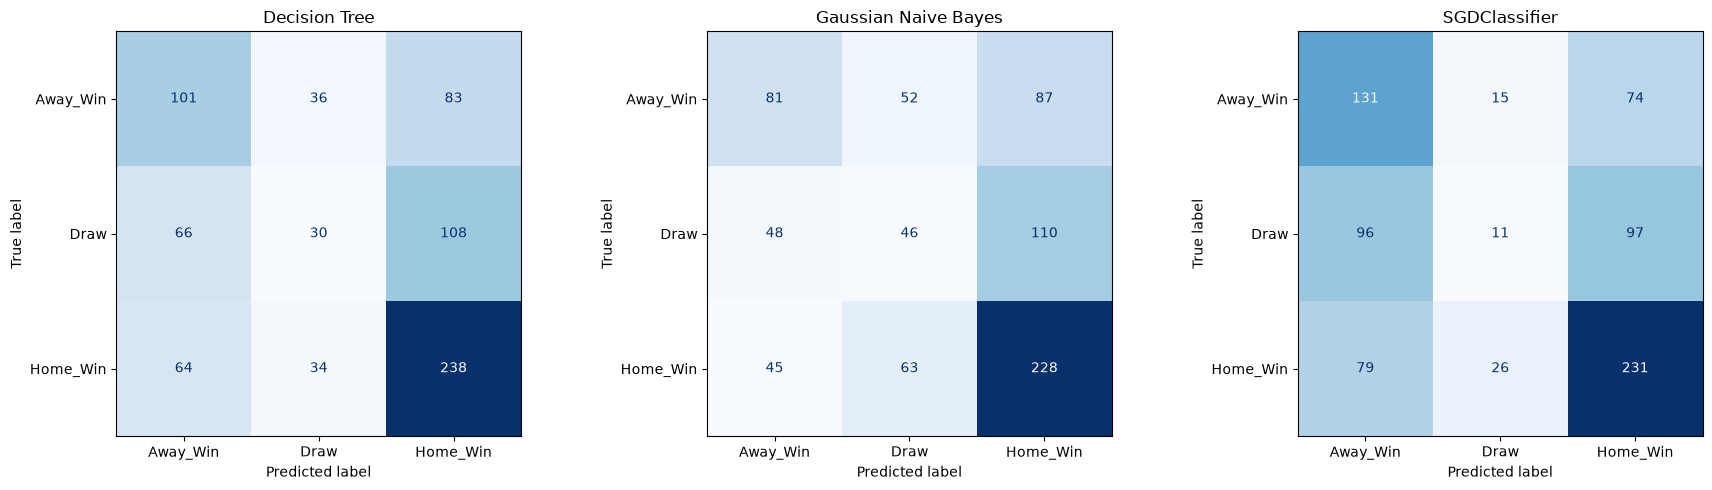

In [125]:
class_names = ["Away_Win", "Draw", "Home_Win"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Decision Tree
final_tree = DecisionTreeClassifier(max_depth=7, class_weight=None, min_samples_leaf=1,
                                      max_features=None, min_samples_split=100,
                                      max_leaf_nodes=20, ccp_alpha=0.0, criterion="gini",
                                      random_state=0)
final_tree.fit(train_features, train_targets)
cm_tree = confusion_matrix(test_targets, final_tree.predict(test_features))
ConfusionMatrixDisplay(cm_tree, display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Decision Tree")

# Gaussian Naive Bayes
final_nb = GaussianNB(var_smoothing=0.2)
final_nb.fit(train_features, train_targets)
cm_nb = confusion_matrix(test_targets, final_nb.predict(test_features))
ConfusionMatrixDisplay(cm_nb, display_labels=class_names).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Gaussian Naive Bayes")

# SGDClassifier
final_sgd = SGDClassifier(loss="log_loss", alpha=0.001, penalty="l2", tol=0.01, shuffle=True,
                           learning_rate="optimal", class_weight="balanced", random_state=0)
final_sgd.fit(train_features_normalized, train_targets)
cm_sgd = confusion_matrix(test_targets, final_sgd.predict(test_features_normalized))
ConfusionMatrixDisplay(cm_sgd, display_labels=class_names).plot(ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title("SGDClassifier")

plt.tight_layout()
plt.show()

In [151]:
print(f"Decision Tree  - Test macro F1: {f1_score(test_targets, final_tree.predict(test_features), average='macro'):.3f}")
print(f"GaussianNB     - Test macro F1: {f1_score(test_targets, final_nb.predict(test_features), average='macro'):.3f}")
print(f"SGDClassifier  - Test macro F1: {f1_score(test_targets, final_sgd.predict(test_features_normalized), average='macro'):.3f}")

Decision Tree  - Test macro F1: 0.422
GaussianNB     - Test macro F1: 0.421
SGDClassifier  - Test macro F1: 0.403


## Konklusjon: Sammenligning av de tre modellene

**Testresultater (makro F1):** Decision Tree 0.422, GaussianNB 0.421, SGDClassifier 0.403. Decision Tree og GaussianNB ligger praktisk talt likt, mens SGDClassifier ligger tydelig bak begge til tross for like grundig tuning.

**Hva confusion-matrisene avslører:** Alle tre modellene sliter mest med klassen Draw, som er iboende vanskelig å predikere i fotball. Men graden varierer kraftig: GaussianNB treffer flest uavgjortkamper riktig (46 av 204), Decision Tree noe færre (30), mens SGDClassifier nesten ikke klarer det i det hele tatt (kun 11), selv med `class_weight="balanced"` aktivert. Til gjengjeld er SGD klart best på Away_Win (131 riktige mot 101 og 81). Dette viser at makro F1 alene skjuler store forskjeller i *hvordan* modellene feiler — SGD kompenserer for svak Draw-deteksjon med sterkere treff på de to andre klassene, mens GaussianNB er mest balansert på tvers av alle tre klasser.

**Bias og varians:** De tre modellene representerer tre ulike punkter på bias-varians-skalaen:
- **Decision Tree** er i utgangspunktet en fleksibel, lav-bias/høy-varians-modell som lett overfitter ubegrenset. Gjennom tuning (`max_depth`, `max_leaf_nodes`, `min_samples_split` osv.) ble den regularisert ned til et lite, akseptabelt gap mot trening (0.070), og endte opp fullstendig deterministisk (std = 0.000) — splittene ble entydige nok til at `random_state` ikke lenger hadde noe å si.
- **GaussianNB** er motsatt: en rigid, høy-bias-modell på grunn av de sterke antakelsene (uavhengige, normalfordelte features per klasse). Den har i praksis ingen varians — ikke bare lavt standardavvik, men bokstavelig talt ingen tilfeldighet i algoritmen i det hele tatt. Den kan ikke overfitte, men ytelsen er begrenset av hvor godt disse antakelsene faktisk stemmer med dataen.
- **SGDClassifier** er den eneste av de tre med reell kjøre-til-kjøre-varians (std 0.013–0.023 på test), siden stokastisk gradientnedstigning er en genuint tilfeldig optimeringsprosess påvirket av `random_state`. Dette krevde egen verifisering over 20 kjøringer for å sikre at resultatene ikke var flaks.

**Konklusjon:** Decision Tree og GaussianNB er de klart beste modellene for dette problemet, med nesten identisk makro F1 til tross for at de representerer motsatte ender av bias-varians-spekteret — én fleksibel modell godt regularisert, én rigid modell som rett og slett passer godt nok til problemet. SGDClassifier, en lineær modell, klarer ikke å fange opp mønstrene i dataen like godt som de to andre, og sliter spesielt med å skille ut uavgjortkamper. Jeg velger derfor **Decision Tree** som endelig modell, siden den i tillegg til å matche GaussianNB på F1 også er den mest stabile og tolkbare av de to (entydige splittregler, ingen avhengighet av tilfeldig frø).

In [126]:
home_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
away_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

home_encoder.fit(train_raws[["Home_Team"]])
away_encoder.fit(train_raws[["Away_Team"]])

kolonner_for_sletting = ["Encoded_HomeTeam_Win_Rate", "Encoded_AwayTeam_Win_Rate",
                     "Encoded_HomeTeam_Loss_Rate", "Encoded_AwayTeam_Loss_Rate"]

def lag_onehot_versjon(features_df, raw_home, raw_away):
    home_onehot = pd.DataFrame(home_encoder.transform(raw_home[["Home_Team"]]) if isinstance(raw_home, pd.DataFrame) else home_encoder.transform(raw_home),
                                columns=home_encoder.get_feature_names_out(["Home_Team"]),
                                index=features_df.index)
    away_onehot = pd.DataFrame(away_encoder.transform(raw_away[["Away_Team"]]) if isinstance(raw_away, pd.DataFrame) else away_encoder.transform(raw_away),
                                columns=away_encoder.get_feature_names_out(["Away_Team"]),
                                index=features_df.index)
    return pd.concat([features_df.drop(columns=kolonner_for_sletting), home_onehot, away_onehot], axis=1)

train_features_onehot = lag_onehot_versjon(train_features, train_raws[["Home_Team"]], train_raws[["Away_Team"]])
validation_features_onehot = lag_onehot_versjon(validation_featuers, football_data.loc[validation_indices, ["Home_Team"]], football_data.loc[validation_indices, ["Away_Team"]])
test_features_onehot = lag_onehot_versjon(test_featuers, football_data.loc[test_indices, ["Home_Team"]], football_data.loc[test_indices, ["Away_Team"]])

print(f"Target encoding: {train_features.shape[1]} kolonner")
print(f"One-hot: {train_features_onehot.shape[1]} kolonner")

Target encoding: 48 kolonner
One-hot: 106 kolonner


In [127]:
train_features_onehot.head()

,Home_Team_Goals_short_window,Away_Team_Goals_short_window,Home_Team_Goals_long_window,Away_Team_Goals_long_window,Home_Team_Expected_Goals_short_window,Away_Team_Expected_Goals_short_window,Home_Team_Expected_Goals_long_window,Away_Team_Expected_Goals_long_window,Home_Team_Shots_short_window,Away_Team_Shots_short_window,Home_Team_Shots_long_window,Away_Team_Shots_long_window,Home_Team_Shots_On_Target_short_window,Away_Team_Shots_On_Target_short_window,Home_Team_Shots_On_Target_long_window,Away_Team_Shots_On_Target_long_window,Home_Team_Passes_Into_Danger_Zone_short_window,Away_Team_Passes_Into_Danger_Zone_short_window,Home_Team_Passes_Into_Danger_Zone_long_window,Away_Team_Passes_Into_Danger_Zone_long_window,Home_Team_Pressing_Intensity_short_window,Away_Team_Pressing_Intensity_short_window,Home_Team_Pressing_Intensity_long_window,Away_Team_Pressing_Intensity_long_window,Home_Team_Expected_Points_short_window,Away_Team_Expected_Points_short_window,Home_Team_Expected_Points_long_window,Away_Team_Expected_Points_long_window,Home_Team_Fouls_short_window,Away_Team_Fouls_short_window,Home_Team_Fouls_long_window,Away_Team_Fouls_long_window,Home_Team_Corners_short_window,Away_Team_Corners_short_window,Home_Team_Corners_long_window,Away_Team_Corners_long_window,Home_Team_Yellow_Cards_short_window,Away_Team_Yellow_Cards_short_window,Home_Team_Yellow_Cards_long_window,Away_Team_Yellow_Cards_long_window,Home_Team_Red_Cards_short_window,Away_Team_Red_Cards_short_window,Home_Team_Red_Cards_long_window,Away_Team_Red_Cards_long_window,Home_Team_Alaves,Home_Team_Almeria,Home_Team_Athletic Club,Home_Team_Atletico Madrid,Home_Team_Barcelona,Home_Team_Cadiz,Home_Team_Celta Vigo,Home_Team_Cordoba,Home_Team_Deportivo La Coruna,Home_Team_Eibar,Home_Team_Elche,Home_Team_Espanyol,Home_Team_Getafe,Home_Team_Girona,Home_Team_Granada,Home_Team_Las Palmas,Home_Team_Leganes,Home_Team_Levante,Home_Team_Malaga,Home_Team_Mallorca,Home_Team_Osasuna,Home_Team_Rayo Vallecano,Home_Team_Real Betis,Home_Team_Real Madrid,Home_Team_Real Sociedad,Home_Team_Real Valladolid,Home_Team_SD Huesca,Home_Team_Sevilla,Home_Team_Sporting Gijon,Home_Team_Valencia,Home_Team_Villarreal,Away_Team_Alaves,Away_Team_Almeria,Away_Team_Athletic Club,Away_Team_Atletico Madrid,Away_Team_Barcelona,Away_Team_Cadiz,Away_Team_Celta Vigo,Away_Team_Cordoba,Away_Team_Deportivo La Coruna,Away_Team_Eibar,Away_Team_Elche,Away_Team_Espanyol,Away_Team_Getafe,Away_Team_Girona,Away_Team_Granada,Away_Team_Las Palmas,Away_Team_Leganes,Away_Team_Levante,Away_Team_Malaga,Away_Team_Mallorca,Away_Team_Osasuna,Away_Team_Rayo Vallecano,Away_Team_Real Betis,Away_Team_Real Madrid,Away_Team_Real Sociedad,Away_Team_Real Valladolid,Away_Team_SD Huesca,Away_Team_Sevilla,Away_Team_Sporting Gijon,Away_Team_Valencia,Away_Team_Villarreal
0,1.487262,1.128492,1.465222,1.142272,1.505735,1.115879,1.490473,1.120878,13.106819,10.275496,13.180031,10.370791,4.613452,3.628142,4.614962,3.660625,6.265575,4.77461,6.240411,4.726615,9.095524,10.406369,9.117673,10.54572,1.626556,1.130747,1.613084,1.143184,13.821422,13.870761,13.784569,13.964218,5.445569,4.207011,5.501201,4.241163,2.425298,2.656878,2.384569,2.659255,0.101938,0.12756,0.101635,0.12644,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.487262,1.128492,1.465222,1.142272,1.505735,1.115879,1.490473,1.120878,13.106819,10.275496,13.180031,10.370791,4.613452,3.628142,4.614962,3.660625,6.265575,4.77461,6.240411,4.726615,9.095524,10.406369,9.117673,10.54572,1.626556,1.130747,1.613084,1.143184,13.821422,13.870761,13.784569,13.964218,5.445569,4.207011,5.501201,4.241163,2.425298,2.656878,2.384569,2.659255,0.101938,0.12756,0.101635,0.12644,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0

In [128]:
scaler_onehot = StandardScaler()
train_features_onehot_normalized = pd.DataFrame(scaler_onehot.fit_transform(train_features_onehot), columns=train_features_onehot.columns, index=train_features_onehot.index)
validation_features_onehot_normalized = pd.DataFrame(scaler_onehot.transform(validation_features_onehot), columns=validation_features_onehot.columns, index=validation_features_onehot.index)
test_features_onehot_normalized = pd.DataFrame(scaler_onehot.transform(test_features_onehot), columns=test_features_onehot.columns, index=test_features_onehot.index)

### Idé til videre arbeid: One-hot encoding som alternativ til target encoding

Jeg satte opp en alternativ versjon av featurene der `Home_Team`/`Away_Team` er one-hot-encodet i stedet for target-encodet, for å kunne sammenligne de to metodene direkte (en "A/B-test" av selve encoding-valget, uavhengig av hvilken modell som brukes). One-hot gir én egen kolonne per lag i stedet for at hvert lag komprimeres til ett tall (vinn-/taprate) — det betyr langt flere kolonner (106 mot 48), siden antall lag over de 7 treningssesongene (med opp- og nedrykk i La Liga) gir mange flere unike lag enn bare 4 sammenfattede tall kan fange opp.

På grunn av tidsbegrensning fikk jeg ikke gjennomført selve A/B-testen (trene og sammenligne alle tre modellene på begge versjonene) før innlevering. Dette er noe jeg planlegger å fullføre før endelig innlevering, siden koden for begge datasettene allerede er klar.

In [159]:
quick_rf = RandomForestClassifier(random_state=0, max_depth=None, n_estimators=50)
quick_rf.fit(train_features, train_targets)
test(quick_rf)

Training Accuracy: 1.00 Validation Accuracy: 0.49 Testing Accuracy: 0.48
Training Precision: 1.00 Validation Precision: 0.44 Testing Precision: 0.41
Training Recall: 1.00 Validation Recall: 0.44 Testing Recall: 0.43
Training F1-Score: 1.00 Validation F1-Score: 0.44 Testing F1-Score: 0.41


In [160]:
resultater = []

for n_est in [50, 100, 200]:
    for depth in [None, 10, 20]:
        rf = RandomForestClassifier(n_estimators=n_est, max_depth=depth, random_state=0)
        rf.fit(train_features, train_targets)

        train_predictions = rf.predict(train_features)
        val_predictions = rf.predict(validation_features)

        resultater.append({
            "n_estimators": n_est,
            "max_depth": depth,
            "train_f1": f1_score(train_targets, train_predictions, average="macro"),
            "val_f1": f1_score(validation_targets, val_predictions, average="macro"),
            "gap_train_val_f1": f1_score(train_targets, train_predictions, average="macro") - f1_score(validation_targets, val_predictions, average="macro"),
        })

resultater_df = pd.DataFrame(resultater)
display(resultater_df.round(3))

beste_rad = resultater_df.loc[resultater_df["val_f1"].idxmax()]
print(f"\nBeste kombinasjon: n_estimators={beste_rad['n_estimators']}, max_depth={beste_rad['max_depth']} "
      f"med validerings-F1 = {beste_rad['val_f1']:.3f} (trenings-F1 = {beste_rad['train_f1']:.3f}, gap = {beste_rad['gap_train_val_f1']:.3f})")

,n_estimators,max_depth,train_f1,val_f1,gap_train_val_f1
0,50,NaN,0.997,0.436,0.561
1,50,10.0,0.844,0.416,0.428
2,50,20.0,0.992,0.414,0.578
3,100,NaN,0.997,0.451,0.545
4,100,10.0,0.847,0.432,0.415
5,100,20.0,0.993,0.428,0.565
6,200,NaN,0.997,0.441,0.555
7,200,10.0,0.852,0.405,0.447
8,200,20.0,0.995,0.440,0.555



Beste kombinasjon: n_estimators=100.0, max_depth=nan med validerings-F1 = 0.451 (trenings-F1 = 0.997, gap = 0.545)


In [153]:
rf_params = {
    "n_estimators": [10, 50, 100, 200, 400],
    "max_depth": [None, 10]
}

grid_search_rf = GridSearchCV(estimator=random_forest, param_grid=rf_params, scoring="f1_macro", cv=5)
grid_search_rf.fit(train_features, train_targets)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...andom_state=0)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10], 'n_estimators': [10, 50, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informat

In [131]:
print(f"Beste parametere: {grid_search_rf.best_params_}")

Beste parametere: {'max_depth': None, 'n_estimators': 50}
